# NF-BoT-IoT-v3 — Phase 2 Data Understanding

Strict replication of `03_ton_completed.ipynb`. Reporting references: `docs/checks ds1.docx`, `docs/cyrine_phase2_prompt.md`, `docs/phase2_data_problems.pdf`. Steps 0–7 were executed on the full dataset; the findings below are filled in. No raw CSV is changed.

Run configuration/setup then Steps 0–7 in order, or Run all. Each major step contains the original source blocks in order; source cell IDs are retained. Completed compatible checkpoints restore results and replay outputs. Review findings before completing Step 8.


In [1]:


# CONFIGURATION — Google Drive paths

CSV_PATH = '/content/drive/MyDrive/DS/seconddataset /NF-BoT-IoT-v3.csv'

FEATURE_DICTIONARY_PATH = '/content/drive/MyDrive/DS/seconddataset /NetFlow_v3_Features.csv'

CHECKPOINT_DIR = '/content/drive/MyDrive/DS/BoT_phase2_checkpoints'

FORCE_RERUN_STEPS = set()



In [2]:
import os

print("BoT dataset:", os.path.isfile(CSV_PATH))
print("Feature dictionary:", os.path.isfile(FEATURE_DICTIONARY_PATH))


BoT dataset: False
Feature dictionary: False


In [3]:
from google.colab import drive
drive.mount('/content/drive')
%pip -q install duckdb
import os, sys, json, pickle, hashlib, uuid, platform, importlib.metadata, gc, copy
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display as ipy_display
from IPython.utils.capture import capture_output
%matplotlib inline
path = str(Path(CSV_PATH).resolve())
dictionary_path = str(Path(FEATURE_DICTIONARY_PATH).resolve())
checkpoint_root = Path(CHECKPOINT_DIR).resolve()
for filename in (path, dictionary_path):
    if not Path(filename).is_file():
        raise FileNotFoundError(f'Configure the existing Drive file: {filename}')
    if checkpoint_root == Path(filename) or checkpoint_root in Path(filename).parents:
        raise ValueError('Checkpoint folder must not contain an input file')
if not set(FORCE_RERUN_STEPS).issubset(set(range(8))):
    raise ValueError('Force step numbers must be 0–7')
checkpoint_root.mkdir(parents=True, exist_ok=True)
def digest(filename):
    h = hashlib.sha256()
    with open(filename, 'rb') as stream:
        for block in iter(lambda: stream.read(8*1024*1024), b''):
            h.update(block)
    return h.hexdigest()
def identity(filename):
    before = Path(filename).stat()
    sha = digest(filename)
    after = Path(filename).stat()
    if (before.st_size, before.st_mtime_ns) != (after.st_size, after.st_mtime_ns):
        raise RuntimeError('Input changed during fingerprinting')
    return dict(path=filename, size=after.st_size, mtime=after.st_mtime_ns, sha256=sha)
print('Streaming full SHA-256 fingerprints; Drive I/O may take several minutes.')
INPUTS = [identity(path), identity(dictionary_path)]
VERSIONS = {n: importlib.metadata.version(n) for n in
            ['pandas','numpy','duckdb','matplotlib','seaborn','ipython']}
VERSIONS['python'] = platform.python_version()
STATE = {}
ARTIFACTS = {}


Mounted at /content/drive
Streaming full SHA-256 fingerprints; Drive I/O may take several minutes.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
def inputs_unchanged():
    for item in INPUTS:
        stat = Path(item['path']).stat()
        if (stat.st_size, stat.st_mtime_ns) != (item['size'], item['mtime']):
            raise RuntimeError('Input changed: rerun setup to fingerprint again')
def replay(records):
    for item in records:
        print(f"\n--- Reference cell {item['cell']} ---")
        print(item['stdout'], end='')
        if item['stderr']:
            print(item['stderr'], end='', file=sys.stderr)
        for output in item['rich']:
            ipy_display(output['data'], raw=True, metadata=output['metadata'])
def summaries(ns):
    out = {}
    for name, value in ns.items():
        if name.startswith('_') or name in {'chunk','numeric','values','x','group','rows','features','behaviour','sample_df'}:
            continue
        if isinstance(value,(pd.DataFrame,pd.Series)) and value.size <= 100_000:
            out[name] = value.copy(deep=True)
        elif isinstance(value,np.ndarray) and value.size <= 10_000:
            out[name] = value.copy()
        elif isinstance(value,(str,int,float,bool,np.generic)):
            out[name] = value
        elif isinstance(value,(dict,list,tuple,set)) and len(value) <= 200:
            seq = value.values() if isinstance(value,dict) else value
            if all(isinstance(v,(str,int,float,bool,np.generic,type(None))) for v in seq):
                out[name] = copy.deepcopy(value)
    return out
def run_step(step):
    inputs_unchanged()
    if any(i not in ARTIFACTS for i in range(step)):
        raise RuntimeError('Run all preceding steps first')
    provenance = dict(format=1,step=step,inputs=INPUTS,versions=VERSIONS,
        method=METHOD_DIGEST,runner=RUNNER_DIGEST,
        dependencies={str(i):ARTIFACTS[i]['generation'] for i in range(step)})
    signature = hashlib.sha256(json.dumps(provenance,sort_keys=True).encode()).hexdigest()
    folder = checkpoint_root / f'step_{step}'
    marker = folder / 'complete.json'
    forced = bool(FORCE_RERUN_STEPS) and step >= min(FORCE_RERUN_STEPS)
    for names in KEEP[step:]:
        for name in names:
            STATE.pop(name,None)
    for i in list(ARTIFACTS):
        if i >= step:
            del ARTIFACTS[i]
    if marker.exists() and not forced:
        try:
            manifest = json.loads(marker.read_text())
            if manifest['signature'] != signature:
                raise ValueError('Incompatible inputs/code/versions/dependencies')
            saved = folder / manifest['payload']
            if saved.parent != folder or digest(saved) != manifest['sha256']:
                raise ValueError('Checkpoint path/checksum mismatch')
            with open(saved,'rb') as stream:
                payload = pickle.load(stream)
            if payload['signature'] != signature or set(payload['state']) != set(KEEP[step]):
                raise ValueError('Incomplete/incompatible state')
            if len(payload['records']) != len(BLOCKS[step]):
                raise ValueError('Incomplete outputs')
            STATE.update(payload['state'])
            ARTIFACTS[step] = manifest
            print(f'Step {step}: restored completed checkpoint')
            replay(payload['records'])
            return
        except Exception as exc:
            print(f'Checkpoint refused: {exc}. Recomputing Step {step}.')
    ns = dict(__name__='__bot_analysis__',path=path,dictionary_path=dictionary_path,
              CSV_PATH=path,FEATURE_DICTIONARY_PATH=dictionary_path,
              pd=pd,np=np,plt=plt,sns=sns,os=os,**STATE)
    records = []
    for cell, source in BLOCKS[step]:
        tables = []
        def preserved_display(*objects,**kwargs):
            for obj in objects:
                if isinstance(obj,(pd.DataFrame,pd.Series)):
                    tables.append(obj.copy(deep=True))
            return ipy_display(*objects,**kwargs)
        ns['display'] = preserved_display
        print(f'Step {step}, reference cell {cell}: running')
        try:
            with capture_output() as cap:
                exec(compile(source,f'<reference-cell-{cell}>','exec'),ns)
        except Exception:
            print(cap.stdout,end='')
            print(cap.stderr,end='',file=sys.stderr)
            print('Step failed: no completed checkpoint published.')
            raise
        item = dict(cell=cell,stdout=cap.stdout,stderr=cap.stderr,tables=tables,
            summaries=summaries(ns),
            rich=[dict(data=o.data,metadata=o.metadata) for o in cap.outputs])
        records.append(item)
        replay([item])
    state = {name:ns[name] for name in KEEP[step]}
    inputs_unchanged()
    folder.mkdir(parents=True,exist_ok=True)
    generation = uuid.uuid4().hex
    saved = folder / f'results-{generation}.pkl'
    temporary = folder / f'results-{generation}.partial'
    payload = dict(signature=signature,state=state,records=records)
    with open(temporary,'wb') as stream:
        pickle.dump(payload,stream,protocol=pickle.HIGHEST_PROTOCOL)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temporary,saved)
    sha = digest(saved)
    with open(saved,'rb') as stream:
        verification = pickle.load(stream)
    if verification['signature'] != signature or len(verification['records']) != len(BLOCKS[step]):
        raise RuntimeError('Checkpoint verification failed; step not completed')
    del verification
    manifest = dict(signature=signature,generation=generation,payload=saved.name,
                    sha256=sha,provenance=provenance)
    temporary_marker = folder / f'complete-{generation}.partial'
    with open(temporary_marker,'w',encoding='utf8') as stream:
        json.dump(manifest,stream,indent=2)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temporary_marker,marker)
    STATE.update(state)
    ARTIFACTS[step] = manifest
    del ns,records,payload
    gc.collect()
    print(f'Step {step}: all calculations and checkpoint save completed')


In [6]:
BLOCKS = json.loads("[[[0,\"# Drive mounting/path discovery centralized in setup.\\n\"],[1,\"# Drive mounting/path discovery centralized in setup.\\n\"],[2,\"\\nimport pandas as pd\\n\\npath = CSV_PATH\\n\\n# Read only the first 5 rows to avoid filling RAM\\ndf_preview = pd.read_csv(path, nrows=5)\\n\\nprint(\\\"Number of columns:\\\", len(df_preview.columns))\\nprint(\\\"\\\\nColumn names and data types:\\\")\\nprint(df_preview.dtypes.to_string())\\n\\nprint(\\\"\\\\nFirst 5 rows:\\\")\\ndisplay(df_preview)\\n\"],[3,\"\\n# Count all data rows without loading the dataset into RAM\\nwith open(path, \\\"rb\\\") as f:\\n    total_rows = sum(chunk.count(b\\\"\\\\n\\\") for chunk in iter(lambda: f.read(8 * 1024 * 1024), b\\\"\\\")) - 1\\n\\nprint(\\\"Total rows:\\\", total_rows)\\nprint(\\\"Total columns:\\\", len(df_preview.columns))\\n\\nmeasured_rows = total_rows\\nif measured_rows <= 0:\\n    raise ValueError(\\\"Measured row count must be positive\\\")\\n\"],[6,\"\\nimport pandas as pd\\nimport numpy as np\\n\\n# Reset everything BEFORE processing\\ntotal_processed = 0\\ncounts = None\\n\\nfor chunk in pd.read_csv(path, chunksize=100000):\\n    numeric = chunk.select_dtypes(include=\\\"number\\\")\\n    values = numeric.to_numpy(dtype=np.float64)\\n\\n    if counts is None:\\n        columns = numeric.columns\\n        n = len(columns)\\n        counts = np.zeros(n)\\n        means = np.zeros(n)\\n        M2 = np.zeros(n)\\n        minimums = np.full(n, np.inf)\\n        maximums = np.full(n, -np.inf)\\n\\n    # Stable, chunk-by-chunk statistics\\n    for j in range(len(columns)):\\n        x = values[:, j]\\n        x = x[np.isfinite(x)]\\n\\n        if len(x) == 0:\\n            continue\\n\\n        batch_n = len(x)\\n        batch_mean = x.mean()\\n        batch_M2 = ((x - batch_mean) ** 2).sum()\\n\\n        combined_n = counts[j] + batch_n\\n        delta = batch_mean - means[j]\\n\\n        means[j] += delta * batch_n / combined_n\\n        M2[j] += batch_M2 + delta**2 * counts[j] * batch_n / combined_n\\n        counts[j] = combined_n\\n\\n        minimums[j] = min(minimums[j], x.min())\\n        maximums[j] = max(maximums[j], x.max())\\n\\n    total_processed += len(chunk)\\n\\n    if total_processed % 5000000 < len(chunk):\\n        print(f\\\"Processed {total_processed:,} rows\\\")\\n\\nfull_stats = pd.DataFrame({\\n    \\\"count\\\": counts.astype(int),\\n    \\\"mean\\\": means,\\n    \\\"std\\\": np.sqrt(M2 / np.maximum(counts - 1, 1)),\\n    \\\"min\\\": minimums,\\n    \\\"max\\\": maximums\\n}, index=columns)\\n\\nprint(\\\"\\\\nRows processed:\\\", total_processed)\\nprint(\\\"Counts range:\\\", counts.min(), counts.max())\\n\\ndisplay(full_stats)\\n\"],[4,\"\\nprint(\\\"Rows processed:\\\", total_processed)\\nprint(\\\"First column count:\\\", full_stats.iloc[0][\\\"count\\\"])\\n\"],[5,\"\\nprint(\\\"Total processed:\\\", total_processed)\\nprint(\\\"Numeric column count:\\\", len(columns))\\nprint(\\\"Counts range:\\\", counts.min(), counts.max())\\nprint(\\\"First 5 counts:\\\", counts[:5])\\n\"],[7,\"# Drive mounting/path discovery centralized in setup.\\n\"],[8,\"\\ndictionary_path = FEATURE_DICTIONARY_PATH\\n\\ndictionary = pd.read_csv(dictionary_path)\\n\\nprint(\\\"Dictionary shape:\\\", dictionary.shape)\\nprint(\\\"Dictionary columns:\\\", dictionary.columns.tolist())\\n\\ndisplay(dictionary.head())\\n\"],[9,\"\\n# Remove accidental spaces from dictionary feature names\\ndictionary[\\\"Feature\\\"] = dictionary[\\\"Feature\\\"].str.strip()\\n\\n# Read only the CSV header (not the whole dataset)\\ndataset_columns = pd.read_csv(path, nrows=0).columns.str.strip().tolist()\\n\\ndocumented = set(dictionary[\\\"Feature\\\"])\\nactual_features = set(dataset_columns) - {\\\"Label\\\", \\\"Attack\\\"}\\n\\nprint(\\\"Documented features:\\\", len(documented))\\nprint(\\\"Dataset features:\\\", len(actual_features))\\nprint(\\\"Missing from dataset:\\\", sorted(documented - actual_features))\\nprint(\\\"Missing from dictionary:\\\", sorted(actual_features - documented))\\n\"],[10,\"\\n# Inspect column types from the full-dataset scan\\nprint(\\\"Numeric columns:\\\", len(columns))\\nprint(\\\"Other columns:\\\",\\n      [c for c in dataset_columns if c not in columns])\\n\\n# Show the types in the first 5 rows\\npreview = pd.read_csv(path, nrows=5)\\ndisplay(preview.dtypes.to_frame(\\\"Preview dtype\\\"))\\n\"],[11,\"\\n# Check data types in EVERY chunk of the CSV\\ntype_sets = {col: set() for col in dataset_columns}\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(path, chunksize=100000):\\n    for col, dtype in chunk.dtypes.items():\\n        type_sets[col].add(str(dtype))\\n    rows_checked += len(chunk)\\n\\ntype_report = pd.DataFrame({\\n    \\\"Column\\\": dataset_columns,\\n    \\\"Observed dtypes\\\": [\\n        \\\", \\\".join(sorted(type_sets[col]))\\n        for col in dataset_columns\\n    ]\\n})\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(type_report)\\n\"],[12,\"import duckdb\\nprint(\\\"DuckDB ready!\\\")\\n\"],[13,\"\\nimport duckdb\\n\\ncon = duckdb.connect()\\ncon.execute(\\\"SET memory_limit = '3GB'\\\")\\ncon.execute(\\\"SET threads = 2\\\")\\ncon.execute(\\\"SET preserve_insertion_order = false\\\")\\n\\n# Process columns in small batches to reduce memory usage\\nresults = []\\n\\nfor i in range(0, len(dataset_columns), 3):\\n    batch = dataset_columns[i:i+3]\\n\\n    expressions = [\\n        f'COUNT(DISTINCT \\\"{col}\\\") AS \\\"n{j}\\\"'\\n        for j, col in enumerate(batch)\\n    ]\\n\\n    query = f\\\"\\\"\\\"\\n        SELECT {\\\", \\\".join(expressions)}\\n        FROM read_csv(\\n            '{path}',\\n            header=true,\\n            all_varchar=true\\n        )\\n    \\\"\\\"\\\"\\n\\n    counts_batch = con.execute(query).fetchone()\\n\\n    for col, count in zip(batch, counts_batch):\\n        results.append((col, count))\\n\\n    print(f\\\"Completed {min(i+3, len(dataset_columns))}/55 columns\\\")\\n\\ndistinct_report = pd.DataFrame(\\n    results,\\n    columns=[\\\"Column\\\", \\\"Distinct values\\\"]\\n)\\n\\ndisplay(distinct_report)\\n\"],[14,\"\\n# Build the complete Step 0.3 feature dictionary\\n\\ndescriptions = dict(zip(\\n    dictionary[\\\"Feature\\\"],\\n    dictionary[\\\"Description\\\"]\\n))\\n\\ndescriptions[\\\"Label\\\"] = \\\"Binary classification target (0 = benign, 1 = attack)\\\"\\ndescriptions[\\\"Attack\\\"] = \\\"Attack category / benign class\\\"\\n\\nfeature_report = pd.DataFrame({\\n    \\\"Feature\\\": dataset_columns,\\n    \\\"Description\\\": [\\n        descriptions.get(col, \\\"NOT DOCUMENTED\\\")\\n        for col in dataset_columns\\n    ],\\n    \\\"Data type\\\": [\\n        \\\", \\\".join(sorted(type_sets[col]))\\n        for col in dataset_columns\\n    ],\\n    \\\"Distinct values\\\": [\\n        dict(results)[col]\\n        for col in dataset_columns\\n    ],\\n    \\\"Example value\\\": [\\n        preview[col].iloc[0]\\n        for col in dataset_columns\\n    ]\\n})\\n\\npd.set_option(\\\"display.max_colwidth\\\", 180)\\ndisplay(feature_report)\\n\\nprint(\\\"Total columns:\\\", len(feature_report))\\nprint(\\\"Undocumented columns:\\\",\\n      (feature_report[\\\"Description\\\"] == \\\"NOT DOCUMENTED\\\").sum())\\n\"],[15,\"\\n# Inspect suspicious dictionary descriptions exactly as stored\\n\\nsuspect_features = [\\n    \\\"DURATION_IN\\\",\\n    \\\"DURATION_OUT\\\",\\n    \\\"NUM_PKTS_1024_TO_1514_BYTES\\\",\\n    \\\"SRC_TO_DST_IAT_MIN\\\",\\n    \\\"SRC_TO_DST_IAT_MAX\\\",\\n    \\\"SRC_TO_DST_IAT_AVG\\\",\\n    \\\"SRC_TO_DST_IAT_STDDEV\\\",\\n    \\\"DST_TO_SRC_IAT_MIN\\\",\\n    \\\"DST_TO_SRC_IAT_MAX\\\",\\n    \\\"DST_TO_SRC_IAT_AVG\\\",\\n    \\\"DST_TO_SRC_IAT_STDDEV\\\"\\n]\\n\\nfor feature in suspect_features:\\n    description = descriptions[feature]\\n    print(f\\\"{feature}: {description!r}\\\")\\n\"],[16,\"\\n# Step 0.4 — Save BoT-IoT schema\\n\\nbot_schema = pd.DataFrame({\\n    \\\"Column\\\": dataset_columns,\\n    \\\"Data type\\\": [\\n        \\\", \\\".join(sorted(type_sets[col]))\\n        for col in dataset_columns\\n    ],\\n    \\\"Position\\\": range(1, len(dataset_columns) + 1)\\n})\\n\\ndisplay(bot_schema)\\n\\nprint(\\\"Schema retained in checkpoint; no separate CSV export.\\\")\\n\"],[17,\"\\nimport os\\n\\n# Look for Ahmed's datasets or saved schema files\\nfor root, dirs, files in os.walk(\\\"/content/drive/MyDrive/DS\\\"):\\n    for file in files:\\n        if any(word in file.lower() for word in [\\n            \\\"unsw\\\", \\\"cic\\\", \\\"schema\\\"\\n        ]):\\n            print(os.path.join(root, file))\\n\"]],[[18,\"\\nimport pandas as pd\\n\\n# Count every Label and Attack category across the FULL dataset\\nlabel_counts = pd.Series(dtype=\\\"int64\\\")\\nattack_counts = pd.Series(dtype=\\\"int64\\\")\\ntotal_rows = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"Label\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    label_counts = label_counts.add(\\n        chunk[\\\"Label\\\"].value_counts(dropna=False),\\n        fill_value=0\\n    )\\n\\n    attack_counts = attack_counts.add(\\n        chunk[\\\"Attack\\\"].value_counts(dropna=False),\\n        fill_value=0\\n    )\\n\\n    total_rows += len(chunk)\\n\\nlabel_report = pd.DataFrame({\\n    \\\"Count\\\": label_counts.astype(\\\"int64\\\"),\\n    \\\"Percentage\\\": (label_counts / total_rows * 100).round(2)\\n})\\n\\nattack_report = pd.DataFrame({\\n    \\\"Count\\\": attack_counts.astype(\\\"int64\\\"),\\n    \\\"Percentage\\\": (attack_counts / total_rows * 100).round(2)\\n})\\n\\nprint(\\\"Total rows checked:\\\", total_rows)\\n\\nprint(\\\"\\\\nLABEL DISTRIBUTION\\\")\\ndisplay(label_report)\\n\\nprint(\\\"\\\\nATTACK DISTRIBUTION\\\")\\ndisplay(attack_report)\\n\"],[19,\"\\n# Check Label and Attack consistency across ALL rows\\n\\nconsistency_counts = {}\\ninconsistent_count = 0\\ntotal_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"Label\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    # Count each Attack / Label combination\\n    counts = chunk.groupby(\\n        [\\\"Attack\\\", \\\"Label\\\"], dropna=False\\n    ).size()\\n\\n    for key, count in counts.items():\\n        consistency_counts[key] = (\\n            consistency_counts.get(key, 0) + int(count)\\n        )\\n\\n    # Detect incorrect combinations\\n    invalid = (\\n        ((chunk[\\\"Attack\\\"] == \\\"Benign\\\") & (chunk[\\\"Label\\\"] != 0))\\n        |\\n        ((chunk[\\\"Attack\\\"] != \\\"Benign\\\") & (chunk[\\\"Label\\\"] != 1))\\n    )\\n\\n    inconsistent_count += int(invalid.sum())\\n    total_checked += len(chunk)\\n\\nconsistency_report = pd.DataFrame(\\n    [\\n        {\\\"Attack\\\": attack, \\\"Label\\\": label, \\\"Count\\\": count}\\n        for (attack, label), count in consistency_counts.items()\\n    ]\\n).sort_values([\\\"Attack\\\", \\\"Label\\\"])\\n\\ndisplay(consistency_report)\\n\\nprint(\\\"Rows checked:\\\", total_checked)\\nprint(\\\"Inconsistent records:\\\", inconsistent_count)\\n\"],[20,\"\\n# Check 1.3 — Missing and blank target values\\n\\nmissing_label = 0\\nmissing_attack = 0\\nblank_attack = 0\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"Label\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    missing_label += chunk[\\\"Label\\\"].isna().sum()\\n    missing_attack += chunk[\\\"Attack\\\"].isna().sum()\\n\\n    blank_attack += (\\n        chunk[\\\"Attack\\\"]\\n        .fillna(\\\"\\\")\\n        .astype(str)\\n        .str.strip()\\n        .eq(\\\"\\\")\\n        & chunk[\\\"Attack\\\"].notna()\\n    ).sum()\\n\\n    rows_checked += len(chunk)\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"Missing Label values:\\\", int(missing_label))\\nprint(\\\"Missing Attack values:\\\", int(missing_attack))\\nprint(\\\"Blank Attack names:\\\", int(blank_attack))\\n\"],[21,\"\\n# Check attack category spelling and formatting\\n\\nattack_names = sorted(attack_counts.index.tolist())\\n\\nprint(\\\"Attack categories:\\\")\\nfor name in attack_names:\\n    print(repr(name))\\n\\nprint(\\\"\\\\nNames with surrounding spaces:\\\")\\nprint([name for name in attack_names if name != name.strip()])\\n\\nprint(\\\"\\\\nNames that become duplicates after lowercase/strip:\\\")\\nnormalized = [name.strip().lower() for name in attack_names]\\nprint(len(normalized) - len(set(normalized)))\\n\"]],[[22,\"# Drive mounting/path discovery centralized in setup.\\n\"],[23,\"\\nimport pandas as pd\\n\\n# Restore dataset path\\npath = CSV_PATH\\n\\n# Restore column names and preview\\ndataset_columns = pd.read_csv(path, nrows=0).columns.tolist()\\npreview = pd.read_csv(path, nrows=5)\\n\\nprint(\\\"Dataset columns:\\\", len(dataset_columns))\\nprint(\\\"Preview loaded successfully!\\\")\\ndisplay(preview.head(2))\\n\"],[24,\"\\n# Check 2.1 — Exact protocol value counts\\n\\nprotocol_counts = {}\\nl7_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"L7_PROTO\\\"],\\n    chunksize=500000\\n):\\n    for col, result in [\\n        (\\\"PROTOCOL\\\", protocol_counts),\\n        (\\\"L7_PROTO\\\", l7_counts)\\n    ]:\\n        for value, count in chunk[col].value_counts().items():\\n            result[value] = result.get(value, 0) + int(count)\\n\\nprint(\\\"PROTOCOL values:\\\")\\nprint(dict(sorted(protocol_counts.items())))\\n\\nprint(\\\"\\\\nL7_PROTO distinct values:\\\", len(l7_counts))\\n\\nprint(\\\"\\\\nTop 20 L7_PROTO values:\\\")\\ndisplay(\\n    pd.Series(l7_counts)\\n    .sort_values(ascending=False)\\n    .head(20)\\n    .to_frame(\\\"Count\\\")\\n)\\n\"],[25,\"\\n# Check 2.2 — Ranges and distinct values of coded fields\\n\\ncoded_columns = [\\n    \\\"TCP_FLAGS\\\",\\n    \\\"CLIENT_TCP_FLAGS\\\",\\n    \\\"SERVER_TCP_FLAGS\\\",\\n    \\\"ICMP_TYPE\\\",\\n    \\\"ICMP_IPV4_TYPE\\\",\\n    \\\"DNS_QUERY_TYPE\\\",\\n    \\\"FTP_COMMAND_RET_CODE\\\"\\n]\\n\\nsummary = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=coded_columns,\\n    chunksize=500000\\n):\\n    for col in coded_columns:\\n        if col not in summary:\\n            summary[col] = {\\n                \\\"min\\\": chunk[col].min(),\\n                \\\"max\\\": chunk[col].max(),\\n                \\\"values\\\": set()\\n            }\\n\\n        summary[col][\\\"min\\\"] = min(\\n            summary[col][\\\"min\\\"], chunk[col].min()\\n        )\\n        summary[col][\\\"max\\\"] = max(\\n            summary[col][\\\"max\\\"], chunk[col].max()\\n        )\\n        summary[col][\\\"values\\\"].update(chunk[col].unique())\\n\\nreport = pd.DataFrame([\\n    {\\n        \\\"Column\\\": col,\\n        \\\"Minimum\\\": summary[col][\\\"min\\\"],\\n        \\\"Maximum\\\": summary[col][\\\"max\\\"],\\n        \\\"Distinct values\\\": len(summary[col][\\\"values\\\"])\\n    }\\n    for col in coded_columns\\n])\\n\\ndisplay(report)\\n\"],[26,\"\\n# Check exact DNS and FTP code frequencies\\n\\ncode_counts = {\\n    \\\"DNS_QUERY_TYPE\\\": {},\\n    \\\"FTP_COMMAND_RET_CODE\\\": {}\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=list(code_counts),\\n    chunksize=500000\\n):\\n    for col in code_counts:\\n        for value, count in chunk[col].value_counts().items():\\n            code_counts[col][int(value)] = (\\n                code_counts[col].get(int(value), 0) + int(count)\\n            )\\n\\nfor col, counts in code_counts.items():\\n    print(\\\"\\\\n\\\", col)\\n    display(pd.DataFrame({\\n        \\\"Code\\\": sorted(counts),\\n        \\\"Count\\\": [counts[v] for v in sorted(counts)]\\n    }))\\n\"],[27,\"\\n# Find the actual row containing DNS_QUERY_TYPE = 11828\\n\\nfor chunk in pd.read_csv(path, chunksize=500000):\\n    matches = chunk[chunk[\\\"DNS_QUERY_TYPE\\\"] == 11828]\\n\\n    if not matches.empty:\\n        print(\\\"Matching rows:\\\", len(matches))\\n        display(matches[[\\n            \\\"FLOW_START_MILLISECONDS\\\",\\n            \\\"IPV4_SRC_ADDR\\\",\\n            \\\"IPV4_DST_ADDR\\\",\\n            \\\"PROTOCOL\\\",\\n            \\\"L7_PROTO\\\",\\n            \\\"DNS_QUERY_ID\\\",\\n            \\\"DNS_QUERY_TYPE\\\",\\n            \\\"DNS_TTL_ANSWER\\\",\\n            \\\"Label\\\",\\n            \\\"Attack\\\"\\n        ]])\\n        break\\n\"],[28,\"\\n# Check 2.5 — TCP flag values and their frequencies\\n\\nfor col in [\\n    \\\"TCP_FLAGS\\\",\\n    \\\"CLIENT_TCP_FLAGS\\\",\\n    \\\"SERVER_TCP_FLAGS\\\"\\n]:\\n    print(f\\\"\\\\n{col}\\\")\\n    print(\\\"Distinct values:\\\", len(summary[col][\\\"values\\\"]))\\n    print(\\\"Values:\\\", sorted(summary[col][\\\"values\\\"]))\\n\"],[29,\"\\n# Check TCP flags on flows where PROTOCOL is not TCP (6)\\n\\nnon_tcp_counts = {}\\nexamples = []\\nrows_checked = 0\\n\\ncols = [\\n    \\\"PROTOCOL\\\", \\\"TCP_FLAGS\\\",\\n    \\\"CLIENT_TCP_FLAGS\\\", \\\"SERVER_TCP_FLAGS\\\",\\n    \\\"Label\\\", \\\"Attack\\\"\\n]\\n\\nfor chunk in pd.read_csv(path, usecols=cols, chunksize=500000):\\n    mask = (\\n        (chunk[\\\"PROTOCOL\\\"] != 6)\\n        & (\\n            (chunk[\\\"TCP_FLAGS\\\"] != 0)\\n            | (chunk[\\\"CLIENT_TCP_FLAGS\\\"] != 0)\\n            | (chunk[\\\"SERVER_TCP_FLAGS\\\"] != 0)\\n        )\\n    )\\n\\n    for protocol, count in chunk.loc[mask, \\\"PROTOCOL\\\"].value_counts().items():\\n        non_tcp_counts[int(protocol)] = (\\n            non_tcp_counts.get(int(protocol), 0) + int(count)\\n        )\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[mask, cols].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\n    rows_checked += len(chunk)\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"Non-TCP rows with nonzero TCP flags:\\\", sum(non_tcp_counts.values()))\\nprint(\\\"Breakdown by protocol:\\\", non_tcp_counts)\\ndisplay(pd.DataFrame(examples))\\n\"],[30,\"\\n# Check 2.7 — ICMP fields on non-ICMP flows\\n\\naffected = {}\\nexamples = []\\nrows_checked = 0\\n\\ncols = [\\n    \\\"PROTOCOL\\\", \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\",\\n    \\\"Label\\\", \\\"Attack\\\"\\n]\\n\\nfor chunk in pd.read_csv(path, usecols=cols, chunksize=500000):\\n    mask = (\\n        ~chunk[\\\"PROTOCOL\\\"].isin([1, 58])\\n        & (\\n            (chunk[\\\"ICMP_TYPE\\\"] != 0)\\n            | (chunk[\\\"ICMP_IPV4_TYPE\\\"] != 0)\\n        )\\n    )\\n\\n    for protocol, count in chunk.loc[mask, \\\"PROTOCOL\\\"].value_counts().items():\\n        affected[int(protocol)] = affected.get(int(protocol), 0) + int(count)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[mask, cols].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\n    rows_checked += len(chunk)\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"Non-ICMP rows with nonzero ICMP fields:\\\", sum(affected.values()))\\nprint(\\\"Breakdown by protocol:\\\", affected)\\ndisplay(pd.DataFrame(examples))\\n\"],[31,\"\\n# Check relationship between the two ICMP fields\\n\\ntotal_checked = 0\\nmatching = 0\\ndifferent = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\"],\\n    chunksize=500000\\n):\\n    # Extract the type from the combined ICMP field\\n    extracted_type = chunk[\\\"ICMP_TYPE\\\"] // 256\\n\\n    match = extracted_type == chunk[\\\"ICMP_IPV4_TYPE\\\"]\\n\\n    matching += int(match.sum())\\n    different += int((~match).sum())\\n    total_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[~match].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", total_checked)\\nprint(\\\"Matching rows:\\\", matching)\\nprint(\\\"Different rows:\\\", different)\\ndisplay(pd.DataFrame(examples))\\n\"],[32,\"\\n# Check 2.9 — Breakdown of suspicious ICMP values by attack type\\n\\nattack_breakdown = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    mask = (\\n        (chunk[\\\"PROTOCOL\\\"] == 6)\\n        & (\\n            (chunk[\\\"ICMP_TYPE\\\"] != 0)\\n            | (chunk[\\\"ICMP_IPV4_TYPE\\\"] != 0)\\n        )\\n    )\\n\\n    for attack, count in chunk.loc[mask, \\\"Attack\\\"].value_counts().items():\\n        attack_breakdown[attack] = (\\n            attack_breakdown.get(attack, 0) + int(count)\\n        )\\n\\ndisplay(\\n    pd.DataFrame(\\n        sorted(attack_breakdown.items()),\\n        columns=[\\\"Attack\\\", \\\"Affected records\\\"]\\n    )\\n)\\n\\nprint(\\\"Total affected:\\\", sum(attack_breakdown.values()))\\n\"],[33,\"\\n# Check 2.10 — L7 protocol codes for flows with DNS information\\n\\ndns_l7_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"L7_PROTO\\\", \\\"DNS_QUERY_ID\\\",\\n        \\\"DNS_QUERY_TYPE\\\", \\\"DNS_TTL_ANSWER\\\"\\n    ],\\n    chunksize=500000\\n):\\n    mask = (\\n        (chunk[\\\"DNS_QUERY_ID\\\"] != 0)\\n        | (chunk[\\\"DNS_QUERY_TYPE\\\"] != 0)\\n        | (chunk[\\\"DNS_TTL_ANSWER\\\"] != 0)\\n    )\\n\\n    for code, count in chunk.loc[mask, \\\"L7_PROTO\\\"].value_counts().items():\\n        dns_l7_counts[int(code)] = (\\n            dns_l7_counts.get(int(code), 0) + int(count)\\n        )\\n\\ndisplay(\\n    pd.DataFrame(\\n        sorted(dns_l7_counts.items(), key=lambda x: -x[1]),\\n        columns=[\\\"L7_PROTO\\\", \\\"Records with DNS fields\\\"]\\n    )\\n)\\n\\nprint(\\\"Total records:\\\", sum(dns_l7_counts.values()))\\n\"],[34,\"\\n# Check 2.11 — Network protocols of records with DNS fields\\n\\ndns_protocol_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"DNS_QUERY_ID\\\",\\n        \\\"DNS_QUERY_TYPE\\\", \\\"DNS_TTL_ANSWER\\\"\\n    ],\\n    chunksize=500000\\n):\\n    mask = (\\n        (chunk[\\\"DNS_QUERY_ID\\\"] != 0)\\n        | (chunk[\\\"DNS_QUERY_TYPE\\\"] != 0)\\n        | (chunk[\\\"DNS_TTL_ANSWER\\\"] != 0)\\n    )\\n\\n    for protocol, count in chunk.loc[mask, \\\"PROTOCOL\\\"].value_counts().items():\\n        dns_protocol_counts[int(protocol)] = (\\n            dns_protocol_counts.get(int(protocol), 0) + int(count)\\n        )\\n\\nprint(\\\"DNS-related records by network protocol:\\\")\\nprint(dict(sorted(dns_protocol_counts.items())))\\nprint(\\\"Total:\\\", sum(dns_protocol_counts.values()))\\n\"],[35,\"\\n# Check 2.12 — FTP return codes by application protocol\\n\\nftp_l7_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"L7_PROTO\\\", \\\"FTP_COMMAND_RET_CODE\\\"],\\n    chunksize=500000\\n):\\n    mask = chunk[\\\"FTP_COMMAND_RET_CODE\\\"] != 0\\n\\n    for code, count in chunk.loc[mask, \\\"L7_PROTO\\\"].value_counts().items():\\n        ftp_l7_counts[int(code)] = (\\n            ftp_l7_counts.get(int(code), 0) + int(count)\\n        )\\n\\nprint(\\\"L7 protocol codes with nonzero FTP return codes:\\\")\\nprint(dict(sorted(ftp_l7_counts.items())))\\nprint(\\\"Total:\\\", sum(ftp_l7_counts.values()))\\n\"],[36,\"\\n# Inspect records with FTP codes and L7_PROTO = 91\\n\\nexamples = []\\ntotal = 0\\n\\ncols = [\\n    \\\"PROTOCOL\\\", \\\"L7_PROTO\\\", \\\"L4_SRC_PORT\\\",\\n    \\\"L4_DST_PORT\\\", \\\"FTP_COMMAND_RET_CODE\\\",\\n    \\\"Label\\\", \\\"Attack\\\"\\n]\\n\\nfor chunk in pd.read_csv(path, usecols=cols, chunksize=500000):\\n    mask = (\\n        (chunk[\\\"L7_PROTO\\\"] == 91)\\n        & (chunk[\\\"FTP_COMMAND_RET_CODE\\\"] != 0)\\n    )\\n\\n    total += int(mask.sum())\\n\\n    if len(examples) < 10:\\n        examples.extend(\\n            chunk.loc[mask, cols]\\n            .head(10 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Matching records:\\\", total)\\ndisplay(pd.DataFrame(examples))\\n\"],[37,\"\\n# Check L7 protocol distribution for TCP records\\n# containing nonzero ICMP values\\n\\nl7_breakdown = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"L7_PROTO\\\",\\n        \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\"\\n    ],\\n    chunksize=500000\\n):\\n    mask = (\\n        (chunk[\\\"PROTOCOL\\\"] == 6)\\n        & (\\n            (chunk[\\\"ICMP_TYPE\\\"] != 0)\\n            | (chunk[\\\"ICMP_IPV4_TYPE\\\"] != 0)\\n        )\\n    )\\n\\n    for code, count in chunk.loc[mask, \\\"L7_PROTO\\\"].value_counts().items():\\n        l7_breakdown[int(code)] = (\\n            l7_breakdown.get(int(code), 0) + int(count)\\n        )\\n\\ndisplay(\\n    pd.DataFrame(\\n        sorted(l7_breakdown.items(), key=lambda x: -x[1]),\\n        columns=[\\\"L7_PROTO\\\", \\\"Affected records\\\"]\\n    )\\n)\\n\\nprint(\\\"Total:\\\", sum(l7_breakdown.values()))\\n\"],[38,\"\\n# Check 2.15 — ICMP field values by IP protocol\\n\\nprotocol_summary = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\"],\\n    chunksize=500000\\n):\\n    for protocol, group in chunk.groupby(\\\"PROTOCOL\\\"):\\n        p = int(protocol)\\n\\n        if p not in protocol_summary:\\n            protocol_summary[p] = {\\n                \\\"Total records\\\": 0,\\n                \\\"Nonzero ICMP fields\\\": 0\\n            }\\n\\n        protocol_summary[p][\\\"Total records\\\"] += len(group)\\n        protocol_summary[p][\\\"Nonzero ICMP fields\\\"] += int(\\n            (\\n                (group[\\\"ICMP_TYPE\\\"] != 0)\\n                | (group[\\\"ICMP_IPV4_TYPE\\\"] != 0)\\n            ).sum()\\n        )\\n\\ndisplay(pd.DataFrame([\\n    {\\\"PROTOCOL\\\": p, **values}\\n    for p, values in sorted(protocol_summary.items())\\n]))\\n\"],[39,\"\\n# Check 2.16 — Most common ICMP values on TCP records\\n\\nicmp_tcp_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\"],\\n    chunksize=500000\\n):\\n    mask = (\\n        (chunk[\\\"PROTOCOL\\\"] == 6)\\n        & (chunk[\\\"ICMP_TYPE\\\"] != 0)\\n    )\\n\\n    counts = chunk.loc[mask, \\\"ICMP_IPV4_TYPE\\\"].value_counts()\\n\\n    for value, count in counts.items():\\n        icmp_tcp_counts[int(value)] = (\\n            icmp_tcp_counts.get(int(value), 0) + int(count)\\n        )\\n\\ndisplay(\\n    pd.DataFrame(\\n        sorted(icmp_tcp_counts.items(), key=lambda x: -x[1])[:20],\\n        columns=[\\\"ICMP_IPV4_TYPE\\\", \\\"Affected TCP records\\\"]\\n    )\\n)\\n\\nprint(\\\"Distinct ICMP types on TCP:\\\",\\n      len(icmp_tcp_counts))\\n\"],[40,\"\\n# Check whether ICMP_TYPE contains a nonzero code byte\\n# on the suspicious TCP records\\n\\ntotal = 0\\nzero_code = 0\\nnonzero_code = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"ICMP_TYPE\\\"],\\n    chunksize=500000\\n):\\n    values = chunk.loc[\\n        (chunk[\\\"PROTOCOL\\\"] == 6)\\n        & (chunk[\\\"ICMP_TYPE\\\"] != 0),\\n        \\\"ICMP_TYPE\\\"\\n    ]\\n\\n    total += len(values)\\n    zero_code += int((values % 256 == 0).sum())\\n    nonzero_code += int((values % 256 != 0).sum())\\n\\nprint(\\\"Affected TCP records:\\\", total)\\nprint(\\\"ICMP code byte = 0:\\\", zero_code)\\nprint(\\\"ICMP code byte != 0:\\\", nonzero_code)\\n\"]],[[41,\"\\n# Step 3.1 — Missing and blank values in all columns\\n\\nmissing_counts = {col: 0 for col in dataset_columns}\\nblank_counts = {col: 0 for col in dataset_columns}\\ntotal_rows = 0\\n\\nfor chunk in pd.read_csv(path, chunksize=500000):\\n    total_rows += len(chunk)\\n\\n    # Count missing values\\n    for col, count in chunk.isna().sum().items():\\n        missing_counts[col] += int(count)\\n\\n    # Count blank text values\\n    for col in [\\\"IPV4_SRC_ADDR\\\", \\\"IPV4_DST_ADDR\\\", \\\"Attack\\\"]:\\n        blank_counts[col] += int(\\n            (\\n                chunk[col].notna()\\n                & chunk[col].astype(\\\"string\\\").str.strip().eq(\\\"\\\")\\n            ).fillna(False).sum()\\n        )\\n\\nmissing_report = pd.DataFrame({\\n    \\\"Column\\\": dataset_columns,\\n    \\\"Missing values\\\": [missing_counts[c] for c in dataset_columns],\\n    \\\"Blank text values\\\": [blank_counts[c] for c in dataset_columns]\\n})\\n\\nmissing_report[\\\"Missing %\\\"] = (\\n    missing_report[\\\"Missing values\\\"] / total_rows * 100\\n).round(4)\\n\\nprint(\\\"Rows checked:\\\", total_rows)\\nprint(\\\"Total missing values:\\\", sum(missing_counts.values()))\\nprint(\\\"Total blank text values:\\\", sum(blank_counts.values()))\\n\\ndisplay(missing_report)\\n\"],[42,\"\\n# Step 3.2 — Count zeros across all numeric columns\\n\\nnumeric_columns = preview.select_dtypes(include=\\\"number\\\").columns.tolist()\\n\\nzero_counts = {col: 0 for col in numeric_columns}\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=numeric_columns,\\n    chunksize=500000\\n):\\n    counts = (chunk == 0).sum()\\n\\n    for col in numeric_columns:\\n        zero_counts[col] += int(counts[col])\\n\\n    rows_checked += len(chunk)\\n\\nzero_report = pd.DataFrame({\\n    \\\"Column\\\": numeric_columns,\\n    \\\"Zero count\\\": [zero_counts[c] for c in numeric_columns]\\n})\\n\\nzero_report[\\\"Zero %\\\"] = (\\n    zero_report[\\\"Zero count\\\"] / rows_checked * 100\\n).round(2)\\n\\ndisplay(zero_report.sort_values(\\\"Zero %\\\", ascending=False))\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\n\"],[43,\"\\n# Check 3.3 — Zero TTL values by network protocol\\n\\nttl_results = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"MIN_TTL\\\", \\\"MAX_TTL\\\"],\\n    chunksize=500000\\n):\\n    for protocol, group in chunk.groupby(\\\"PROTOCOL\\\"):\\n        p = int(protocol)\\n\\n        if p not in ttl_results:\\n            ttl_results[p] = {\\n                \\\"Total\\\": 0,\\n                \\\"Both TTL zero\\\": 0,\\n                \\\"Only one TTL zero\\\": 0\\n            }\\n\\n        ttl_results[p][\\\"Total\\\"] += len(group)\\n\\n        both_zero = (\\n            (group[\\\"MIN_TTL\\\"] == 0)\\n            & (group[\\\"MAX_TTL\\\"] == 0)\\n        )\\n\\n        one_zero = (\\n            (group[\\\"MIN_TTL\\\"] == 0)\\n            ^ (group[\\\"MAX_TTL\\\"] == 0)\\n        )\\n\\n        ttl_results[p][\\\"Both TTL zero\\\"] += int(both_zero.sum())\\n        ttl_results[p][\\\"Only one TTL zero\\\"] += int(one_zero.sum())\\n\\ndisplay(pd.DataFrame([\\n    {\\\"PROTOCOL\\\": p, **values}\\n    for p, values in sorted(ttl_results.items())\\n]))\\n\"],[44,\"\\n# Check 3.4 — Consistency between outgoing packets and bytes\\n\\nresults = {\\n    \\\"OUT_PKTS = 0 and OUT_BYTES = 0\\\": 0,\\n    \\\"OUT_PKTS = 0 and OUT_BYTES > 0\\\": 0,\\n    \\\"OUT_PKTS > 0 and OUT_BYTES = 0\\\": 0,\\n    \\\"OUT_PKTS > 0 and OUT_BYTES > 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"OUT_PKTS\\\", \\\"OUT_BYTES\\\"],\\n    chunksize=500000\\n):\\n    p = chunk[\\\"OUT_PKTS\\\"]\\n    b = chunk[\\\"OUT_BYTES\\\"]\\n\\n    results[\\\"OUT_PKTS = 0 and OUT_BYTES = 0\\\"] += int(\\n        ((p == 0) & (b == 0)).sum()\\n    )\\n    results[\\\"OUT_PKTS = 0 and OUT_BYTES > 0\\\"] += int(\\n        ((p == 0) & (b > 0)).sum()\\n    )\\n    results[\\\"OUT_PKTS > 0 and OUT_BYTES = 0\\\"] += int(\\n        ((p > 0) & (b == 0)).sum()\\n    )\\n    results[\\\"OUT_PKTS > 0 and OUT_BYTES > 0\\\"] += int(\\n        ((p > 0) & (b > 0)).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[45,\"\\n# Check 3.5 — Zero directional durations and packet counts\\n\\nresults = {\\n    \\\"DURATION_IN = 0 and IN_PKTS = 1\\\": 0,\\n    \\\"DURATION_IN = 0 and IN_PKTS > 1\\\": 0,\\n    \\\"DURATION_OUT = 0 and OUT_PKTS = 0\\\": 0,\\n    \\\"DURATION_OUT = 0 and OUT_PKTS = 1\\\": 0,\\n    \\\"DURATION_OUT = 0 and OUT_PKTS > 1\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"DURATION_IN\\\", \\\"DURATION_OUT\\\",\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\"\\n    ],\\n    chunksize=500000\\n):\\n    results[\\\"DURATION_IN = 0 and IN_PKTS = 1\\\"] += int(\\n        ((chunk[\\\"DURATION_IN\\\"] == 0) & (chunk[\\\"IN_PKTS\\\"] == 1)).sum()\\n    )\\n    results[\\\"DURATION_IN = 0 and IN_PKTS > 1\\\"] += int(\\n        ((chunk[\\\"DURATION_IN\\\"] == 0) & (chunk[\\\"IN_PKTS\\\"] > 1)).sum()\\n    )\\n    results[\\\"DURATION_OUT = 0 and OUT_PKTS = 0\\\"] += int(\\n        ((chunk[\\\"DURATION_OUT\\\"] == 0) & (chunk[\\\"OUT_PKTS\\\"] == 0)).sum()\\n    )\\n    results[\\\"DURATION_OUT = 0 and OUT_PKTS = 1\\\"] += int(\\n        ((chunk[\\\"DURATION_OUT\\\"] == 0) & (chunk[\\\"OUT_PKTS\\\"] == 1)).sum()\\n    )\\n    results[\\\"DURATION_OUT = 0 and OUT_PKTS > 1\\\"] += int(\\n        ((chunk[\\\"DURATION_OUT\\\"] == 0) & (chunk[\\\"OUT_PKTS\\\"] > 1)).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[46,\"\\n# Check 3.6 — Zero directional duration with multiple packets\\n\\nresults = {\\n    \\\"IN: zero duration, >1 packet, total duration >0\\\": 0,\\n    \\\"OUT: zero duration, >1 packet, total duration >0\\\": 0,\\n    \\\"Both directions zero, total duration >0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"FLOW_DURATION_MILLISECONDS\\\",\\n        \\\"DURATION_IN\\\", \\\"DURATION_OUT\\\",\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\"\\n    ],\\n    chunksize=500000\\n):\\n    total_positive = chunk[\\\"FLOW_DURATION_MILLISECONDS\\\"] > 0\\n\\n    results[\\\"IN: zero duration, >1 packet, total duration >0\\\"] += int(\\n        (\\n            (chunk[\\\"DURATION_IN\\\"] == 0)\\n            & (chunk[\\\"IN_PKTS\\\"] > 1)\\n            & total_positive\\n        ).sum()\\n    )\\n\\n    results[\\\"OUT: zero duration, >1 packet, total duration >0\\\"] += int(\\n        (\\n            (chunk[\\\"DURATION_OUT\\\"] == 0)\\n            & (chunk[\\\"OUT_PKTS\\\"] > 1)\\n            & total_positive\\n        ).sum()\\n    )\\n\\n    results[\\\"Both directions zero, total duration >0\\\"] += int(\\n        (\\n            (chunk[\\\"DURATION_IN\\\"] == 0)\\n            & (chunk[\\\"DURATION_OUT\\\"] == 0)\\n            & total_positive\\n        ).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[47,\"\\n# Check 3.7 — Zero TTL values in active flows\\n\\nresults = {\\n    \\\"Both TTL = 0\\\": 0,\\n    \\\"Both TTL = 0 and IN_PKTS > 0\\\": 0,\\n    \\\"Both TTL = 0 and flow duration > 0\\\": 0,\\n    \\\"Both TTL = 0 and IN_PKTS > 1\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"MIN_TTL\\\", \\\"MAX_TTL\\\",\\n        \\\"IN_PKTS\\\", \\\"FLOW_DURATION_MILLISECONDS\\\"\\n    ],\\n    chunksize=500000\\n):\\n    zero_ttl = (\\n        (chunk[\\\"MIN_TTL\\\"] == 0)\\n        & (chunk[\\\"MAX_TTL\\\"] == 0)\\n    )\\n\\n    results[\\\"Both TTL = 0\\\"] += int(zero_ttl.sum())\\n\\n    results[\\\"Both TTL = 0 and IN_PKTS > 0\\\"] += int(\\n        (zero_ttl & (chunk[\\\"IN_PKTS\\\"] > 0)).sum()\\n    )\\n\\n    results[\\\"Both TTL = 0 and flow duration > 0\\\"] += int(\\n        (zero_ttl & (chunk[\\\"FLOW_DURATION_MILLISECONDS\\\"] > 0)).sum()\\n    )\\n\\n    results[\\\"Both TTL = 0 and IN_PKTS > 1\\\"] += int(\\n        (zero_ttl & (chunk[\\\"IN_PKTS\\\"] > 1)).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[48,\"\\n# Check 3.8 — Inspect zero-TTL records with multiple incoming packets\\n\\nexamples = []\\ntotal = 0\\n\\nfor chunk in pd.read_csv(path, chunksize=500000):\\n    mask = (\\n        (chunk[\\\"MIN_TTL\\\"] == 0)\\n        & (chunk[\\\"MAX_TTL\\\"] == 0)\\n        & (chunk[\\\"IN_PKTS\\\"] > 1)\\n    )\\n\\n    total += int(mask.sum())\\n\\n    if len(examples) < 14:\\n        selected = chunk.loc[mask, [\\n            \\\"PROTOCOL\\\", \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\",\\n            \\\"MIN_TTL\\\", \\\"MAX_TTL\\\",\\n            \\\"FLOW_DURATION_MILLISECONDS\\\",\\n            \\\"Label\\\", \\\"Attack\\\"\\n        ]]\\n\\n        examples.extend(\\n            selected.head(14 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Matching records:\\\", total)\\ndisplay(pd.DataFrame(examples))\\n\"]],[[49,\"\\n# Step 4.1 — Find the team's shared validation file\\n\\nimport os\\n\\nfor root, dirs, files in os.walk(\\\"/content/drive/MyDrive/DS\\\"):\\n    if \\\"config.py\\\" in files:\\n        print(os.path.join(root, \\\"config.py\\\"))\\n    if root.count(os.sep) > 8:\\n        dirs[:] = []\\n\"],[50,\"\\n# Look for the project folder in Colab\\nimport subprocess\\nprint(subprocess.run([\\\"ls\\\",\\\"-la\\\",\\\"/content\\\"],capture_output=True,text=True,check=True).stdout)\\n\"],[51,\"\\n# Step 4.1 — Check whether flow end time is before start time\\n\\ninvalid_count = 0\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"FLOW_START_MILLISECONDS\\\",\\n        \\\"FLOW_END_MILLISECONDS\\\",\\n        \\\"Label\\\",\\n        \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    invalid = (\\n        chunk[\\\"FLOW_END_MILLISECONDS\\\"]\\n        < chunk[\\\"FLOW_START_MILLISECONDS\\\"]\\n    )\\n\\n    invalid_count += int(invalid.sum())\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[invalid]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"End before start:\\\", invalid_count)\\ndisplay(pd.DataFrame(examples))\\n\"],[52,\"\\n# Step 4.2 — Compare flow duration with timestamps\\n\\nresults = {\\n    \\\"Exact match\\\": 0,\\n    \\\"Difference of 1 ms\\\": 0,\\n    \\\"Difference greater than 1 ms\\\": 0\\n}\\n\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"FLOW_START_MILLISECONDS\\\",\\n        \\\"FLOW_END_MILLISECONDS\\\",\\n        \\\"FLOW_DURATION_MILLISECONDS\\\",\\n        \\\"Label\\\",\\n        \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    calculated = (\\n        chunk[\\\"FLOW_END_MILLISECONDS\\\"]\\n        - chunk[\\\"FLOW_START_MILLISECONDS\\\"]\\n    )\\n\\n    difference = (\\n        chunk[\\\"FLOW_DURATION_MILLISECONDS\\\"] - calculated\\n    ).abs()\\n\\n    results[\\\"Exact match\\\"] += int((difference == 0).sum())\\n    results[\\\"Difference of 1 ms\\\"] += int((difference == 1).sum())\\n    results[\\\"Difference greater than 1 ms\\\"] += int((difference > 1).sum())\\n\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        selected = chunk.loc[difference > 1].copy()\\n        selected[\\\"Calculated duration\\\"] = calculated[difference > 1]\\n        examples.extend(\\n            selected.head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(pd.DataFrame(results.items(), columns=[\\\"Condition\\\", \\\"Records\\\"]))\\ndisplay(pd.DataFrame(examples))\\n\"],[53,\"\\n# Step 4.3 — Check shortest and longest packet sizes\\n\\ninvalid_count = 0\\nrows_checked = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"SHORTEST_FLOW_PKT\\\",\\n        \\\"LONGEST_FLOW_PKT\\\",\\n        \\\"Label\\\",\\n        \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    invalid = (\\n        chunk[\\\"SHORTEST_FLOW_PKT\\\"]\\n        > chunk[\\\"LONGEST_FLOW_PKT\\\"]\\n    )\\n\\n    invalid_count += int(invalid.sum())\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[invalid]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"Shortest packet > longest packet:\\\", invalid_count)\\ndisplay(pd.DataFrame(examples))\\n\"],[54,\"\\n# Step 4.4 — Check minimum and maximum IP packet lengths\\n\\ninvalid_count = 0\\nrows_checked = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"MIN_IP_PKT_LEN\\\",\\n        \\\"MAX_IP_PKT_LEN\\\",\\n        \\\"Label\\\",\\n        \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    invalid = (\\n        chunk[\\\"MIN_IP_PKT_LEN\\\"]\\n        > chunk[\\\"MAX_IP_PKT_LEN\\\"]\\n    )\\n\\n    invalid_count += int(invalid.sum())\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[invalid]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"MIN_IP_PKT_LEN > MAX_IP_PKT_LEN:\\\", invalid_count)\\ndisplay(pd.DataFrame(examples))\\n\"],[55,\"\\n# Step 4.5 — Check TTL minimum and maximum consistency\\n\\ninvalid_count = 0\\nrows_checked = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"MIN_TTL\\\", \\\"MAX_TTL\\\", \\\"Label\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    invalid = chunk[\\\"MIN_TTL\\\"] > chunk[\\\"MAX_TTL\\\"]\\n\\n    invalid_count += int(invalid.sum())\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[invalid]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"MIN_TTL > MAX_TTL:\\\", invalid_count)\\ndisplay(pd.DataFrame(examples))\\n\"],[56,\"\\n# Step 4.6 — Check IAT minimum and maximum\\n\\nresults = {\\n    \\\"SRC_TO_DST: MIN > MAX\\\": 0,\\n    \\\"DST_TO_SRC: MIN > MAX\\\": 0\\n}\\n\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"SRC_TO_DST_IAT_MIN\\\", \\\"SRC_TO_DST_IAT_MAX\\\",\\n        \\\"DST_TO_SRC_IAT_MIN\\\", \\\"DST_TO_SRC_IAT_MAX\\\",\\n        \\\"Label\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    invalid_in = (\\n        chunk[\\\"SRC_TO_DST_IAT_MIN\\\"]\\n        > chunk[\\\"SRC_TO_DST_IAT_MAX\\\"]\\n    )\\n\\n    invalid_out = (\\n        chunk[\\\"DST_TO_SRC_IAT_MIN\\\"]\\n        > chunk[\\\"DST_TO_SRC_IAT_MAX\\\"]\\n    )\\n\\n    results[\\\"SRC_TO_DST: MIN > MAX\\\"] += int(invalid_in.sum())\\n    results[\\\"DST_TO_SRC: MIN > MAX\\\"] += int(invalid_out.sum())\\n\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        selected = chunk.loc[invalid_in | invalid_out]\\n        examples.extend(\\n            selected.head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\ndisplay(pd.DataFrame(examples))\\n\"],[57,\"\\n# Step 4.7 — Check whether average IAT is within MIN and MAX\\n\\nresults = {\\n    \\\"SRC_TO_DST: AVG < MIN\\\": 0,\\n    \\\"SRC_TO_DST: AVG > MAX\\\": 0,\\n    \\\"DST_TO_SRC: AVG < MIN\\\": 0,\\n    \\\"DST_TO_SRC: AVG > MAX\\\": 0\\n}\\n\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"SRC_TO_DST_IAT_MIN\\\", \\\"SRC_TO_DST_IAT_AVG\\\", \\\"SRC_TO_DST_IAT_MAX\\\",\\n        \\\"DST_TO_SRC_IAT_MIN\\\", \\\"DST_TO_SRC_IAT_AVG\\\", \\\"DST_TO_SRC_IAT_MAX\\\",\\n        \\\"Label\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    a = chunk[\\\"SRC_TO_DST_IAT_AVG\\\"]\\n    b = chunk[\\\"DST_TO_SRC_IAT_AVG\\\"]\\n\\n    invalid = {\\n        \\\"SRC_TO_DST: AVG < MIN\\\": a < chunk[\\\"SRC_TO_DST_IAT_MIN\\\"],\\n        \\\"SRC_TO_DST: AVG > MAX\\\": a > chunk[\\\"SRC_TO_DST_IAT_MAX\\\"],\\n        \\\"DST_TO_SRC: AVG < MIN\\\": b < chunk[\\\"DST_TO_SRC_IAT_MIN\\\"],\\n        \\\"DST_TO_SRC: AVG > MAX\\\": b > chunk[\\\"DST_TO_SRC_IAT_MAX\\\"]\\n    }\\n\\n    for condition, mask in invalid.items():\\n        results[condition] += int(mask.sum())\\n\\n    rows_checked += len(chunk)\\n\\n    combined = (\\n        invalid[\\\"SRC_TO_DST: AVG < MIN\\\"]\\n        | invalid[\\\"SRC_TO_DST: AVG > MAX\\\"]\\n        | invalid[\\\"DST_TO_SRC: AVG < MIN\\\"]\\n        | invalid[\\\"DST_TO_SRC: AVG > MAX\\\"]\\n    )\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[combined]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(pd.DataFrame(results.items(), columns=[\\\"Condition\\\", \\\"Records\\\"]))\\ndisplay(pd.DataFrame(examples))\\n\"],[58,\"\\n# Step 4.8 — Count unique IAT violations and overlap\\n\\nsrc_invalid = 0\\ndst_invalid = 0\\nboth_invalid = 0\\nunique_invalid = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"SRC_TO_DST_IAT_MIN\\\", \\\"SRC_TO_DST_IAT_AVG\\\",\\n        \\\"DST_TO_SRC_IAT_MIN\\\", \\\"DST_TO_SRC_IAT_AVG\\\"\\n    ],\\n    chunksize=500000\\n):\\n    src = chunk[\\\"SRC_TO_DST_IAT_AVG\\\"] < chunk[\\\"SRC_TO_DST_IAT_MIN\\\"]\\n    dst = chunk[\\\"DST_TO_SRC_IAT_AVG\\\"] < chunk[\\\"DST_TO_SRC_IAT_MIN\\\"]\\n\\n    src_invalid += int(src.sum())\\n    dst_invalid += int(dst.sum())\\n    both_invalid += int((src & dst).sum())\\n    unique_invalid += int((src | dst).sum())\\n\\nprint(\\\"Source-to-destination violations:\\\", src_invalid)\\nprint(\\\"Destination-to-source violations:\\\", dst_invalid)\\nprint(\\\"Violations in both directions:\\\", both_invalid)\\nprint(\\\"Unique affected records:\\\", unique_invalid)\\nprint(\\\"Percentage of dataset:\\\", round(unique_invalid / measured_rows * 100, 4), \\\"%\\\")\\n\"],[59,\"\\n# Step 4.9 — Check negative numeric values\\n\\nnumeric_cols = preview.select_dtypes(include=\\\"number\\\").columns.tolist()\\nnegative_counts = {col: 0 for col in numeric_cols}\\n\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=numeric_cols,\\n    chunksize=500000\\n):\\n    counts = (chunk < 0).sum()\\n\\n    for col in numeric_cols:\\n        negative_counts[col] += int(counts[col])\\n\\n    rows_checked += len(chunk)\\n\\nnegative_report = pd.DataFrame({\\n    \\\"Column\\\": numeric_cols,\\n    \\\"Negative values\\\": [negative_counts[c] for c in numeric_cols]\\n})\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\nprint(\\\"Columns containing negatives:\\\",\\n      (negative_report[\\\"Negative values\\\"] > 0).sum())\\n\\ndisplay(negative_report[negative_report[\\\"Negative values\\\"] > 0])\\n\"],[60,\"\\n# Step 4.10 — Retransmitted packets vs total packets\\n\\nresults = {\\n    \\\"RETRANSMITTED_IN_PKTS > IN_PKTS\\\": 0,\\n    \\\"RETRANSMITTED_OUT_PKTS > OUT_PKTS\\\": 0,\\n    \\\"Unique affected records\\\": 0\\n}\\n\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"RETRANSMITTED_IN_PKTS\\\", \\\"IN_PKTS\\\",\\n        \\\"RETRANSMITTED_OUT_PKTS\\\", \\\"OUT_PKTS\\\",\\n        \\\"Label\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    invalid_in = (\\n        chunk[\\\"RETRANSMITTED_IN_PKTS\\\"] > chunk[\\\"IN_PKTS\\\"]\\n    )\\n\\n    invalid_out = (\\n        chunk[\\\"RETRANSMITTED_OUT_PKTS\\\"] > chunk[\\\"OUT_PKTS\\\"]\\n    )\\n\\n    combined = invalid_in | invalid_out\\n\\n    results[\\\"RETRANSMITTED_IN_PKTS > IN_PKTS\\\"] += int(invalid_in.sum())\\n    results[\\\"RETRANSMITTED_OUT_PKTS > OUT_PKTS\\\"] += int(invalid_out.sum())\\n    results[\\\"Unique affected records\\\"] += int(combined.sum())\\n\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[combined]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(pd.DataFrame(results.items(), columns=[\\\"Condition\\\", \\\"Records\\\"]))\\ndisplay(pd.DataFrame(examples))\\n\"],[61,\"\\n# Step 4.11 — Retransmitted bytes vs total bytes\\n\\nresults = {\\n    \\\"RETRANSMITTED_IN_BYTES > IN_BYTES\\\": 0,\\n    \\\"RETRANSMITTED_OUT_BYTES > OUT_BYTES\\\": 0,\\n    \\\"Unique affected records\\\": 0\\n}\\n\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"RETRANSMITTED_IN_BYTES\\\", \\\"IN_BYTES\\\",\\n        \\\"RETRANSMITTED_OUT_BYTES\\\", \\\"OUT_BYTES\\\",\\n        \\\"Label\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    invalid_in = (\\n        chunk[\\\"RETRANSMITTED_IN_BYTES\\\"] > chunk[\\\"IN_BYTES\\\"]\\n    )\\n\\n    invalid_out = (\\n        chunk[\\\"RETRANSMITTED_OUT_BYTES\\\"] > chunk[\\\"OUT_BYTES\\\"]\\n    )\\n\\n    combined = invalid_in | invalid_out\\n\\n    results[\\\"RETRANSMITTED_IN_BYTES > IN_BYTES\\\"] += int(invalid_in.sum())\\n    results[\\\"RETRANSMITTED_OUT_BYTES > OUT_BYTES\\\"] += int(invalid_out.sum())\\n    results[\\\"Unique affected records\\\"] += int(combined.sum())\\n\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[combined]\\n            .head(5 - len(examples))\\n            .to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(pd.DataFrame(results.items(), columns=[\\\"Condition\\\", \\\"Records\\\"]))\\ndisplay(pd.DataFrame(examples))\\n\"],[62,\"\\n# Step 4.12 — Packet-size bins vs total packets\\n\\nbins = [\\n    \\\"NUM_PKTS_UP_TO_128_BYTES\\\",\\n    \\\"NUM_PKTS_128_TO_256_BYTES\\\",\\n    \\\"NUM_PKTS_256_TO_512_BYTES\\\",\\n    \\\"NUM_PKTS_512_TO_1024_BYTES\\\",\\n    \\\"NUM_PKTS_1024_TO_1514_BYTES\\\"\\n]\\n\\nresults = {\\n    \\\"Bin sum > total packets\\\": 0,\\n    \\\"Bin sum = total packets\\\": 0,\\n    \\\"Bin sum < total packets\\\": 0\\n}\\n\\nexamples = []\\nrows_checked = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"Label\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    bin_sum = chunk[bins].sum(axis=1)\\n    total_pkts = chunk[\\\"IN_PKTS\\\"] + chunk[\\\"OUT_PKTS\\\"]\\n\\n    above = bin_sum > total_pkts\\n    equal = bin_sum == total_pkts\\n    below = bin_sum < total_pkts\\n\\n    results[\\\"Bin sum > total packets\\\"] += int(above.sum())\\n    results[\\\"Bin sum = total packets\\\"] += int(equal.sum())\\n    results[\\\"Bin sum < total packets\\\"] += int(below.sum())\\n\\n    rows_checked += len(chunk)\\n\\n    if len(examples) < 5:\\n        selected = chunk.loc[above].copy()\\n        selected[\\\"Bin sum\\\"] = bin_sum[above]\\n        selected[\\\"Total packets\\\"] = total_pkts[above]\\n        examples.extend(\\n            selected.head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows checked:\\\", rows_checked)\\ndisplay(pd.DataFrame(results.items(), columns=[\\\"Condition\\\", \\\"Records\\\"]))\\ndisplay(pd.DataFrame(examples))\\n\"],[63,\"\\n# Step 4.13 — Packet-size bin mismatches by attack category\\n\\nbins = [\\n    \\\"NUM_PKTS_UP_TO_128_BYTES\\\",\\n    \\\"NUM_PKTS_128_TO_256_BYTES\\\",\\n    \\\"NUM_PKTS_256_TO_512_BYTES\\\",\\n    \\\"NUM_PKTS_512_TO_1024_BYTES\\\",\\n    \\\"NUM_PKTS_1024_TO_1514_BYTES\\\"\\n]\\n\\ncategory_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    bin_sum = chunk[bins].sum(axis=1)\\n    total = chunk[\\\"IN_PKTS\\\"] + chunk[\\\"OUT_PKTS\\\"]\\n\\n    mismatch = bin_sum != total\\n\\n    for attack, count in chunk.loc[mismatch, \\\"Attack\\\"].value_counts().items():\\n        category_counts[attack] = category_counts.get(attack, 0) + int(count)\\n\\ndisplay(pd.DataFrame(\\n    sorted(category_counts.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Affected records\\\"]\\n))\\n\\nprint(\\\"Total affected:\\\", sum(category_counts.values()))\\n\"],[64,\"\\n# Step 4.14 — Investigate packet-size bin undercounts\\n\\nbins = [\\n    \\\"NUM_PKTS_UP_TO_128_BYTES\\\",\\n    \\\"NUM_PKTS_128_TO_256_BYTES\\\",\\n    \\\"NUM_PKTS_256_TO_512_BYTES\\\",\\n    \\\"NUM_PKTS_512_TO_1024_BYTES\\\",\\n    \\\"NUM_PKTS_1024_TO_1514_BYTES\\\"\\n]\\n\\nresults = {\\n    \\\"Bin sum < total packets\\\": 0,\\n    \\\"Undercount with MAX_IP_PKT_LEN > 1514\\\": 0,\\n    \\\"Undercount with MAX_IP_PKT_LEN <= 1514\\\": 0\\n}\\n\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\",\\n        \\\"MAX_IP_PKT_LEN\\\", \\\"Label\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    bin_sum = chunk[bins].sum(axis=1)\\n    total = chunk[\\\"IN_PKTS\\\"] + chunk[\\\"OUT_PKTS\\\"]\\n\\n    undercount = bin_sum < total\\n\\n    results[\\\"Bin sum < total packets\\\"] += int(undercount.sum())\\n    results[\\\"Undercount with MAX_IP_PKT_LEN > 1514\\\"] += int(\\n        (undercount & (chunk[\\\"MAX_IP_PKT_LEN\\\"] > 1514)).sum()\\n    )\\n    results[\\\"Undercount with MAX_IP_PKT_LEN <= 1514\\\"] += int(\\n        (undercount & (chunk[\\\"MAX_IP_PKT_LEN\\\"] <= 1514)).sum()\\n    )\\n\\n    if len(examples) < 5:\\n        selected = chunk.loc[undercount].copy()\\n        selected[\\\"Bin sum\\\"] = bin_sum[undercount]\\n        selected[\\\"Total packets\\\"] = total[undercount]\\n\\n        examples.extend(\\n            selected.head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\\ndisplay(pd.DataFrame(examples))\\n\"],[65,\"\\n# Step 4.15 — Measure packet-size bin overcounts\\n\\novercount_distribution = {}\\nlargest_difference = 0\\nlargest_examples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    difference = (\\n        chunk[bins].sum(axis=1)\\n        - chunk[\\\"IN_PKTS\\\"]\\n        - chunk[\\\"OUT_PKTS\\\"]\\n    )\\n\\n    positive = difference[difference > 0]\\n\\n    for value, count in positive.value_counts().items():\\n        value = int(value)\\n        overcount_distribution[value] = (\\n            overcount_distribution.get(value, 0) + int(count)\\n        )\\n\\n    if not positive.empty:\\n        largest_difference = max(\\n            largest_difference, int(positive.max())\\n        )\\n\\nprint(\\\"Overcounted records:\\\", sum(overcount_distribution.values()))\\nprint(\\\"Largest overcount:\\\", largest_difference)\\n\\ndisplay(pd.DataFrame(\\n    sorted(overcount_distribution.items(), key=lambda x: -x[1])[:15],\\n    columns=[\\\"Extra packets counted\\\", \\\"Records\\\"]\\n))\\n\"],[66,\"\\n# Check whether these two packet-length columns are identical\\n\\ndifferent = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"LONGEST_FLOW_PKT\\\", \\\"MAX_IP_PKT_LEN\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    mask = chunk[\\\"LONGEST_FLOW_PKT\\\"] != chunk[\\\"MAX_IP_PKT_LEN\\\"]\\n    different += int(mask.sum())\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[mask].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows with different values:\\\", different)\\ndisplay(pd.DataFrame(examples))\\n\"],[67,\"\\n# Compare SHORTEST_FLOW_PKT and MIN_IP_PKT_LEN\\n\\ndifferent = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"SHORTEST_FLOW_PKT\\\", \\\"MIN_IP_PKT_LEN\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    mask = chunk[\\\"SHORTEST_FLOW_PKT\\\"] != chunk[\\\"MIN_IP_PKT_LEN\\\"]\\n    different += int(mask.sum())\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[mask].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Rows with different values:\\\", different)\\ndisplay(pd.DataFrame(examples))\\n\"],[68,\"\\n# Investigate MIN_IP_PKT_LEN = 0\\n\\nresults = {\\n    \\\"MIN_IP_PKT_LEN = 0\\\": 0,\\n    \\\"MIN_IP_PKT_LEN = 0 and SHORTEST_FLOW_PKT > 0\\\": 0,\\n    \\\"Different values with MIN_IP_PKT_LEN > 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"SHORTEST_FLOW_PKT\\\", \\\"MIN_IP_PKT_LEN\\\"],\\n    chunksize=500000\\n):\\n    zero = chunk[\\\"MIN_IP_PKT_LEN\\\"] == 0\\n    different = chunk[\\\"SHORTEST_FLOW_PKT\\\"] != chunk[\\\"MIN_IP_PKT_LEN\\\"]\\n\\n    results[\\\"MIN_IP_PKT_LEN = 0\\\"] += int(zero.sum())\\n    results[\\\"MIN_IP_PKT_LEN = 0 and SHORTEST_FLOW_PKT > 0\\\"] += int(\\n        (zero & (chunk[\\\"SHORTEST_FLOW_PKT\\\"] > 0)).sum()\\n    )\\n    results[\\\"Different values with MIN_IP_PKT_LEN > 0\\\"] += int(\\n        (different & ~zero).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[69,\"\\n# Compare zero minimum IP packet length with zero outgoing packets\\n\\nresults = {\\n    \\\"MIN_IP_PKT_LEN = 0 and OUT_PKTS = 0\\\": 0,\\n    \\\"MIN_IP_PKT_LEN = 0 and OUT_PKTS > 0\\\": 0,\\n    \\\"MIN_IP_PKT_LEN > 0 and OUT_PKTS = 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"MIN_IP_PKT_LEN\\\", \\\"OUT_PKTS\\\"],\\n    chunksize=500000\\n):\\n    min_zero = chunk[\\\"MIN_IP_PKT_LEN\\\"] == 0\\n    out_zero = chunk[\\\"OUT_PKTS\\\"] == 0\\n\\n    results[\\\"MIN_IP_PKT_LEN = 0 and OUT_PKTS = 0\\\"] += int(\\n        (min_zero & out_zero).sum()\\n    )\\n    results[\\\"MIN_IP_PKT_LEN = 0 and OUT_PKTS > 0\\\"] += int(\\n        (min_zero & ~out_zero).sum()\\n    )\\n    results[\\\"MIN_IP_PKT_LEN > 0 and OUT_PKTS = 0\\\"] += int(\\n        (~min_zero & out_zero).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[70,\"\\n# Inspect exceptional records\\n\\nexceptions = []\\ntotal = 0\\n\\ncolumns = [\\n    \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"IN_BYTES\\\", \\\"OUT_BYTES\\\",\\n    \\\"SHORTEST_FLOW_PKT\\\", \\\"MIN_IP_PKT_LEN\\\",\\n    \\\"MAX_IP_PKT_LEN\\\", \\\"PROTOCOL\\\", \\\"Label\\\", \\\"Attack\\\"\\n]\\n\\nfor chunk in pd.read_csv(path, usecols=columns, chunksize=500000):\\n    mask = (chunk[\\\"OUT_PKTS\\\"] == 0) & (chunk[\\\"MIN_IP_PKT_LEN\\\"] > 0)\\n    total += int(mask.sum())\\n\\n    if len(exceptions) < 10:\\n        examples = chunk.loc[mask].head(10 - len(exceptions))\\n        for idx, record in examples.iterrows():\\n            row = record.to_dict()\\n            row[\\\"CSV row index\\\"] = int(idx)\\n            exceptions.append(row)\\n\\nprint(\\\"Total exceptions:\\\", total)\\ndisplay(pd.DataFrame(exceptions))\\n\"],[71,\"\\n# Reload the feature dictionary\\ndictionary_path = FEATURE_DICTIONARY_PATH\\n\\ndictionary = pd.read_csv(dictionary_path)\\ndictionary[\\\"Feature\\\"] = dictionary[\\\"Feature\\\"].str.strip()\\n\\n# Display the four packet-length definitions\\ndisplay(\\n    dictionary[\\n        dictionary[\\\"Feature\\\"].isin([\\n            \\\"MIN_IP_PKT_LEN\\\",\\n            \\\"SHORTEST_FLOW_PKT\\\",\\n            \\\"MAX_IP_PKT_LEN\\\",\\n            \\\"LONGEST_FLOW_PKT\\\"\\n        ])\\n    ]\\n)\\n\"],[72,\"\\n# Count exceptions by attack category\\n\\ncounts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"MIN_IP_PKT_LEN\\\", \\\"OUT_PKTS\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    mask = (chunk[\\\"OUT_PKTS\\\"] == 0) & (chunk[\\\"MIN_IP_PKT_LEN\\\"] > 0)\\n\\n    for attack, count in chunk.loc[mask, \\\"Attack\\\"].value_counts().items():\\n        counts[attack] = counts.get(attack, 0) + int(count)\\n\\ndisplay(pd.DataFrame(\\n    sorted(counts.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Records\\\"]\\n))\\n\\nprint(\\\"Total exceptions:\\\", sum(counts.values()))\\n\"],[73,\"\\nimport numpy as np\\n\\n# Compare combined TCP flags with directional flags\\ntotal = 0\\nmismatches = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"TCP_FLAGS\\\",\\n        \\\"CLIENT_TCP_FLAGS\\\", \\\"SERVER_TCP_FLAGS\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    tcp = chunk[chunk[\\\"PROTOCOL\\\"] == 6]\\n\\n    expected = np.bitwise_or(\\n        tcp[\\\"CLIENT_TCP_FLAGS\\\"].to_numpy(dtype=np.int64),\\n        tcp[\\\"SERVER_TCP_FLAGS\\\"].to_numpy(dtype=np.int64)\\n    )\\n\\n    mask = tcp[\\\"TCP_FLAGS\\\"].to_numpy() != expected\\n\\n    total += len(tcp)\\n    mismatches += int(mask.sum())\\n\\n    if len(examples) < 5:\\n        selected = tcp.loc[mask].head(5 - len(examples)).copy()\\n        selected[\\\"Expected TCP_FLAGS\\\"] = expected[mask][:len(selected)]\\n        examples.extend(selected.to_dict(\\\"records\\\"))\\n\\nprint(\\\"TCP records checked:\\\", total)\\nprint(\\\"Flag mismatches:\\\", mismatches)\\ndisplay(pd.DataFrame(examples))\\n\"],[74,\"\\n# Check consistency between packet counts and byte counts\\n\\nresults = {\\n    \\\"IN_PKTS > 0 and IN_BYTES = 0\\\": 0,\\n    \\\"IN_PKTS = 0 and IN_BYTES > 0\\\": 0,\\n    \\\"OUT_PKTS > 0 and OUT_BYTES = 0\\\": 0,\\n    \\\"OUT_PKTS = 0 and OUT_BYTES > 0\\\": 0\\n}\\n\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"IN_PKTS\\\", \\\"IN_BYTES\\\", \\\"OUT_PKTS\\\", \\\"OUT_BYTES\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    conditions = {\\n        \\\"IN_PKTS > 0 and IN_BYTES = 0\\\":\\n            (chunk[\\\"IN_PKTS\\\"] > 0) & (chunk[\\\"IN_BYTES\\\"] == 0),\\n        \\\"IN_PKTS = 0 and IN_BYTES > 0\\\":\\n            (chunk[\\\"IN_PKTS\\\"] == 0) & (chunk[\\\"IN_BYTES\\\"] > 0),\\n        \\\"OUT_PKTS > 0 and OUT_BYTES = 0\\\":\\n            (chunk[\\\"OUT_PKTS\\\"] > 0) & (chunk[\\\"OUT_BYTES\\\"] == 0),\\n        \\\"OUT_PKTS = 0 and OUT_BYTES > 0\\\":\\n            (chunk[\\\"OUT_PKTS\\\"] == 0) & (chunk[\\\"OUT_BYTES\\\"] > 0)\\n    }\\n\\n    for name, mask in conditions.items():\\n        results[name] += int(mask.sum())\\n\\n        if mask.any() and len(examples) < 5:\\n            selected = chunk.loc[mask].head(5 - len(examples)).copy()\\n            selected[\\\"Condition\\\"] = name\\n            examples.extend(selected.to_dict(\\\"records\\\"))\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\ndisplay(pd.DataFrame(examples))\\n\"],[75,\"\\n# Check packet length against bytes in single-packet flows\\n\\nresults = {\\n    \\\"Single incoming-packet flows\\\": 0,\\n    \\\"LONGEST_FLOW_PKT > IN_BYTES\\\": 0,\\n    \\\"LONGEST_FLOW_PKT = IN_BYTES\\\": 0,\\n    \\\"LONGEST_FLOW_PKT < IN_BYTES\\\": 0\\n}\\n\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"IN_BYTES\\\",\\n        \\\"LONGEST_FLOW_PKT\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    single = (chunk[\\\"IN_PKTS\\\"] == 1) & (chunk[\\\"OUT_PKTS\\\"] == 0)\\n\\n    greater = single & (chunk[\\\"LONGEST_FLOW_PKT\\\"] > chunk[\\\"IN_BYTES\\\"])\\n    equal = single & (chunk[\\\"LONGEST_FLOW_PKT\\\"] == chunk[\\\"IN_BYTES\\\"])\\n    smaller = single & (chunk[\\\"LONGEST_FLOW_PKT\\\"] < chunk[\\\"IN_BYTES\\\"])\\n\\n    results[\\\"Single incoming-packet flows\\\"] += int(single.sum())\\n    results[\\\"LONGEST_FLOW_PKT > IN_BYTES\\\"] += int(greater.sum())\\n    results[\\\"LONGEST_FLOW_PKT = IN_BYTES\\\"] += int(equal.sum())\\n    results[\\\"LONGEST_FLOW_PKT < IN_BYTES\\\"] += int(smaller.sum())\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[greater].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\ndisplay(pd.DataFrame(examples))\\n\"],[76,\"\\n# Investigate unusual single-packet flows\\n\\ncolumns = [\\n    \\\"IN_BYTES\\\", \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\",\\n    \\\"LONGEST_FLOW_PKT\\\", \\\"PROTOCOL\\\", \\\"Attack\\\"\\n]\\n\\nrecords = []\\ntotal = 0\\n\\nfor chunk in pd.read_csv(path, usecols=columns, chunksize=500000):\\n    mask = (\\n        (chunk[\\\"IN_PKTS\\\"] == 1)\\n        & (chunk[\\\"OUT_PKTS\\\"] == 0)\\n        & (chunk[\\\"LONGEST_FLOW_PKT\\\"] > chunk[\\\"IN_BYTES\\\"])\\n    )\\n\\n    total += int(mask.sum())\\n\\n    for idx, row in chunk.loc[mask].iterrows():\\n        record = row.to_dict()\\n        record[\\\"CSV row index\\\"] = int(idx)\\n        records.append(record)\\n\\nprint(\\\"Total unusual records:\\\", total)\\ndisplay(pd.DataFrame(records))\\n\"],[77,\"\\n# Compare the official definitions of the relevant features\\n\\ndisplay(\\n    dictionary[\\n        dictionary[\\\"Feature\\\"].isin([\\n            \\\"IN_BYTES\\\",\\n            \\\"IN_PKTS\\\",\\n            \\\"LONGEST_FLOW_PKT\\\",\\n            \\\"MAX_IP_PKT_LEN\\\"\\n        ])\\n    ]\\n)\\n\"],[78,\"\\n# Find the actual TCP window column names\\nprint([col for col in pd.read_csv(path, nrows=0).columns if \\\"WIN\\\" in col.upper()])\\n\"],[79,\"\\n# Check TCP window values in non-TCP records\\n\\nresults = {\\n    \\\"Non-TCP records\\\": 0,\\n    \\\"Non-TCP with TCP_WIN_MAX_IN > 0\\\": 0,\\n    \\\"Non-TCP with TCP_WIN_MAX_OUT > 0\\\": 0,\\n    \\\"Unique non-TCP records with nonzero window\\\": 0\\n}\\n\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"TCP_WIN_MAX_IN\\\", \\\"TCP_WIN_MAX_OUT\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    non_tcp = chunk[\\\"PROTOCOL\\\"] != 6\\n    in_nonzero = non_tcp & (chunk[\\\"TCP_WIN_MAX_IN\\\"] > 0)\\n    out_nonzero = non_tcp & (chunk[\\\"TCP_WIN_MAX_OUT\\\"] > 0)\\n    affected = in_nonzero | out_nonzero\\n\\n    results[\\\"Non-TCP records\\\"] += int(non_tcp.sum())\\n    results[\\\"Non-TCP with TCP_WIN_MAX_IN > 0\\\"] += int(in_nonzero.sum())\\n    results[\\\"Non-TCP with TCP_WIN_MAX_OUT > 0\\\"] += int(out_nonzero.sum())\\n    results[\\\"Unique non-TCP records with nonzero window\\\"] += int(affected.sum())\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[affected].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\ndisplay(pd.DataFrame(examples))\\n\"],[80,\"\\n# Check zero TCP window values in TCP flows\\n\\nresults = {\\n    \\\"TCP records\\\": 0,\\n    \\\"TCP_WIN_MAX_IN = 0\\\": 0,\\n    \\\"TCP_WIN_MAX_OUT = 0\\\": 0,\\n    \\\"Both TCP windows = 0\\\": 0,\\n    \\\"Both TCP windows > 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"TCP_WIN_MAX_IN\\\", \\\"TCP_WIN_MAX_OUT\\\"],\\n    chunksize=500000\\n):\\n    tcp = chunk[\\\"PROTOCOL\\\"] == 6\\n    in_zero = chunk[\\\"TCP_WIN_MAX_IN\\\"] == 0\\n    out_zero = chunk[\\\"TCP_WIN_MAX_OUT\\\"] == 0\\n\\n    results[\\\"TCP records\\\"] += int(tcp.sum())\\n    results[\\\"TCP_WIN_MAX_IN = 0\\\"] += int((tcp & in_zero).sum())\\n    results[\\\"TCP_WIN_MAX_OUT = 0\\\"] += int((tcp & out_zero).sum())\\n    results[\\\"Both TCP windows = 0\\\"] += int((tcp & in_zero & out_zero).sum())\\n    results[\\\"Both TCP windows > 0\\\"] += int((tcp & ~in_zero & ~out_zero).sum())\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[81,\"\\n# Investigate zero TCP windows against outgoing packet counts\\n\\nresults = {\\n    \\\"TCP: OUT window = 0 and OUT_PKTS = 0\\\": 0,\\n    \\\"TCP: OUT window = 0 and OUT_PKTS > 0\\\": 0,\\n    \\\"TCP: OUT window > 0 and OUT_PKTS = 0\\\": 0,\\n    \\\"TCP: IN window = 0 and IN_PKTS > 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"TCP_WIN_MAX_IN\\\", \\\"TCP_WIN_MAX_OUT\\\",\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\"\\n    ],\\n    chunksize=500000\\n):\\n    tcp = chunk[\\\"PROTOCOL\\\"] == 6\\n    out_zero = chunk[\\\"TCP_WIN_MAX_OUT\\\"] == 0\\n    in_zero = chunk[\\\"TCP_WIN_MAX_IN\\\"] == 0\\n\\n    results[\\\"TCP: OUT window = 0 and OUT_PKTS = 0\\\"] += int(\\n        (tcp & out_zero & (chunk[\\\"OUT_PKTS\\\"] == 0)).sum()\\n    )\\n    results[\\\"TCP: OUT window = 0 and OUT_PKTS > 0\\\"] += int(\\n        (tcp & out_zero & (chunk[\\\"OUT_PKTS\\\"] > 0)).sum()\\n    )\\n    results[\\\"TCP: OUT window > 0 and OUT_PKTS = 0\\\"] += int(\\n        (tcp & ~out_zero & (chunk[\\\"OUT_PKTS\\\"] == 0)).sum()\\n    )\\n    results[\\\"TCP: IN window = 0 and IN_PKTS > 0\\\"] += int(\\n        (tcp & in_zero & (chunk[\\\"IN_PKTS\\\"] > 0)).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[82,\"\\n# Check zero TCP windows against directional TCP flags\\n\\nresults = {\\n    \\\"OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS = 0\\\": 0,\\n    \\\"OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS > 0\\\": 0,\\n    \\\"IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS = 0\\\": 0,\\n    \\\"IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS > 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\",\\n        \\\"TCP_WIN_MAX_IN\\\", \\\"TCP_WIN_MAX_OUT\\\",\\n        \\\"CLIENT_TCP_FLAGS\\\", \\\"SERVER_TCP_FLAGS\\\"\\n    ],\\n    chunksize=500000\\n):\\n    tcp = chunk[\\\"PROTOCOL\\\"] == 6\\n\\n    out_case = tcp & (chunk[\\\"TCP_WIN_MAX_OUT\\\"] == 0) & (chunk[\\\"OUT_PKTS\\\"] > 0)\\n    in_case = tcp & (chunk[\\\"TCP_WIN_MAX_IN\\\"] == 0) & (chunk[\\\"IN_PKTS\\\"] > 0)\\n\\n    results[\\\"OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS = 0\\\"] += int(\\n        (out_case & (chunk[\\\"SERVER_TCP_FLAGS\\\"] == 0)).sum()\\n    )\\n    results[\\\"OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS > 0\\\"] += int(\\n        (out_case & (chunk[\\\"SERVER_TCP_FLAGS\\\"] > 0)).sum()\\n    )\\n    results[\\\"IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS = 0\\\"] += int(\\n        (in_case & (chunk[\\\"CLIENT_TCP_FLAGS\\\"] == 0)).sum()\\n    )\\n    results[\\\"IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS > 0\\\"] += int(\\n        (in_case & (chunk[\\\"CLIENT_TCP_FLAGS\\\"] > 0)).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[83,\"\\n# TCP zero-window cases by attack category\\n\\ncounts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\",\\n        \\\"TCP_WIN_MAX_IN\\\", \\\"TCP_WIN_MAX_OUT\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    tcp = chunk[\\\"PROTOCOL\\\"] == 6\\n\\n    outgoing = tcp & (chunk[\\\"OUT_PKTS\\\"] > 0) & (chunk[\\\"TCP_WIN_MAX_OUT\\\"] == 0)\\n    incoming = tcp & (chunk[\\\"IN_PKTS\\\"] > 0) & (chunk[\\\"TCP_WIN_MAX_IN\\\"] == 0)\\n\\n    for attack in chunk[\\\"Attack\\\"].unique():\\n        group = chunk[\\\"Attack\\\"] == attack\\n\\n        if attack not in counts:\\n            counts[attack] = {\\\"Outgoing\\\": 0, \\\"Incoming\\\": 0, \\\"Unique\\\": 0}\\n\\n        counts[attack][\\\"Outgoing\\\"] += int((group & outgoing).sum())\\n        counts[attack][\\\"Incoming\\\"] += int((group & incoming).sum())\\n        counts[attack][\\\"Unique\\\"] += int((group & (outgoing | incoming)).sum())\\n\\nreport = pd.DataFrame.from_dict(counts, orient=\\\"index\\\")\\nreport.index.name = \\\"Attack\\\"\\ndisplay(report.sort_values(\\\"Unique\\\", ascending=False))\\n\\nprint(\\\"Unique affected records:\\\", report[\\\"Unique\\\"].sum())\\n\"],[84,\"\\ndisplay(\\n    dictionary[\\n        dictionary[\\\"Feature\\\"].isin([\\n            \\\"TCP_WIN_MAX_IN\\\",\\n            \\\"TCP_WIN_MAX_OUT\\\"\\n        ])\\n    ]\\n)\\n\"],[85,\"\\n# Check maximum TCP window values and their ranges\\n\\nresults = {\\n    \\\"TCP_WIN_MAX_IN > 65535\\\": 0,\\n    \\\"TCP_WIN_MAX_OUT > 65535\\\": 0,\\n    \\\"Unique TCP records above 65535\\\": 0\\n}\\n\\nmax_in = 0\\nmax_out = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"TCP_WIN_MAX_IN\\\", \\\"TCP_WIN_MAX_OUT\\\"],\\n    chunksize=500000\\n):\\n    tcp = chunk[\\\"PROTOCOL\\\"] == 6\\n\\n    above_in = tcp & (chunk[\\\"TCP_WIN_MAX_IN\\\"] > 65535)\\n    above_out = tcp & (chunk[\\\"TCP_WIN_MAX_OUT\\\"] > 65535)\\n\\n    results[\\\"TCP_WIN_MAX_IN > 65535\\\"] += int(above_in.sum())\\n    results[\\\"TCP_WIN_MAX_OUT > 65535\\\"] += int(above_out.sum())\\n    results[\\\"Unique TCP records above 65535\\\"] += int(\\n        (above_in | above_out).sum()\\n    )\\n\\n    max_in = max(max_in, int(chunk[\\\"TCP_WIN_MAX_IN\\\"].max()))\\n    max_out = max(max_out, int(chunk[\\\"TCP_WIN_MAX_OUT\\\"].max()))\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\\nprint(\\\"Maximum TCP_WIN_MAX_IN:\\\", max_in)\\nprint(\\\"Maximum TCP_WIN_MAX_OUT:\\\", max_out)\\n\"],[86,\"\\n# Investigate zero TTL values against packet counts\\n\\nresults = {\\n    \\\"Both TTL values = 0\\\": 0,\\n    \\\"Both TTL = 0 and total packets = 1\\\": 0,\\n    \\\"Both TTL = 0 and total packets > 1\\\": 0,\\n    \\\"Both TTL > 0\\\": 0\\n}\\n\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"MIN_TTL\\\", \\\"MAX_TTL\\\", \\\"IN_PKTS\\\",\\n        \\\"OUT_PKTS\\\", \\\"PROTOCOL\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    both_zero = (chunk[\\\"MIN_TTL\\\"] == 0) & (chunk[\\\"MAX_TTL\\\"] == 0)\\n    total_packets = chunk[\\\"IN_PKTS\\\"] + chunk[\\\"OUT_PKTS\\\"]\\n\\n    results[\\\"Both TTL values = 0\\\"] += int(both_zero.sum())\\n    results[\\\"Both TTL = 0 and total packets = 1\\\"] += int(\\n        (both_zero & (total_packets == 1)).sum()\\n    )\\n    results[\\\"Both TTL = 0 and total packets > 1\\\"] += int(\\n        (both_zero & (total_packets > 1)).sum()\\n    )\\n    results[\\\"Both TTL > 0\\\"] += int(\\n        ((chunk[\\\"MIN_TTL\\\"] > 0) & (chunk[\\\"MAX_TTL\\\"] > 0)).sum()\\n    )\\n\\n    mask = both_zero & (total_packets > 1)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[mask].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\ndisplay(pd.DataFrame(examples))\\n\"],[87,\"\\n# Check official TTL feature descriptions\\n\\ndisplay(\\n    dictionary[\\n        dictionary[\\\"Feature\\\"].isin([\\\"MIN_TTL\\\", \\\"MAX_TTL\\\"])\\n    ]\\n)\\n\"],[88,\"\\n# Zero TTL values by protocol\\n\\nresults = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"PROTOCOL\\\", \\\"MIN_TTL\\\", \\\"MAX_TTL\\\"],\\n    chunksize=500000\\n):\\n    zero = (chunk[\\\"MIN_TTL\\\"] == 0) & (chunk[\\\"MAX_TTL\\\"] == 0)\\n\\n    for protocol, group in chunk.groupby(\\\"PROTOCOL\\\"):\\n        if protocol not in results:\\n            results[protocol] = {\\\"Total\\\": 0, \\\"Both TTL zero\\\": 0}\\n\\n        results[protocol][\\\"Total\\\"] += len(group)\\n        results[protocol][\\\"Both TTL zero\\\"] += int(\\n            zero.loc[group.index].sum()\\n        )\\n\\nreport = pd.DataFrame.from_dict(results, orient=\\\"index\\\")\\nreport.index.name = \\\"PROTOCOL\\\"\\nreport[\\\"Zero TTL %\\\"] = (\\n    100 * report[\\\"Both TTL zero\\\"] / report[\\\"Total\\\"]\\n).round(2)\\n\\ndisplay(report)\\n\"],[89,\"\\n# Compare packet-size overcounts with zero TTL measurements\\n\\nresults = {\\n    \\\"Packet-size overcounts\\\": 0,\\n    \\\"Overcounts with both TTL = 0\\\": 0,\\n    \\\"Overcounts with both TTL > 0\\\": 0\\n}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"MIN_TTL\\\", \\\"MAX_TTL\\\"\\n    ],\\n    chunksize=500000\\n):\\n    bin_sum = chunk[bins].sum(axis=1)\\n    total_packets = chunk[\\\"IN_PKTS\\\"] + chunk[\\\"OUT_PKTS\\\"]\\n\\n    overcount = bin_sum > total_packets\\n    ttl_zero = (chunk[\\\"MIN_TTL\\\"] == 0) & (chunk[\\\"MAX_TTL\\\"] == 0)\\n\\n    results[\\\"Packet-size overcounts\\\"] += int(overcount.sum())\\n    results[\\\"Overcounts with both TTL = 0\\\"] += int(\\n        (overcount & ttl_zero).sum()\\n    )\\n    results[\\\"Overcounts with both TTL > 0\\\"] += int(\\n        (overcount & ~ttl_zero).sum()\\n    )\\n\\ndisplay(pd.DataFrame(\\n    results.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\"],[90,\"\\n# Packet-size overcounts by protocol\\n\\nprotocol_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"PROTOCOL\\\"],\\n    chunksize=500000\\n):\\n    overcount = (\\n        chunk[bins].sum(axis=1)\\n        > chunk[\\\"IN_PKTS\\\"] + chunk[\\\"OUT_PKTS\\\"]\\n    )\\n\\n    for protocol, count in chunk.loc[\\n        overcount, \\\"PROTOCOL\\\"\\n    ].value_counts().items():\\n        protocol_counts[protocol] = (\\n            protocol_counts.get(protocol, 0) + int(count)\\n        )\\n\\ndisplay(pd.DataFrame(\\n    sorted(protocol_counts.items()),\\n    columns=[\\\"Protocol\\\", \\\"Overcounted records\\\"]\\n))\\n\\nprint(\\\"Total:\\\", sum(protocol_counts.values()))\\n\"],[91,\"\\n# Step 4.2 — Rule 2: Directional duration exceeds total flow duration\\n\\nresults = {\\n    \\\"DURATION_IN > FLOW_DURATION\\\": 0,\\n    \\\"DURATION_OUT > FLOW_DURATION\\\": 0,\\n    \\\"Unique affected records\\\": 0\\n}\\n\\nclasses = {}\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"DURATION_IN\\\", \\\"DURATION_OUT\\\",\\n        \\\"FLOW_DURATION_MILLISECONDS\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    flow = chunk[\\\"FLOW_DURATION_MILLISECONDS\\\"]\\n\\n    in_bad = chunk[\\\"DURATION_IN\\\"] > flow\\n    out_bad = chunk[\\\"DURATION_OUT\\\"] > flow\\n    affected = in_bad | out_bad\\n\\n    results[\\\"DURATION_IN > FLOW_DURATION\\\"] += int(in_bad.sum())\\n    results[\\\"DURATION_OUT > FLOW_DURATION\\\"] += int(out_bad.sum())\\n    results[\\\"Unique affected records\\\"] += int(affected.sum())\\n\\n    for attack, count in chunk.loc[affected, \\\"Attack\\\"].value_counts().items():\\n        classes[attack] = classes.get(attack, 0) + int(count)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[affected].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\ndisplay(pd.DataFrame(results.items(), columns=[\\\"Condition\\\", \\\"Records\\\"]))\\n\\nprint(\\\"Affected attack categories:\\\")\\ndisplay(pd.DataFrame(\\n    sorted(classes.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack\\\", \\\"Records\\\"]\\n))\\n\\nprint(\\\"Example records:\\\")\\ndisplay(pd.DataFrame(examples))\\n\"],[92,\"\\n# Step 4.2 — Rule 8: Packets larger than 1514 bytes\\n\\ncounts = {}\\ntotal = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"MAX_IP_PKT_LEN\\\", \\\"LONGEST_FLOW_PKT\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    oversized = chunk[\\\"MAX_IP_PKT_LEN\\\"] > 1514\\n\\n    total += int(oversized.sum())\\n\\n    for attack, count in chunk.loc[oversized, \\\"Attack\\\"].value_counts().items():\\n        counts[attack] = counts.get(attack, 0) + int(count)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[oversized].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Oversized packet records:\\\", total)\\nprint(\\\"Percentage:\\\", round(total / measured_rows * 100, 4), \\\"%\\\")\\n\\ndisplay(pd.DataFrame(\\n    sorted(counts.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Records\\\"]\\n))\\n\\ndisplay(pd.DataFrame(examples))\\n\"],[93,\"\\n# Step 4.2 — Rule 10: Incoming bytes below 20 per packet\\n\\ntotal = 0\\nclasses = {}\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"IN_BYTES\\\", \\\"IN_PKTS\\\", \\\"PROTOCOL\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    suspicious = chunk[\\\"IN_BYTES\\\"] < (20 * chunk[\\\"IN_PKTS\\\"])\\n\\n    total += int(suspicious.sum())\\n\\n    for attack, count in chunk.loc[suspicious, \\\"Attack\\\"].value_counts().items():\\n        classes[attack] = classes.get(attack, 0) + int(count)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[suspicious].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Affected records:\\\", total)\\nprint(\\\"Percentage:\\\", round(100 * total / measured_rows, 5), \\\"%\\\")\\n\\ndisplay(pd.DataFrame(\\n    sorted(classes.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Records\\\"]\\n))\\n\\ndisplay(pd.DataFrame(examples))\\n\"],[94,\"\\n# Step 4.2 — Rule 13: Largest incoming inter-arrival gap\\n# exceeds the total flow duration by more than 1 ms\\n\\ntotal = 0\\nclasses = {}\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"SRC_TO_DST_IAT_MAX\\\",\\n        \\\"FLOW_DURATION_MILLISECONDS\\\",\\n        \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    suspicious = (\\n        chunk[\\\"SRC_TO_DST_IAT_MAX\\\"]\\n        > chunk[\\\"FLOW_DURATION_MILLISECONDS\\\"] + 1\\n    )\\n\\n    total += int(suspicious.sum())\\n\\n    for attack, count in chunk.loc[suspicious, \\\"Attack\\\"].value_counts().items():\\n        classes[attack] = classes.get(attack, 0) + int(count)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[suspicious].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"Affected records:\\\", total)\\nprint(\\\"Percentage:\\\", round(100 * total / measured_rows, 5), \\\"%\\\")\\n\\ndisplay(pd.DataFrame(\\n    sorted(classes.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Records\\\"]\\n))\\n\\ndisplay(pd.DataFrame(examples))\\n\"],[95,\"\\n# Step 4.2 — Rules 14 and 15: DNS TTL limits\\n\\nlimits = {\\n    \\\"Rule 14: DNS TTL > 2^31 - 1\\\": 2**31 - 1,\\n    \\\"Rule 15: DNS TTL > 7 days\\\": 604800\\n}\\n\\ncounts = {name: 0 for name in limits}\\nclasses = {name: {} for name in limits}\\nexamples = {name: [] for name in limits}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"DNS_TTL_ANSWER\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    for name, limit in limits.items():\\n        mask = chunk[\\\"DNS_TTL_ANSWER\\\"] > limit\\n        counts[name] += int(mask.sum())\\n\\n        for attack, count in chunk.loc[mask, \\\"Attack\\\"].value_counts().items():\\n            classes[name][attack] = classes[name].get(attack, 0) + int(count)\\n\\n        if len(examples[name]) < 5:\\n            examples[name].extend(\\n                chunk.loc[mask].head(5 - len(examples[name])).to_dict(\\\"records\\\")\\n            )\\n\\ndisplay(pd.DataFrame(\\n    counts.items(),\\n    columns=[\\\"Condition\\\", \\\"Records\\\"]\\n))\\n\\nfor name in limits:\\n    print(\\\"\\\\n\\\", name)\\n    display(pd.DataFrame(\\n        sorted(classes[name].items(), key=lambda x: -x[1]),\\n        columns=[\\\"Attack category\\\", \\\"Records\\\"]\\n    ))\\n    display(pd.DataFrame(examples[name]))\\n\"],[96,\"\\n# Step 4.2 — Rule 16: TCP flows without any TCP flag\\n\\ntotal = 0\\nclasses = {}\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"PROTOCOL\\\", \\\"TCP_FLAGS\\\",\\n        \\\"CLIENT_TCP_FLAGS\\\", \\\"SERVER_TCP_FLAGS\\\",\\n        \\\"IN_PKTS\\\", \\\"OUT_PKTS\\\", \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    mask = (\\n        (chunk[\\\"PROTOCOL\\\"] == 6)\\n        & (chunk[\\\"TCP_FLAGS\\\"] == 0)\\n        & (chunk[\\\"CLIENT_TCP_FLAGS\\\"] == 0)\\n        & (chunk[\\\"SERVER_TCP_FLAGS\\\"] == 0)\\n    )\\n\\n    total += int(mask.sum())\\n\\n    for attack, count in chunk.loc[mask, \\\"Attack\\\"].value_counts().items():\\n        classes[attack] = classes.get(attack, 0) + int(count)\\n\\n    if len(examples) < 5:\\n        examples.extend(\\n            chunk.loc[mask].head(5 - len(examples)).to_dict(\\\"records\\\")\\n        )\\n\\nprint(\\\"TCP flows without flags:\\\", total)\\nprint(\\\"Percentage of dataset:\\\", round(total / measured_rows * 100, 5), \\\"%\\\")\\n\\ndisplay(pd.DataFrame(\\n    sorted(classes.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Records\\\"]\\n))\\n\\ndisplay(pd.DataFrame(examples))\\n\"],[97,\"\\n# Step 4.2 — Rule 5: MIN_IP_PKT_LEN = 0 by attack category\\n\\ncounts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"MIN_IP_PKT_LEN\\\", \\\"Attack\\\"],\\n    chunksize=500000\\n):\\n    affected = chunk[\\\"MIN_IP_PKT_LEN\\\"] == 0\\n\\n    for attack, count in chunk.loc[affected, \\\"Attack\\\"].value_counts().items():\\n        counts[attack] = counts.get(attack, 0) + int(count)\\n\\nreport = pd.DataFrame(\\n    sorted(counts.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Affected records\\\"]\\n)\\n\\ndisplay(report)\\nprint(\\\"Total:\\\", report[\\\"Affected records\\\"].sum())\\n\"],[98,\"\\n# Additional IAT finding — Average below minimum, by attack category\\n\\ncounts = {}\\ntotal = 0\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"SRC_TO_DST_IAT_MIN\\\", \\\"SRC_TO_DST_IAT_AVG\\\",\\n        \\\"DST_TO_SRC_IAT_MIN\\\", \\\"DST_TO_SRC_IAT_AVG\\\",\\n        \\\"Attack\\\"\\n    ],\\n    chunksize=500000\\n):\\n    src = chunk[\\\"SRC_TO_DST_IAT_AVG\\\"] < chunk[\\\"SRC_TO_DST_IAT_MIN\\\"]\\n    dst = chunk[\\\"DST_TO_SRC_IAT_AVG\\\"] < chunk[\\\"DST_TO_SRC_IAT_MIN\\\"]\\n    affected = src | dst\\n\\n    total += int(affected.sum())\\n\\n    for attack, count in chunk.loc[affected, \\\"Attack\\\"].value_counts().items():\\n        counts[attack] = counts.get(attack, 0) + int(count)\\n\\ndisplay(pd.DataFrame(\\n    sorted(counts.items(), key=lambda x: -x[1]),\\n    columns=[\\\"Attack category\\\", \\\"Affected records\\\"]\\n))\\n\\nprint(\\\"Total unique affected:\\\", total)\\n\"],[99,\"\\n# Step 4.3 — Size of directional-duration violations\\n\\ndifferences = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\n        \\\"DURATION_IN\\\", \\\"DURATION_OUT\\\",\\n        \\\"FLOW_DURATION_MILLISECONDS\\\"\\n    ],\\n    chunksize=500000\\n):\\n    flow = chunk[\\\"FLOW_DURATION_MILLISECONDS\\\"]\\n\\n    for col in [\\\"DURATION_IN\\\", \\\"DURATION_OUT\\\"]:\\n        excess = chunk[col] - flow\\n        positive = excess[excess > 0]\\n\\n        for value, count in positive.value_counts().items():\\n            key = (col, int(value))\\n            differences[key] = differences.get(key, 0) + int(count)\\n\\ndisplay(pd.DataFrame(\\n    [\\n        {\\\"Column\\\": col, \\\"Excess milliseconds\\\": ms, \\\"Records\\\": count}\\n        for (col, ms), count in differences.items()\\n    ]\\n))\\n\"],[100,\"\\n# Step 4.3 — Distribution of negative packet-bin differences\\n\\nnegative_counts = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=bins + [\\\"IN_PKTS\\\", \\\"OUT_PKTS\\\"],\\n    chunksize=500000\\n):\\n    difference = (\\n        chunk[bins].sum(axis=1)\\n        - chunk[\\\"IN_PKTS\\\"]\\n        - chunk[\\\"OUT_PKTS\\\"]\\n    )\\n\\n    negative = difference[difference < 0]\\n\\n    for value, count in negative.value_counts().items():\\n        value = int(value)\\n        negative_counts[value] = negative_counts.get(value, 0) + int(count)\\n\\ndisplay(pd.DataFrame(\\n    sorted(negative_counts.items()),\\n    columns=[\\\"Bin difference\\\", \\\"Records\\\"]\\n))\\n\\nprint(\\\"Total undercounted records:\\\", sum(negative_counts.values()))\\n\"]],[[101,\"\\nimport pandas as pd\\nimport numpy as np\\n\\n# STEP 5.1 — Exact duplicate rows\\n# Analyze all BoT rows without changing the dataset.\\n\\nhash_parts = []\\nclass_parts = []\\n\\nfor chunk in pd.read_csv(path, chunksize=500_000):\\n\\n    # Generate a hash for each complete row (all 55 columns)\\n    row_hashes = pd.util.hash_pandas_object(\\n        chunk, index=False\\n    ).to_numpy()\\n\\n    hash_parts.append(row_hashes)\\n    class_parts.append(chunk[\\\"Attack\\\"].to_numpy())\\n\\n# Combine results\\nhashes = np.concatenate(hash_parts)\\nclasses = np.concatenate(class_parts)\\n\\n# Count how many times each identical row occurs\\nunique_hashes, inverse, copy_counts = np.unique(\\n    hashes,\\n    return_inverse=True,\\n    return_counts=True\\n)\\n\\ncopies_per_row = copy_counts[inverse]\\nduplicated = copies_per_row > 1\\n\\nprint(\\\"Total rows:\\\", len(hashes))\\nprint(\\\"Rows belonging to duplicate groups:\\\", duplicated.sum())\\nprint(\\\"Extra duplicate copies:\\\", len(hashes) - len(unique_hashes))\\nprint(\\\"Distinct duplicate groups:\\\", (copy_counts > 1).sum())\\n\\nprint(\\\"\\\\nDuplicate rows by attack category:\\\")\\nprint(pd.Series(classes[duplicated]).value_counts())\\n\\nprint(\\\"\\\\nClass × number of copies:\\\")\\ndisplay(pd.crosstab(\\n    pd.Series(classes, name=\\\"Attack\\\"),\\n    pd.Series(copies_per_row, name=\\\"Number of copies\\\")\\n))\\n\"],[102,\"\\n# STEP 5.2 — Identical features, different labels\\n# No modification to the original dataset\\n\\nfeature_hashes = []\\nlabels = []\\n\\nfor chunk in pd.read_csv(path, chunksize=500_000):\\n    features = chunk.drop(columns=[\\\"Label\\\", \\\"Attack\\\"])\\n\\n    feature_hashes.append(\\n        pd.util.hash_pandas_object(\\n            features, index=False\\n        ).to_numpy()\\n    )\\n\\n    labels.append(chunk[\\\"Attack\\\"].to_numpy())\\n\\nfeature_hashes = np.concatenate(feature_hashes)\\nlabels = np.concatenate(labels)\\n\\n# Group by all columns except the labels\\ncheck = pd.DataFrame({\\n    \\\"feature_hash\\\": feature_hashes,\\n    \\\"Attack\\\": labels\\n})\\n\\nconflicting_groups = (\\n    check.groupby(\\\"feature_hash\\\")[\\\"Attack\\\"]\\n    .nunique()\\n)\\n\\nconflicting_groups = conflicting_groups[\\n    conflicting_groups > 1\\n]\\n\\nprint(\\\"Groups with conflicting attack labels:\\\",\\n      len(conflicting_groups))\\n\\nconflicting_rows = check[\\n    check[\\\"feature_hash\\\"].isin(conflicting_groups.index)\\n]\\n\\nprint(\\\"Rows in conflicting groups:\\\",\\n      len(conflicting_rows))\\n\\nprint(\\\"\\\\nAttack categories involved:\\\")\\nprint(conflicting_rows[\\\"Attack\\\"].value_counts())\\n\"],[103,\"\\n# STEP 5.3 — Repeated flow keys\\n\\nflow_key = [\\n    \\\"IPV4_SRC_ADDR\\\",\\n    \\\"L4_SRC_PORT\\\",\\n    \\\"IPV4_DST_ADDR\\\",\\n    \\\"L4_DST_PORT\\\",\\n    \\\"PROTOCOL\\\",\\n    \\\"FLOW_START_MILLISECONDS\\\"\\n]\\n\\nkey_parts = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=flow_key,\\n    chunksize=500_000\\n):\\n    key_parts.append(\\n        pd.util.hash_pandas_object(\\n            chunk[flow_key], index=False\\n        ).to_numpy()\\n    )\\n\\nkey_hashes = np.concatenate(key_parts)\\n\\n# Number of records sharing each flow key\\nunique_keys, key_counts = np.unique(\\n    key_hashes, return_counts=True\\n)\\n\\nrepeated = key_counts > 1\\n\\n# Compare flow keys with full-row hashes\\npairs = pd.DataFrame({\\n    \\\"flow_key\\\": key_hashes,\\n    \\\"full_row\\\": hashes\\n})\\n\\nrepeated_pairs = pairs[\\n    pairs[\\\"flow_key\\\"].isin(unique_keys[repeated])\\n]\\n\\nnonidentical_keys = (\\n    repeated_pairs.groupby(\\\"flow_key\\\")[\\\"full_row\\\"]\\n    .nunique()\\n    .gt(1)\\n)\\n\\nprint(\\\"Distinct repeated flow keys:\\\", repeated.sum())\\nprint(\\\"Rows sharing repeated flow keys:\\\",\\n      key_counts[repeated].sum())\\n\\nprint(\\\"Repeated keys containing non-identical rows:\\\",\\n      nonidentical_keys.sum())\\n\\nprint(\\\"Rows under keys with non-identical records:\\\",\\n      repeated_pairs[\\n          repeated_pairs[\\\"flow_key\\\"].isin(\\n              nonidentical_keys[nonidentical_keys].index\\n          )\\n      ].shape[0])\\n\"],[104,\"\\n# STEP 5.4 — Same behaviour, different attack labels\\n\\nexcluded = [\\n    \\\"IPV4_SRC_ADDR\\\",\\n    \\\"IPV4_DST_ADDR\\\",\\n    \\\"L4_SRC_PORT\\\",\\n    \\\"FLOW_START_MILLISECONDS\\\",\\n    \\\"FLOW_END_MILLISECONDS\\\",\\n    \\\"DNS_QUERY_ID\\\",\\n    \\\"Label\\\",\\n    \\\"Attack\\\"\\n]\\n\\nbehaviour_parts = []\\n\\nfor chunk in pd.read_csv(path, chunksize=500_000):\\n    behaviour = chunk.drop(columns=excluded)\\n\\n    behaviour_parts.append(\\n        pd.util.hash_pandas_object(\\n            behaviour, index=False\\n        ).to_numpy()\\n    )\\n\\nbehaviour_hashes = np.concatenate(behaviour_parts)\\n\\nbehaviour_check = pd.DataFrame({\\n    \\\"behaviour_hash\\\": behaviour_hashes,\\n    \\\"Attack\\\": classes\\n})\\n\\n# Count distinct attack categories for each behaviour\\nlabel_counts = (\\n    behaviour_check.groupby(\\\"behaviour_hash\\\")[\\\"Attack\\\"]\\n    .nunique()\\n)\\n\\nmixed_hashes = label_counts[label_counts > 1].index\\n\\nmixed_rows = behaviour_check[\\n    behaviour_check[\\\"behaviour_hash\\\"].isin(mixed_hashes)\\n]\\n\\nprint(\\\"Behaviour groups with multiple attack labels:\\\",\\n      len(mixed_hashes))\\n\\nprint(\\\"Rows in mixed-label behaviour groups:\\\",\\n      len(mixed_rows))\\n\\nprint(\\\"\\\\nRows by attack category:\\\")\\nprint(mixed_rows[\\\"Attack\\\"].value_counts())\\n\\n# Specifically identify behaviours shared by Benign and attacks\\nbenign_hashes = set(\\n    behaviour_check.loc[\\n        behaviour_check[\\\"Attack\\\"] == \\\"Benign\\\",\\n        \\\"behaviour_hash\\\"\\n    ]\\n)\\n\\nattack_shared = behaviour_check[\\n    (behaviour_check[\\\"Attack\\\"] != \\\"Benign\\\") &\\n    (behaviour_check[\\\"behaviour_hash\\\"].isin(benign_hashes))\\n]\\n\\nprint(\\\"\\\\nAttack rows whose behaviour also appears as Benign:\\\")\\nprint(attack_shared[\\\"Attack\\\"].value_counts())\\n\"],[105,\"\\nimport pandas as pd\\nimport numpy as np\\n\\n# Restore the dataset path\\npath = CSV_PATH\\n\\n# Reconnect Google Drive\\n# Drive already mounted\\n\\n# Columns excluded from behaviour comparison\\nexcluded = [\\n    \\\"IPV4_SRC_ADDR\\\",\\n    \\\"IPV4_DST_ADDR\\\",\\n    \\\"L4_SRC_PORT\\\",\\n    \\\"FLOW_START_MILLISECONDS\\\",\\n    \\\"FLOW_END_MILLISECONDS\\\",\\n    \\\"DNS_QUERY_ID\\\",\\n    \\\"Label\\\",\\n    \\\"Attack\\\"\\n]\\n\\n# Restore behaviour hashes and attack labels\\nbehaviour_parts = []\\nclass_parts = []\\n\\nfor chunk in pd.read_csv(path, chunksize=500_000):\\n    behaviour_parts.append(\\n        pd.util.hash_pandas_object(\\n            chunk.drop(columns=excluded),\\n            index=False\\n        ).to_numpy()\\n    )\\n    class_parts.append(chunk[\\\"Attack\\\"].to_numpy())\\n\\nbehaviour_hashes = np.concatenate(behaviour_parts)\\nclasses = np.concatenate(class_parts)\\n\\nprint(\\\"Rows loaded:\\\", len(classes))\\nprint(\\\"Behaviour hashes ready!\\\")\\n\"],[106,\"\\n# STEP 5.4 — Compare behaviour across attack categories\\n\\nbehaviour_check = pd.DataFrame({\\n    \\\"behaviour_hash\\\": behaviour_hashes,\\n    \\\"Attack\\\": classes\\n})\\n\\n# Find behaviours appearing under different attack labels\\nlabel_counts = (\\n    behaviour_check.groupby(\\\"behaviour_hash\\\")[\\\"Attack\\\"]\\n    .nunique()\\n)\\n\\nmixed_hashes = label_counts[label_counts > 1].index\\n\\nmixed_rows = behaviour_check[\\n    behaviour_check[\\\"behaviour_hash\\\"].isin(mixed_hashes)\\n]\\n\\nprint(\\\"Mixed-label behaviour groups:\\\", len(mixed_hashes))\\nprint(\\\"Rows in mixed-label groups:\\\", len(mixed_rows))\\n\\nprint(\\\"\\\\nRows per attack category:\\\")\\nprint(mixed_rows[\\\"Attack\\\"].value_counts())\\n\\n# Find attack behaviours also appearing as Benign\\nbenign_hashes = set(\\n    behaviour_check.loc[\\n        behaviour_check[\\\"Attack\\\"] == \\\"Benign\\\",\\n        \\\"behaviour_hash\\\"\\n    ]\\n)\\n\\nshared_attacks = behaviour_check[\\n    (behaviour_check[\\\"Attack\\\"] != \\\"Benign\\\") &\\n    (behaviour_check[\\\"behaviour_hash\\\"].isin(benign_hashes))\\n]\\n\\nprint(\\\"\\\\nAttack rows sharing behaviour with Benign:\\\")\\nprint(shared_attacks[\\\"Attack\\\"].value_counts())\\n\"],[107,\"\\n# Step 5.4 — Benign/attack overlap and class percentages\\n\\nbenign_shared_groups = len(\\n    set(shared_attacks[\\\"behaviour_hash\\\"])\\n)\\n\\ntotal_per_class = pd.Series(classes).value_counts()\\nshared_per_class = shared_attacks[\\\"Attack\\\"].value_counts()\\n\\nresult = pd.DataFrame({\\n    \\\"Total rows\\\": total_per_class,\\n    \\\"Shared with Benign\\\": shared_per_class\\n}).fillna(0)\\n\\nresult[\\\"Shared %\\\"] = (\\n    100 * result[\\\"Shared with Benign\\\"] / result[\\\"Total rows\\\"]\\n).round(2)\\n\\nresult[\\\"Left if removed\\\"] = (\\n    result[\\\"Total rows\\\"] - result[\\\"Shared with Benign\\\"]\\n).astype(int)\\n\\nprint(\\\"Groups mixing Benign and attacks:\\\", benign_shared_groups)\\ndisplay(result)\\n\"],[108,\"\\n# STEP 5.4 — Largest groups and label combinations\\n\\nmixed_summary = (\\n    mixed_rows.groupby(\\\"behaviour_hash\\\")[\\\"Attack\\\"]\\n    .agg(\\n        rows=\\\"size\\\",\\n        labels=lambda x: \\\", \\\".join(sorted(x.unique()))\\n    )\\n)\\n\\nprint(\\\"Three largest mixed-behaviour groups:\\\")\\ndisplay(mixed_summary.nlargest(3, \\\"rows\\\"))\\n\\nprint(\\\"\\\\nMost common label combinations:\\\")\\ndisplay(\\n    mixed_summary.groupby(\\\"labels\\\")\\n    .agg(groups=(\\\"rows\\\", \\\"size\\\"), rows=(\\\"rows\\\", \\\"sum\\\"))\\n    .sort_values(\\\"rows\\\", ascending=False)\\n    .head(10)\\n)\\n\"],[109,\"\\n# Step 5.4 — Final class percentages\\n\\ntotal_counts = pd.Series(classes).value_counts()\\nmixed_counts = mixed_rows[\\\"Attack\\\"].value_counts()\\n\\nsummary = pd.DataFrame({\\n    \\\"Total flows\\\": total_counts,\\n    \\\"Mixed-label flows\\\": mixed_counts\\n}).fillna(0)\\n\\nsummary[\\\"Mixed %\\\"] = (\\n    100 * summary[\\\"Mixed-label flows\\\"] /\\n    summary[\\\"Total flows\\\"]\\n).round(2)\\n\\ndisplay(summary)\\n\"],[110,\"\\n# STEP 5.4 — Inspect the 3 largest behaviour groups\\n\\ntop3 = mixed_summary.nlargest(3, \\\"rows\\\").index.tolist()\\n\\ncolumns_to_show = [\\n    \\\"Attack\\\",\\n    \\\"PROTOCOL\\\",\\n    \\\"L4_DST_PORT\\\",\\n    \\\"IN_PKTS\\\",\\n    \\\"OUT_PKTS\\\",\\n    \\\"IN_BYTES\\\",\\n    \\\"OUT_BYTES\\\",\\n    \\\"CLIENT_TCP_FLAGS\\\",\\n    \\\"SERVER_TCP_FLAGS\\\",\\n    \\\"FLOW_DURATION_MILLISECONDS\\\"\\n]\\n\\nexamples = {}\\n\\nfor chunk in pd.read_csv(path, chunksize=500_000):\\n\\n    # Calculate behaviour hashes for this chunk\\n    chunk_hashes = pd.util.hash_pandas_object(\\n        chunk.drop(columns=excluded),\\n        index=False\\n    ).to_numpy()\\n\\n    # Find one example per attack label in each group\\n    chunk[\\\"behaviour_hash\\\"] = chunk_hashes\\n\\n    matching = chunk[\\n        chunk[\\\"behaviour_hash\\\"].isin(top3)\\n    ]\\n\\n    for group_hash, group in matching.groupby(\\\"behaviour_hash\\\"):\\n        if group_hash not in examples:\\n            examples[group_hash] = {}\\n\\n        for label, rows in group.groupby(\\\"Attack\\\"):\\n            if label not in examples[group_hash]:\\n                examples[group_hash][label] = (\\n                    rows[columns_to_show].iloc[0].to_dict()\\n                )\\n\\n    # Stop once all labels for all three groups are represented\\n    complete = all(\\n        set(mixed_summary.loc[h, \\\"labels\\\"].split(\\\", \\\"))\\n        .issubset(examples.get(h, {}).keys())\\n        for h in top3\\n    )\\n\\n    if complete:\\n        break\\n\\nfor i, h in enumerate(top3, 1):\\n    print(f\\\"\\\\nGROUP {i}\\\")\\n    print(\\\"Total rows:\\\", mixed_summary.loc[h, \\\"rows\\\"])\\n    print(\\\"Labels:\\\", mixed_summary.loc[h, \\\"labels\\\"])\\n    display(pd.DataFrame.from_dict(\\n        examples.get(h, {}), orient=\\\"index\\\"\\n    ))\\n\"]],[[111,\"\\n# STEP 6.1 — Identify measurement columns\\n\\n# Read only the column names and data types\\nsample = pd.read_csv(path, nrows=1000)\\n\\n# Code/identifier columns to exclude from outlier detection\\nexcluded_codes = [\\n    \\\"L7_PROTO\\\", \\\"PROTOCOL\\\", \\\"TCP_FLAGS\\\",\\n    \\\"CLIENT_TCP_FLAGS\\\", \\\"SERVER_TCP_FLAGS\\\",\\n    \\\"ICMP_TYPE\\\", \\\"ICMP_IPV4_TYPE\\\",\\n    \\\"DNS_QUERY_TYPE\\\", \\\"DNS_QUERY_CLASS\\\",\\n    \\\"DNS_QUERY_ID\\\", \\\"Label\\\"\\n]\\n\\nexcluded_other = [\\n    \\\"FLOW_START_MILLISECONDS\\\",\\n    \\\"FLOW_END_MILLISECONDS\\\",\\n    \\\"IPV4_SRC_ADDR\\\",\\n    \\\"IPV4_DST_ADDR\\\",\\n    \\\"Attack\\\"\\n]\\n\\nmeasurement_cols = [\\n    col for col in sample.select_dtypes(include=\\\"number\\\").columns\\n    if col not in excluded_codes + excluded_other\\n]\\n\\nprint(\\\"Measurement columns:\\\", len(measurement_cols))\\nprint(measurement_cols)\\n\"],[112,\"\\n# STEP 6.1 — Final measurement columns\\n\\nmeasurement_cols = [\\n    col for col in measurement_cols\\n    if col not in [\\n        \\\"L4_SRC_PORT\\\",\\n        \\\"L4_DST_PORT\\\",\\n        \\\"FTP_COMMAND_RET_CODE\\\"\\n    ]\\n]\\n\\nprint(\\\"Final measurement columns:\\\", len(measurement_cols))\\nprint(measurement_cols)\\n\"],[113,\"\\n# STEP 6.1 — IQR and Z-score outliers\\n# Random sample of 1 million rows\\n\\nimport numpy as np\\nimport pandas as pd\\n\\n# Read only measurements and the class label\\nparts = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=measurement_cols + [\\\"Attack\\\"],\\n    chunksize=500_000\\n):\\n    # Reproducible random sample (~1 million total)\\n    parts.append(chunk.sample(frac=1_000_000 / measured_rows,\\n                              random_state=42))\\n\\nsample_df = pd.concat(parts, ignore_index=True)\\n\\nresults = []\\n\\nfor col in measurement_cols:\\n    x = sample_df[col]\\n\\n    q1 = x.quantile(0.25)\\n    q3 = x.quantile(0.75)\\n    iqr = q3 - q1\\n\\n    iqr_outliers = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)\\n\\n    mean = x.mean()\\n    std = x.std()\\n\\n    z_outliers = abs((x - mean) / std) > 3 if std > 0 else pd.Series(False, index=x.index)\\n\\n    benign = sample_df[\\\"Attack\\\"] == \\\"Benign\\\"\\n\\n    results.append({\\n        \\\"Feature\\\": col,\\n        \\\"Median\\\": x.median(),\\n        \\\"Max\\\": x.max(),\\n        \\\"IQR %\\\": round(iqr_outliers.mean() * 100, 2),\\n        \\\"Z-score %\\\": round(z_outliers.mean() * 100, 2),\\n        \\\"Benign IQR %\\\": round(iqr_outliers[benign].mean() * 100, 2),\\n        \\\"Attack IQR %\\\": round(iqr_outliers[~benign].mean() * 100, 2)\\n    })\\n\\noutlier_results = pd.DataFrame(results)\\n\\nprint(\\\"Sample size:\\\", len(sample_df))\\ndisplay(outlier_results)\\n\"],[114,\"\\n# STEP 6.2 — Log-scale boxplots by attack category\\n\\nimport matplotlib.pyplot as plt\\nimport seaborn as sns\\n\\nplot_features = [\\n    \\\"IN_BYTES\\\",\\n    \\\"OUT_BYTES\\\",\\n    \\\"IN_PKTS\\\",\\n    \\\"FLOW_DURATION_MILLISECONDS\\\",\\n    \\\"SRC_TO_DST_AVG_THROUGHPUT\\\",\\n    \\\"LONGEST_FLOW_PKT\\\"\\n]\\n\\n# At most 20,000 records per attack category\\nplot_df = (\\n    sample_df.groupby(\\\"Attack\\\", group_keys=False)\\n    .apply(\\n        lambda group: group.sample(\\n            n=min(len(group), 20_000),\\n            random_state=42\\n        )\\n    )\\n    .reset_index(drop=True)\\n)\\n\\nfor feature in plot_features:\\n    plt.figure(figsize=(12, 5))\\n\\n    sns.boxplot(\\n        data=plot_df,\\n        x=\\\"Attack\\\",\\n        y=np.log10(plot_df[feature].clip(lower=0) + 1),\\n        showfliers=False\\n    )\\n\\n    plt.title(f\\\"{feature} — log10(x + 1) by attack category\\\")\\n    plt.xlabel(\\\"Attack category\\\")\\n    plt.ylabel(\\\"log10(value + 1)\\\")\\n    plt.xticks(rotation=45)\\n    plt.tight_layout()\\n    plt.show()\\n\"],[115,\"\\n# STEP 6.3 — Physical limits (sample-based)\\n\\nchecks = {\\n    \\\"Longest packet (bytes)\\\": sample_df[\\\"LONGEST_FLOW_PKT\\\"].max(),\\n    \\\"Packets above 1514 bytes\\\": (\\n        sample_df[\\\"LONGEST_FLOW_PKT\\\"] > 1514\\n    ).sum(),\\n    \\\"Longest flow (milliseconds)\\\": (\\n        sample_df[\\\"FLOW_DURATION_MILLISECONDS\\\"].max()\\n    ),\\n    \\\"Flows above 120 seconds\\\": (\\n        sample_df[\\\"FLOW_DURATION_MILLISECONDS\\\"] > 120_000\\n    ).sum(),\\n    \\\"Highest source-to-destination throughput\\\": (\\n        sample_df[\\\"SRC_TO_DST_AVG_THROUGHPUT\\\"].max()\\n    ),\\n    \\\"Largest incoming flow (bytes)\\\": sample_df[\\\"IN_BYTES\\\"].max(),\\n    \\\"Largest outgoing flow (bytes)\\\": sample_df[\\\"OUT_BYTES\\\"].max(),\\n    \\\"Highest DNS TTL (seconds)\\\": sample_df[\\\"DNS_TTL_ANSWER\\\"].max()\\n}\\n\\nfor name, value in checks.items():\\n    print(f\\\"{name}: {value}\\\")\\n\"],[116,\"\\n# STEP 6.4 — Top 10 most skewed measurement columns\\n\\nskewness = (\\n    sample_df[measurement_cols]\\n    .skew()\\n    .sort_values(ascending=False)\\n)\\n\\nprint(\\\"Top 10 highest skewness values:\\\")\\ndisplay(skewness.head(10).to_frame(\\\"Skewness\\\"))\\n\"]],[[117,\"\\n# STEP 7.1 — Near-constant columns (>99%)\\n# Full dataset, chunk by chunk\\n\\nfrom collections import defaultdict, Counter\\nimport pandas as pd\\n\\nvalue_counts = defaultdict(Counter)\\ntotal_rows = 0\\n\\nfor chunk in pd.read_csv(path, chunksize=500_000):\\n    total_rows += len(chunk)\\n\\n    for col in chunk.columns:\\n        # Count each distinct value across the entire dataset\\n        value_counts[col].update(\\n            chunk[col].value_counts(dropna=False).to_dict()\\n        )\\n\\nresults = []\\n\\nfor col, counts in value_counts.items():\\n    most_common_value, count = counts.most_common(1)[0]\\n    percentage = 100 * count / total_rows\\n\\n    if percentage > 99:\\n        results.append({\\n            \\\"Column\\\": col,\\n            \\\"Most common value\\\": most_common_value,\\n            \\\"Count\\\": count,\\n            \\\"Percentage\\\": round(percentage, 4)\\n        })\\n\\nnear_constant = pd.DataFrame(results, columns=[\\\"Column\\\",\\\"Most common value\\\",\\\"Count\\\",\\\"Percentage\\\"])\\n\\nprint(\\\"Total rows checked:\\\", total_rows)\\nprint(\\\"Near-constant columns (>99%):\\\", len(near_constant))\\ndisplay(near_constant.sort_values(\\\"Percentage\\\", ascending=False))\\n\"],[118,\"\\n# STEP 7.2 — Source IP behaviour (full dataset)\\n\\nimport pandas as pd\\n\\nip_status = {}\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"IPV4_SRC_ADDR\\\", \\\"Attack\\\"],\\n    chunksize=500_000\\n):\\n    # 1 = Benign, 2 = Attack\\n    chunk_status = (\\n        chunk.assign(\\n            status=(chunk[\\\"Attack\\\"] != \\\"Benign\\\").astype(\\\"uint8\\\") + 1\\n        )\\n        .groupby(\\\"IPV4_SRC_ADDR\\\")[\\\"status\\\"]\\n        .agg(lambda x: int(\\n            (1 if (x == 1).any() else 0) |\\n            (2 if (x == 2).any() else 0)\\n        ))\\n    )\\n\\n    for ip, status in chunk_status.items():\\n        ip_status[ip] = ip_status.get(ip, 0) | status\\n\\nstatus_counts = pd.Series(ip_status).value_counts()\\n\\nprint(\\\"Total unique source IPs:\\\", len(ip_status))\\nprint(\\\"Only Benign:\\\", status_counts.get(1, 0))\\nprint(\\\"Only Attack:\\\", status_counts.get(2, 0))\\nprint(\\\"Both Benign and Attack:\\\", status_counts.get(3, 0))\\n\"],[119,\"\\n# STEP 7.3 — Traffic distribution by hour and date\\n\\nimport pandas as pd\\n\\nhour_counts = pd.Series(0, index=range(24), dtype=\\\"int64\\\")\\nattack_hour_counts = pd.Series(0, index=range(24), dtype=\\\"int64\\\")\\ndate_attack_parts = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"FLOW_START_MILLISECONDS\\\", \\\"Attack\\\"],\\n    chunksize=500_000\\n):\\n    timestamps = pd.to_datetime(\\n        chunk[\\\"FLOW_START_MILLISECONDS\\\"],\\n        unit=\\\"ms\\\",\\n        utc=True,\\n        errors=\\\"coerce\\\"\\n    )\\n\\n    hours = timestamps.dt.hour\\n    dates = timestamps.dt.date\\n    is_attack = chunk[\\\"Attack\\\"] != \\\"Benign\\\"\\n\\n    hour_counts = hour_counts.add(\\n        hours.value_counts(), fill_value=0\\n    ).astype(\\\"int64\\\")\\n\\n    attack_hour_counts = attack_hour_counts.add(\\n        hours[is_attack].value_counts(), fill_value=0\\n    ).astype(\\\"int64\\\")\\n\\n    date_attack_parts.append(\\n        pd.crosstab(dates, chunk[\\\"Attack\\\"])\\n    )\\n\\ndate_attack = pd.concat(date_attack_parts).groupby(level=0).sum()\\n\\nhour_summary = pd.DataFrame({\\n    \\\"Total flows\\\": hour_counts,\\n    \\\"Attack flows\\\": attack_hour_counts\\n})\\n\\nhour_summary[\\\"Attack %\\\"] = (\\n    100 * hour_summary[\\\"Attack flows\\\"] /\\n    hour_summary[\\\"Total flows\\\"].replace(0, float(\\\"nan\\\"))\\n).round(2)\\n\\nprint(\\\"Hours containing traffic:\\\",\\n      (hour_summary[\\\"Total flows\\\"] > 0).sum())\\n\\nprint(\\\"Hours containing attacks:\\\",\\n      (hour_summary[\\\"Attack flows\\\"] > 0).sum())\\n\\nprint(\\\"Hours with >90% attacks:\\\",\\n      (hour_summary[\\\"Attack %\\\"] > 90).sum())\\n\\nprint(\\\"\\\\nHourly summary:\\\")\\ndisplay(hour_summary)\\n\\nprint(\\\"\\\\nDate × Attack crosstab:\\\")\\ndisplay(date_attack)\\n\"],[120,\"\\n# STEP 7.4 — Highly correlated measurement features\\n# Sample-based analysis\\n\\nimport numpy as np\\nimport pandas as pd\\n\\ncorr = sample_df[measurement_cols].corr().abs()\\n\\n# Keep only the upper triangle to avoid duplicate pairs\\nupper = corr.where(\\n    np.triu(np.ones(corr.shape), k=1).astype(bool)\\n)\\n\\nhigh_corr = (\\n    upper.stack()\\n    .reset_index()\\n)\\n\\nhigh_corr.columns = [\\\"Feature 1\\\", \\\"Feature 2\\\", \\\"Absolute correlation\\\"]\\n\\nhigh_corr = (\\n    high_corr[high_corr[\\\"Absolute correlation\\\"] > 0.98]\\n    .sort_values(\\\"Absolute correlation\\\", ascending=False)\\n)\\n\\nprint(\\\"Highly correlated feature pairs (>0.98):\\\", len(high_corr))\\ndisplay(high_corr)\\n\"],[121,\"\\n# STEP 7.4 — Verify ICMP relationship (full dataset)\\n\\nimport pandas as pd\\n\\ntotal_rows = 0\\nmismatches = 0\\nexamples = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"ICMP_IPV4_TYPE\\\", \\\"ICMP_TYPE\\\"],\\n    chunksize=500_000\\n):\\n    expected = chunk[\\\"ICMP_TYPE\\\"] // 256\\n    invalid = chunk[\\\"ICMP_IPV4_TYPE\\\"] != expected\\n\\n    total_rows += len(chunk)\\n    mismatches += int(invalid.sum())\\n\\n    if len(examples) < 5:\\n        bad = chunk.loc[invalid].head(5 - len(examples))\\n        examples.extend(bad.to_dict(\\\"records\\\"))\\n\\nprint(\\\"Total rows checked:\\\", total_rows)\\nprint(\\\"ICMP relationship mismatches:\\\", mismatches)\\nprint(\\\"Example mismatches:\\\", examples)\\n\"],[122,\"\\n# STEP 7.5 — MAX_TTL distribution by label (full dataset)\\n\\nimport pandas as pd\\n\\nttl_parts = []\\n\\nfor chunk in pd.read_csv(\\n    path,\\n    usecols=[\\\"MAX_TTL\\\", \\\"Attack\\\"],\\n    chunksize=500_000\\n):\\n    ttl_parts.append(\\n        pd.crosstab(chunk[\\\"MAX_TTL\\\"], chunk[\\\"Attack\\\"])\\n    )\\n\\nttl_table = pd.concat(ttl_parts).groupby(level=0).sum().astype(\\\"int64\\\")\\n\\nbenign = ttl_table.get(\\\"Benign\\\", pd.Series(0, index=ttl_table.index))\\nattacks = ttl_table.drop(columns=[\\\"Benign\\\"], errors=\\\"ignore\\\").sum(axis=1)\\n\\nonly_benign = ttl_table.index[(benign > 0) & (attacks == 0)].tolist()\\nonly_attacks = ttl_table.index[(benign == 0) & (attacks > 0)].tolist()\\nboth = ttl_table.index[(benign > 0) & (attacks > 0)].tolist()\\n\\nprint(\\\"TTL values only in Benign:\\\", only_benign)\\nprint(\\\"TTL values only in attacks:\\\", only_attacks)\\nprint(\\\"TTL values in both:\\\", len(both))\\n\\nprint(\\\"\\\\nTop 10 TTL values in Benign:\\\")\\ndisplay(benign.sort_values(ascending=False).head(10).to_frame(\\\"Benign flows\\\"))\\n\\nprint(\\\"\\\\nTop 10 TTL values in attacks:\\\")\\ndisplay(attacks.sort_values(ascending=False).head(10).to_frame(\\\"Attack flows\\\"))\\n\\nprint(\\\"\\\\nMAX_TTL × Attack crosstab:\\\")\\ndisplay(ttl_table)\\n\"]]]")
KEEP = [["measured_rows","dataset_columns","preview","dictionary","columns"],[],[],[],[],[],["sample_df","measurement_cols"],[]]
METHOD_DIGEST = hashlib.sha256(json.dumps(BLOCKS).encode()).hexdigest()
import inspect
RUNNER_DIGEST = hashlib.sha256('\n'.join(inspect.getsource(fn) for fn in (digest,identity,inputs_unchanged,replay,summaries,run_step)).encode()).hexdigest()


**Checkpoints.** Each step saves exact text, complete displayed pandas tables, rich MIME outputs including inline plots, small existing summaries, and later-step state. A completion manifest is published last, after serializing, hashing and reopening the payload. Partial files and old generations are ignored, not deleted. Compatibility requires full input SHA-256, paths/sizes/modification times, Python/package versions, method/runner code and earlier step generations. Invalid checkpoints are refused and recomputed. Only load this notebook's own trusted pickle files.

Restart using Run all. Set FORCE_RERUN_STEPS to {N} before running steps to recompute N and all later steps. There is no within-step recovery: interrupted steps restart at their beginning. Drive durability is not guaranteed; checksums detect incomplete files. Do not edit inputs during a run. Rerun setup after configuration/input changes. Full input fingerprints add a sequential read per runtime without loading the CSV into RAM.

**Memory.** Original statistics/type chunks are 100,000 rows; later chunks are 500,000. Step 5 retains full-length hash/label arrays and grouping tables; Step 7 accumulates full value counters. High-memory Colab may be needed. Checkpoint verification temporarily deserializes result payloads. The saved approximately million-row measurement sample is needed for Step 7 correlations. No alternative analytical method is substituted.

**Disclosed adaptations.** Diagnostics 4–5 follow cell 6 to fix initialization order. Repeated mounts/path searches are centralized. Schema export becomes checkpoint retention; empty near-constant output has explicit columns. All other reference blocks and additional investigations remain in order. ToN-specific DNS11828 and L7 91 probes and their example caps remain; zero matching BoT rows is valid. All ToN denominators become measured BoT rows. The inherited newline count assumes a final newline and one CSV record per line; compare with full-scan processed counts.

**Checklist gaps retained.** No RAM/df.info report, describe quartiles, cross-file pyarrow schema comparison, taxonomy/family mapping, class barplot, numeric-in-text test, complete 11-code summary, flags>31 per-class/protocol×Label table, explicit L7 decimal/raw-text check, systematic four invalid-code rules, dedicated infinity/formula/per-class missingness plots, disguised-missing applicability table, or shared validate call is added. The 16 logical conditions are implemented individually, without uniform top-three-class reporting. Step 5.2 compares Attack only. Hashes use inferred chunk dtypes: if BoT types vary, investigate comparability before accepting duplicate results; no silent dtype adjustment is introduced. UTC hour counts pool hour-of-day across dates. Step 6 statistics/physical summaries and correlations use the inherited per-chunk random sample; boxplots then cap sampled classes at20,000. Rare classes are not guaranteed sample representation. Gaps are not zero findings.


## Step 0 — Initial inspection

Original reference cell IDs: 0, 1, 2, 3, 6, 4, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17. Expand BLOCKS above to inspect executable source.


In [7]:
run_step(0)


Step 0: restored completed checkpoint

--- Reference cell 0 ---

--- Reference cell 1 ---

--- Reference cell 2 ---
Number of columns: 55

Column names and data types:
FLOW_START_MILLISECONDS          int64
FLOW_END_MILLISECONDS            int64
IPV4_SRC_ADDR                   object
L4_SRC_PORT                      int64
IPV4_DST_ADDR                   object
L4_DST_PORT                      int64
PROTOCOL                         int64
L7_PROTO                       float64
IN_BYTES                         int64
IN_PKTS                          int64
OUT_BYTES                        int64
OUT_PKTS                         int64
TCP_FLAGS                        int64
CLIENT_TCP_FLAGS                 int64
SERVER_TCP_FLAGS                 int64
FLOW_DURATION_MILLISECONDS       int64
DURATION_IN                      int64
DURATION_OUT                     int64
MIN_TTL                          int64
MAX_TTL                          int64
LONGEST_FLOW_PKT                 int64
SHORTEST_FLOW

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1528104199586,1528104319994,192.168.100.7,365,192.168.100.3,565,17,0.0,238142,5177,...,1,30,22,4,0,0,0,0,0,Benign
1,1528104199598,1528104319994,192.168.100.46,3456,192.168.100.5,80,17,0.0,9015892,9630,...,1,28,12,1,1,30,12,2,0,Benign
2,1528104199598,1528104319994,192.168.100.55,8080,192.168.100.3,80,6,7.0,9551084,9630,...,1,30,12,1,5,25,12,1,0,Benign
3,1528104199598,1528104319994,192.168.100.46,80,192.168.100.5,80,17,0.0,9106323,9630,...,1,28,12,2,0,0,0,0,0,Benign
4,1528104199598,1528104319969,192.168.100.6,80,192.168.100.3,80,6,7.0,916500,3250,...,12,54,36,4,0,0,0,0,0,Benign



--- Reference cell 3 ---
Total rows: 16933808
Total columns: 55

--- Reference cell 6 ---
Processed 5,000,000 rows
Processed 10,000,000 rows
Processed 15,000,000 rows

Rows processed: 16933808
Counts range: 15881703.0 16933808.0


,count,mean,std,min,max
FLOW_START_MILLISECONDS,16933808,1.527966e+12,3.718685e+08,1.526344e+12,1.529382e+12
FLOW_END_MILLISECONDS,16933808,1.527966e+12,3.718768e+08,1.526344e+12,1.529382e+12
L4_SRC_PORT,16933808,3.373170e+04,1.876914e+04,0.000000e+00,6.553500e+04
L4_DST_PORT,16933808,2.351996e+03,9.423349e+03,0.000000e+00,6.553500e+04
PROTOCOL,16933808,1.070018e+01,5.443036e+00,1.000000e+00,5.800000e+01
L7_PROTO,16933808,4.246648e+00,1.280589e+01,0.000000e+00,4.010000e+02
IN_BYTES,16933808,1.215419e+03,9.670371e+04,4.000000e+00,1.890273e+08
IN_PKTS,16933808,7.074854e+00,6.304544e+01,1.000000e+00,4.915300e+04
OUT_BYTES,16933808,4.607528e+02,1.209778e+05,0.000000e+00,1.969787e+08
OUT_PKTS,16933808,7.695570e-01,4.167058e+01,0.000000e+00,3.251800e+04



--- Reference cell 4 ---
Rows processed: 16933808
First column count: 16933808.0

--- Reference cell 5 ---
Total processed: 16933808
Numeric column count: 52
Counts range: 15881703.0 16933808.0
First 5 counts: [16933808. 16933808. 16933808. 16933808. 16933808.]

--- Reference cell 7 ---

--- Reference cell 8 ---
Dictionary shape: (53, 2)
Dictionary columns: ['Feature', 'Description']


...


--- Reference cell 14 ---
Total columns: 55
Undocumented columns: 0


,Feature,Description,Data type,Distinct values,Example value
0,FLOW_START_MILLISECONDS,Flow start timestamp in milliseconds,int64,458563,1528104199586
1,FLOW_END_MILLISECONDS,Flow end timestamp in milliseconds,int64,488228,1528104319994
2,IPV4_SRC_ADDR,IPv4 source address,object,20,192.168.100.7
3,L4_SRC_PORT,IPv4 source port number,int64,65536,365
4,IPV4_DST_ADDR,IPv4 destination address,object,291,192.168.100.3
5,L4_DST_PORT,IPv4 destination port number,int64,65536,565
6,PROTOCOL,IP protocol identifier byte,int64,5,17
7,L7_PROTO,Layer 7 protocol (numeric),float64,164,0.0
8,IN_BYTES,Incoming number of bytes,int64,7745,238142
9,IN_PKTS,Incoming number of packets,int64,1818,5177



--- Reference cell 15 ---
DURATION_IN: 'Client to Server stream duration (msec)'
DURATION_OUT: 'Client to Server stream duration (msec)'
NUM_PKTS_1024_TO_1514_BYTES: 'Packets whose IP size >��1024 and <= 1514'
SRC_TO_DST_IAT_MIN: 'Minimum Inter-Packet Arrval Time (src->dst)'
SRC_TO_DST_IAT_MAX: 'Maximum Inter-Packet Arrval Time (src->dst)'
SRC_TO_DST_IAT_AVG: 'Average Inter-Packet Arrval Time (src->dst)'
SRC_TO_DST_IAT_STDDEV: 'Sandard Deviaion Inter-Packet Arrval Time (src->dst)'
DST_TO_SRC_IAT_MIN: 'Minimum Inter-Packet Arrval Time (dst > src)'
DST_TO_SRC_IAT_MAX: 'Minimum Inter-Packet Arrval Time  (dst > src)'
DST_TO_SRC_IAT_AVG: 'Minimum Inter-Packet Arrval Time  (dst > src)'
DST_TO_SRC_IAT_STDDEV: 'Minimum Inter-Packet Arrval Time  (dst > src)'

--- Reference cell 16 ---
Schema retained in checkpoint; no separate CSV export.


,Column,Data type,Position
0,FLOW_START_MILLISECONDS,int64,1
1,FLOW_END_MILLISECONDS,int64,2
2,IPV4_SRC_ADDR,object,3
3,L4_SRC_PORT,int64,4
4,IPV4_DST_ADDR,object,5
5,L4_DST_PORT,int64,6
6,PROTOCOL,int64,7
7,L7_PROTO,float64,8
8,IN_BYTES,int64,9
9,IN_PKTS,int64,10



--- Reference cell 17 ---
/content/drive/MyDrive/DS/ToN_schema.csv


### Step 0 — Findings
- **16,933,808 rows × 55 columns.** The official page says 16,993,808, but the SHA1 matches the manifest: the page has a typo.
- Same 55 columns in the same order as the other NetFlow files; `L7_PROTO` and both `SECOND_BYTES` columns are decimals (as in UNSW).
- `DNS_TTL_ANSWER` needs `int64`: some values are close to 2^32 (see 4.2).

## Step 1 — Target variables

Original reference cell IDs: 18, 19, 20, 21. Expand BLOCKS above to inspect executable source.


In [8]:
run_step(1)


Step 1: restored completed checkpoint

--- Reference cell 18 ---
Total rows checked: 16933808

LABEL DISTRIBUTION

ATTACK DISTRIBUTION


,Count,Percentage
Label,,
0,51989,0.31
1,16881819,99.69


,Count,Percentage
Attack,,
Benign,51989,0.31
DDoS,7150882,42.23
DoS,8034190,47.44
Reconnaissance,1695132,10.01
Theft,1615,0.01



--- Reference cell 19 ---
Rows checked: 16933808
Inconsistent records: 0


,Attack,Label,Count
0,Benign,0,51989
1,DDoS,1,7150882
2,DoS,1,8034190
3,Reconnaissance,1,1695132
4,Theft,1,1615



--- Reference cell 20 ---
Rows checked: 16933808
Missing Label values: 0
Missing Attack values: 0
Blank Attack names: 0

--- Reference cell 21 ---
Attack categories:
'Benign'
'DDoS'
'DoS'
'Reconnaissance'
'Theft'

Names with surrounding spaces:
[]

Names that become duplicates after lowercase/strip:
0


### Step 1 — Findings
- `Label` agrees with `Attack` on every row; the 5 labels are clean and all in the taxonomy.
- **Inverted imbalance: 99.7% attacks.** DoS 8.0 M, DDoS 7.2 M, Reconnaissance 1.7 M, **Benign only 51,989**, Theft 1,615 (official page: 1,651).
- Only 3 of 9 families (Denial of service, Reconnaissance, Data theft); the only source of Data theft.

## Step 2 — Data types and codes

Original reference cell IDs: 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40. Expand BLOCKS above to inspect executable source.


In [9]:
run_step(2)


Step 2: restored completed checkpoint

--- Reference cell 22 ---

--- Reference cell 23 ---
Dataset columns: 55
Preview loaded successfully!


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1528104199586,1528104319994,192.168.100.7,365,192.168.100.3,565,17,0.0,238142,5177,...,1,30,22,4,0,0,0,0,0,Benign
1,1528104199598,1528104319994,192.168.100.46,3456,192.168.100.5,80,17,0.0,9015892,9630,...,1,28,12,1,1,30,12,2,0,Benign



--- Reference cell 24 ---
PROTOCOL values:
{1: 952, 2: 6, 6: 9697139, 17: 7235617, 58: 94}

L7_PROTO distinct values: 164

Top 20 L7_PROTO values:


,Count
0.0,8753293
7.0,8021335
91.0,77399
20.0,8417
5.0,7325
1.0,4105
3.0,2560
158.0,2201
51.0,1916
23.0,1910



--- Reference cell 25 ---


...


--- Reference cell 38 ---


,PROTOCOL,Total records,Nonzero ICMP fields
0,1,952,952
1,2,6,0
2,6,9697139,9776
3,17,7235617,0
4,58,94,94



--- Reference cell 39 ---
Distinct ICMP types on TCP: 254


,ICMP_IPV4_TYPE,Affected TCP records
0,40,2938
1,60,902
2,74,572
3,58,309
4,162,297
5,56,292
6,169,285
7,80,281
8,236,275
9,140,272



--- Reference cell 40 ---
Affected TCP records: 9776
ICMP code byte = 0: 8859
ICMP code byte != 0: 917


### Step 2 — Findings
- Only 20 source IPs; capture 15 May – 19 June 2018, but 90% of the flows on 4 June.
- **`L7_PROTO` has decimal sub-codes on 1,851 flows**, including 796 ambiguous `7.5` (as UNSW).
- Port 0 on 1,171 flows (968 Benign); no unassigned protocols, no invalid DNS/ICMP types.

## Step 3 — Missing values and zero-value investigation

Original reference cell IDs: 41, 42, 43, 44, 45, 46, 47, 48. Expand BLOCKS above to inspect executable source.


In [10]:
run_step(3)


Step 3: restored completed checkpoint

--- Reference cell 41 ---
Rows checked: 16933808
Total missing values: 387350
Total blank text values: 0


,Column,Missing values,Blank text values,Missing %
0,FLOW_START_MILLISECONDS,0,0,0.0000
1,FLOW_END_MILLISECONDS,0,0,0.0000
2,IPV4_SRC_ADDR,0,0,0.0000
3,L4_SRC_PORT,0,0,0.0000
4,IPV4_DST_ADDR,0,0,0.0000
5,L4_DST_PORT,0,0,0.0000
6,PROTOCOL,0,0,0.0000
7,L7_PROTO,0,0,0.0000
8,IN_BYTES,0,0,0.0000
9,IN_PKTS,0,0,0.0000



--- Reference cell 42 ---
Rows checked: 16933808


,Column,Zero count,Zero %
42,FTP_COMMAND_RET_CODE,16933425,100.00
41,DNS_TTL_ANSWER,16931393,99.99
39,DNS_QUERY_ID,16926867,99.96
40,DNS_QUERY_TYPE,16926867,99.96
24,RETRANSMITTED_IN_BYTES,16924020,99.94
25,RETRANSMITTED_IN_PKTS,16924020,99.94
26,RETRANSMITTED_OUT_BYTES,16923252,99.94
27,RETRANSMITTED_OUT_PKTS,16923252,99.94
37,ICMP_TYPE,16922986,99.94
38,ICMP_IPV4_TYPE,16922988,99.94



--- Reference cell 43 ---


...

,Condition,Records
0,"IN: zero duration, >1 packet, total duration >0",3180
1,"OUT: zero duration, >1 packet, total duration >0",6490
2,"Both directions zero, total duration >0",975322



--- Reference cell 47 ---


,Condition,Records
0,Both TTL = 0,1965382
1,Both TTL = 0 and IN_PKTS > 0,1965382
2,Both TTL = 0 and flow duration > 0,983584
3,Both TTL = 0 and IN_PKTS > 1,0



--- Reference cell 48 ---
Matching records: 0


""


### Step 3 — Findings
- **387,350 NaN and 1,716,860 inf in the `SECOND_BYTES` columns, all on the 1,052,105 zero-duration flows** (as UNSW). `SRC_TO_DST_SECOND_BYTES` = OUT_BYTES ÷ duration for 100% of the other flows (swapped, per ms).
- **The missing values hit the small classes: 64.9% of Benign and 70.3% of Theft.** `clean()` would delete them.
- ICMP fields on 9,776 TCP flows; 94 ICMPv6 flows; 26 LLMNR flows.
- TTL = 0 on 1,965,382 flows (11.6%), 92% of Reconnaissance.

## Step 4 — Logical consistency and impossible values

Original reference cell IDs: 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100. Expand BLOCKS above to inspect executable source.


In [11]:
run_step(4)


Step 4: restored completed checkpoint

--- Reference cell 49 ---

--- Reference cell 50 ---
total 20
drwxr-xr-x 1 root root 4096 Oct 24 06:28 .
drwxr-xr-x 1 root root 4096 Oct 24 06:15 ..
drwxr-xr-x 4 root root 4096 Oct 21 13:23 .config
drwx------ 5 root root 4096 Oct 24 06:28 drive
drwxr-xr-x 1 root root 4096 Oct 21 13:23 sample_data


--- Reference cell 51 ---
Rows checked: 16933808
End before start: 0


""



--- Reference cell 52 ---
Rows checked: 16933808


,Condition,Records
0,Exact match,8831845
1,Difference of 1 ms,8101963
2,Difference greater than 1 ms,0


""


...

,Attack category,Affected records
0,DoS,21175
1,DDoS,13794
2,Reconnaissance,8532
3,Benign,260
4,Theft,45



--- Reference cell 99 ---


,Column,Excess milliseconds,Records
0,DURATION_IN,1,7154



--- Reference cell 100 ---
Total undercounted records: 1075


,Bin difference,Records
0,-47320,1
1,-31353,1
2,-27429,1
3,-21999,1
4,-16705,1
5,-14822,1
6,-13307,1
7,-9822,1
8,-5938,1
9,-3587,1


### Step 4 — Findings
- **`MIN_IP_PKT_LEN` = 0 on 12,102,947 one-way flows (71.5%)**.
- **320 DNS TTLs above 2^31−1** (up to 4,294,915,672 = 136 years), all Reconnaissance: invalid by RFC 2181.
- 1,075 flows with a packet above 1514 bytes (up to 65,212); 1,356 size-bin mismatches; 80 too-small byte counts.
- **5,061 TCP flows without any flag, 3,872 of them Benign (7.4% of Benign).**
- 7,154 flows with `DURATION_IN/OUT` 1 ms longer than the flow.
- **4.4 extra rules (from the ToN-IoT review):** IAT average below minimum on 43,806 flows (the minimum skips gaps that round to 0 ms; the average is correct); TCP window 0 despite packets on 2,936,334 flows (almost all on the server side, 100% resets); `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0 on 0; one-packet flows longer than `IN_BYTES` on 0.

## Step 5 — Duplicates and behaviour overlap

Original reference cell IDs: 101, 102, 103, 104, 105, 106, 107, 108, 109, 110. Expand BLOCKS above to inspect executable source.


In [12]:
run_step(5)


Step 5: restored completed checkpoint

--- Reference cell 101 ---
Total rows: 16933808
Rows belonging to duplicate groups: 0
Extra duplicate copies: 0
Distinct duplicate groups: 0

Duplicate rows by attack category:
Series([], Name: count, dtype: int64)

Class × number of copies:


Number of copies,1
Attack,
Benign,51989
DDoS,7150882
DoS,8034190
Reconnaissance,1695132
Theft,1615



--- Reference cell 102 ---
Groups with conflicting attack labels: 0
Rows in conflicting groups: 0

Attack categories involved:
Series([], Name: count, dtype: int64)

--- Reference cell 103 ---
Distinct repeated flow keys: 252
Rows sharing repeated flow keys: 612
Repeated keys containing non-identical rows: 252
Rows under keys with non-identical records: 612

--- Reference cell 104 ---
Behaviour groups with multiple attack labels: 7009
Rows in mixed-label behaviour groups: 681097

Rows by attack category:
Attack
Reconnaissance    378192
DoS               158927
DDoS              114050
Benign             29928
Name: count, dtype: int64

Attack rows whose behaviour also appears as Benign:
Attack
Reconnaissance    378185
Name: count, dtype: int64

--- Reference cell 105 ---
Rows loaded: 16933808
Behaviour hashes ready!

--- Reference cell 106 ---
Mixed-label behaviour groups: 7009
Rows in mixed-label groups: 681097

Rows per attack category:
Attack
Reconnaissance    378192
DoS           

,Total rows,Shared with Benign,Shared %,Left if removed
Benign,51989,0.0,0.00,51989
DDoS,7150882,0.0,0.00,7150882
DoS,8034190,0.0,0.00,8034190
Reconnaissance,1695132,378185.0,22.31,1316947
Theft,1615,0.0,0.00,1615



--- Reference cell 108 ---
Three largest mixed-behaviour groups:

Most common label combinations:


...

,Total flows,Mixed-label flows,Mixed %
Benign,51989,29928.0,57.57
DDoS,7150882,114050.0,1.59
DoS,8034190,158927.0,1.98
Reconnaissance,1695132,378192.0,22.31
Theft,1615,0.0,0.00



--- Reference cell 110 ---

GROUP 1
Total rows: 208636
Labels: DDoS, DoS

GROUP 2
Total rows: 10252
Labels: Benign, Reconnaissance

GROUP 3
Total rows: 7024
Labels: DDoS, DoS


,Attack,PROTOCOL,L4_DST_PORT,IN_PKTS,OUT_PKTS,IN_BYTES,OUT_BYTES,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS
DDoS,DDoS,6,80,1,0,140,0,2,0,0
DoS,DoS,6,80,1,0,140,0,2,0,0


,Attack,PROTOCOL,L4_DST_PORT,IN_PKTS,OUT_PKTS,IN_BYTES,OUT_BYTES,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS
Benign,Benign,6,1,1,1,40,40,0,20,0
Reconnaissance,Reconnaissance,6,1,1,1,40,40,0,20,0


,Attack,PROTOCOL,L4_DST_PORT,IN_PKTS,OUT_PKTS,IN_BYTES,OUT_BYTES,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS
DDoS,DDoS,6,80,1,0,52,0,20,0,0
DoS,DoS,6,80,1,0,52,0,20,0,0


### Step 5 — Findings
- **No exact duplicates** and no identical rows with two labels.
- Same behaviour, different label: 681,097 rows. **DoS and DDoS share identical flood flows** (272,961 rows; same family). **378,185 Reconnaissance flows (22.3%) are identical to Benign flows**; 57.6% of Benign is involved.
- Theft is mostly 1-packet connections to port 4433.

## Step 6 — Outliers and distributions

Original reference cell IDs: 111, 112, 113, 114, 115, 116. Expand BLOCKS above to inspect executable source.


Step 6: restored completed checkpoint

--- Reference cell 111 ---
Measurement columns: 40
['L4_SRC_PORT', 'L4_DST_PORT', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX', 'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV']

--- Reference cell 112 ---
Final measurement c

,Feature,Median,Max,IQR %,Z-score %,Benign IQR %,Attack IQR %
0,IN_BYTES,336.000000,9.596174e+06,0.80,0.04,16.14,0.75
1,IN_PKTS,5.000000,9.678000e+03,4.51,0.04,15.71,4.48
2,OUT_BYTES,0.000000,1.100930e+08,2.40,0.01,17.37,2.35
3,OUT_PKTS,0.000000,1.544600e+04,2.36,0.01,12.64,2.33
4,FLOW_DURATION_MILLISECONDS,24261.000000,1.209980e+05,0.91,0.82,11.45,0.87
5,DURATION_IN,24252.000000,1.209980e+05,0.91,0.82,11.45,0.87
6,DURATION_OUT,0.000000,1.209940e+05,7.92,2.27,11.18,7.91
7,MIN_TTL,64.000000,2.380000e+02,11.67,0.05,82.37,11.45
8,MAX_TTL,64.000000,2.380000e+02,11.67,0.05,82.37,11.45
9,LONGEST_FLOW_PKT,44.000000,6.521200e+04,0.63,0.62,15.32,0.59



--- Reference cell 114 ---


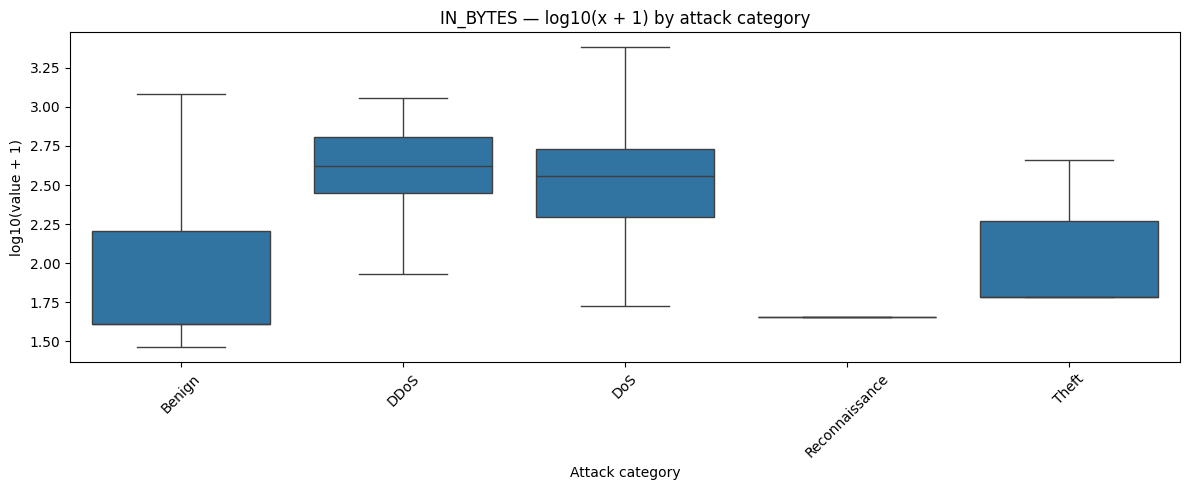

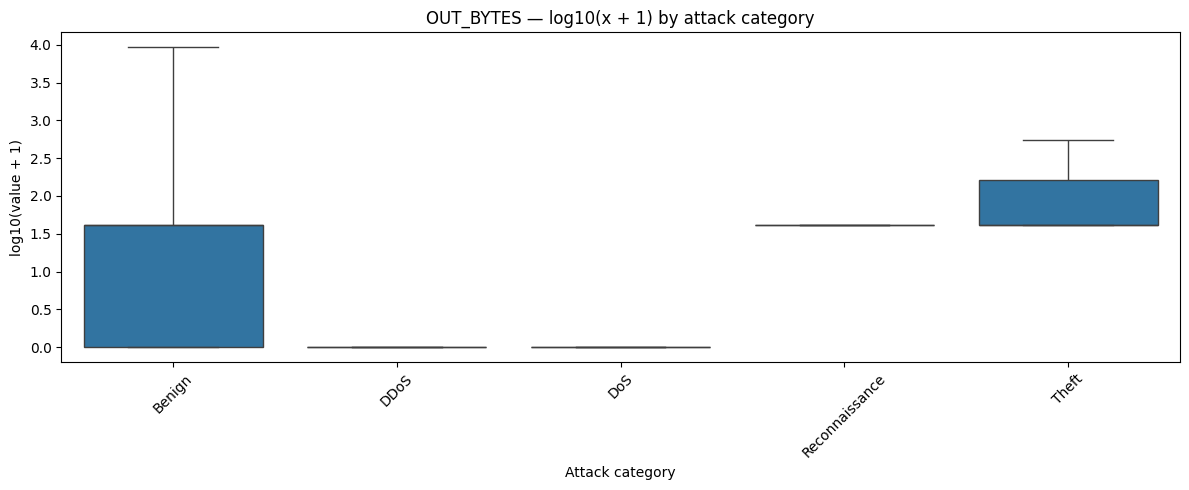

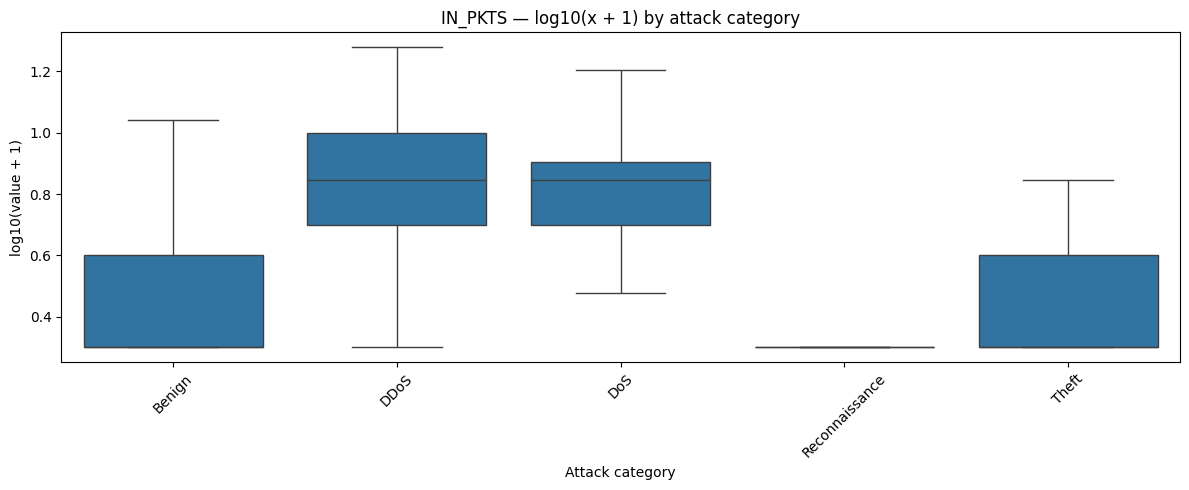

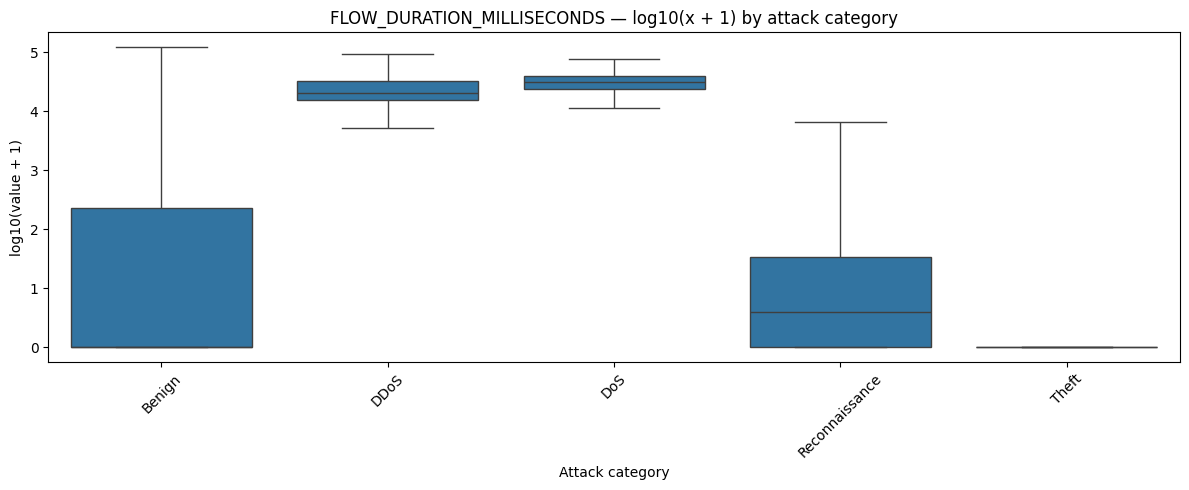

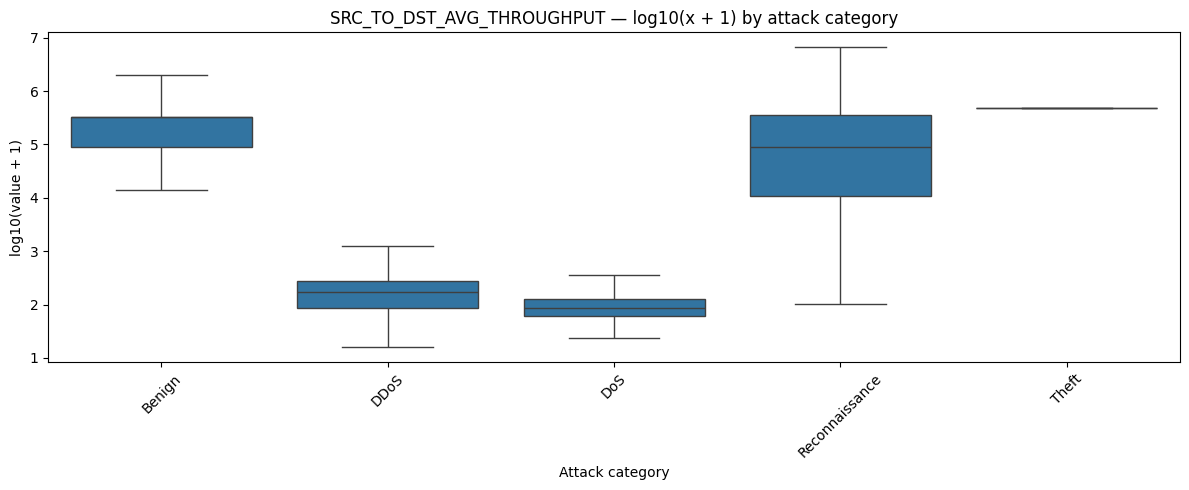

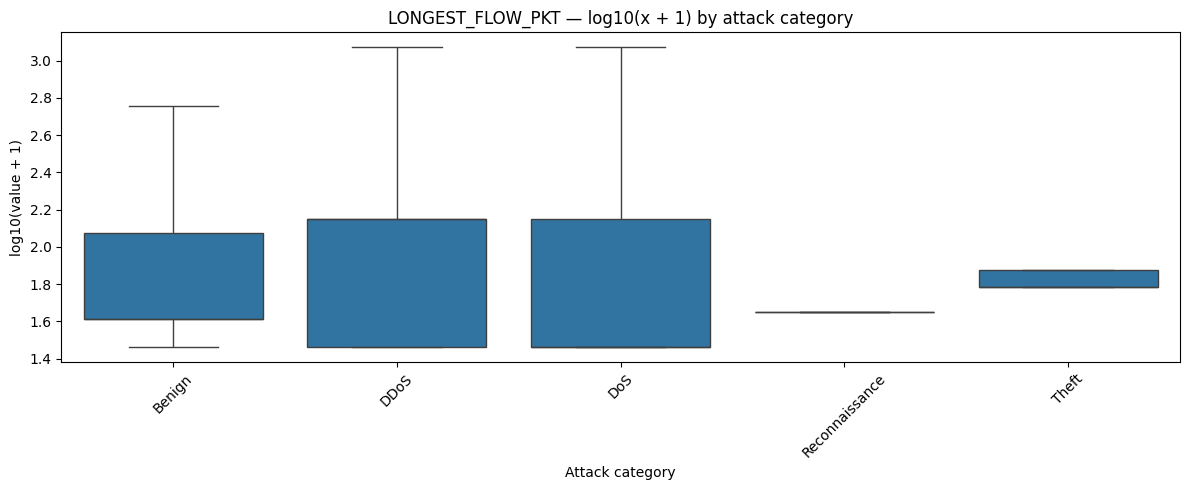


--- Reference cell 115 ---
Longest packet (bytes): 65212
Packets above 1514 bytes: 65
Longest flow (milliseconds): 120998
Flows above 120 seconds: 306
Highest source-to-destination throughput: 7392000
Largest incoming flow (bytes): 9596174
Largest outgoing flow (bytes): 110092961
Highest DNS TTL (seconds): 4294915672

--- Reference cell 116 ---
Top 10 highest skewness values:


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1256: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean


,Skewness
OUT_BYTES,654.563000
RETRANSMITTED_IN_PKTS,219.070449
RETRANSMITTED_IN_BYTES,219.044244
DNS_TTL_ANSWER,188.975432
LONGEST_FLOW_PKT,188.711105
MAX_IP_PKT_LEN,188.711105
NUM_PKTS_UP_TO_128_BYTES,178.508364
OUT_PKTS,163.601274
NUM_PKTS_1024_TO_1514_BYTES,127.473496
NUM_PKTS_256_TO_512_BYTES,121.276974


In [13]:
run_step(6)


### Step 6 — Findings
- With 99.7% attacks, the IQR rule flags **Benign** as the outlier (e.g. 94% of Benign in `SRC_TO_DST_AVG_THROUGHPUT`).
- Limits respected apart from the oversized packets and the invalid DNS TTLs (136 years).

## Step 7 — Feature usefulness and potential bias

Original reference cell IDs: 117, 118, 119, 120, 121, 122. Expand BLOCKS above to inspect executable source.


In [14]:
run_step(7)


Step 7: restored completed checkpoint

--- Reference cell 117 ---
Total rows checked: 16933808
Near-constant columns (>99%): 14


,Column,Most common value,Count,Percentage
12,FTP_COMMAND_RET_CODE,0,16933425,99.9977
11,DNS_TTL_ANSWER,0,16931393,99.9857
10,DNS_QUERY_TYPE,0,16926867,99.9590
9,DNS_QUERY_ID,0,16926867,99.9590
0,RETRANSMITTED_IN_BYTES,0,16924020,99.9422
1,RETRANSMITTED_IN_PKTS,0,16924020,99.9422
3,RETRANSMITTED_OUT_PKTS,0,16923252,99.9377
2,RETRANSMITTED_OUT_BYTES,0,16923252,99.9377
7,ICMP_TYPE,0,16922986,99.9361
8,ICMP_IPV4_TYPE,0,16922988,99.9361



--- Reference cell 118 ---
Total unique source IPs: 20
Only Benign: 12
Only Attack: 0
Both Benign and Attack: 8

--- Reference cell 119 ---
Hours containing traffic: 14
Hours containing attacks: 14
Hours with >90% attacks: 10

Hourly summary:

Date × Attack crosstab:


,Total flows,Attack flows,Attack %
0,289059,284320,98.36
1,48893,44262,90.53
2,49845,43316,86.90
3,4001460,3993648,99.80
4,4233276,4229309,99.91
5,633143,629187,99.38
6,14710,14396,97.87
7,4015325,4012753,99.94
8,3141524,3138321,99.90
9,208721,205344,98.38


Attack,Benign,DDoS,DoS,Reconnaissance,Theft
FLOW_START_MILLISECONDS,,,,,
2018-05-15,13566.0,0.0,0.0,124302.0,0.0
2018-05-21,20451.0,0.0,0.0,781721.0,0.0
2018-05-22,14425.0,0.0,0.0,789109.0,0.0
2018-06-04,3146.0,7150882.0,8034190.0,0.0,0.0
2018-06-18,148.0,0.0,0.0,0.0,140.0
2018-06-19,253.0,0.0,0.0,0.0,1475.0


...

,Feature 1,Feature 2,Absolute correlation
290,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000000
231,MIN_TTL,MAX_TTL,0.999991
435,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,0.999985
138,FLOW_DURATION_MILLISECONDS,DURATION_IN,0.999017
661,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_AVG,0.998539
663,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,0.997746
660,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,0.994427
417,DST_TO_SRC_SECOND_BYTES,SRC_TO_DST_AVG_THROUGHPUT,0.991900
588,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,0.989532
396,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_AVG_THROUGHPUT,0.983496



--- Reference cell 121 ---
Total rows checked: 16933808
ICMP relationship mismatches: 0
Example mismatches: []

--- Reference cell 122 ---
TTL values only in Benign: [1, 127, 229, 238, 241]
TTL values only in attacks: [37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]
TTL values in both: 4

Top 10 TTL values in Benign:

Top 10 TTL values in attacks:

MAX_TTL × Attack crosstab:


,Benign flows
MAX_TTL,
0,35595
64,9492
127,6776
128,73
1,36
238,9
241,5
229,2
48,1


,Attack flows
MAX_TTL,
64,14950856
0,1929787
128,419
59,58
57,54
58,49
56,46
54,43
53,40


Attack,Benign,DDoS,DoS,Reconnaissance,Theft
MAX_TTL,,,,,
0,35595,114992,248012,1565689,1094
1,36,0,0,0,0
37,0,0,0,22,0
38,0,0,0,14,0
39,0,0,0,21,0
40,0,0,0,19,0
41,0,0,0,21,0
42,0,0,0,19,0
43,0,0,0,21,0


### Step 7 — Findings
- Many near-constant columns: retransmissions 99.94%, DNS 99.96%, FTP code 100% zero. `SRC_TO_DST_IAT_MIN` is informative (median 3,115 ms).
- **IPs:** 4 machines send 99.9% of the attacks but also normal traffic.
- **Time:** 18 of 31 hours are > 90% attacks.
- **TTL:** attacks almost all 64; Benign 0 / 64 / 127.
- Exact copies `TCP_FLAGS`, `ICMP_IPV4_TYPE`; perfect correlations `MIN_TTL`/`MAX_TTL`, retransmitted bytes/packets.

## Additional checks *(added from Ahmed Hamouda's analysis)*

These sections close the checklist gaps of this notebook so that it covers every check of the shared Steps 0–8. They keep the section numbers used in `report/data_problems/phase2_data_problems.pdf`. They run **locally from the repository** (`notebooks/`, data in `data/raw/`, shared functions from `src/config.py`), not in Colab; the outputs shown were computed on the full dataset.

### 0.1 Load the data *(added from Ahmed Hamouda's analysis)*

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *

pd.set_option("display.max_columns", 100)

SOURCE = "BoT"
path = RAW_DIR / DATASETS[SOURCE]["file"]

# Large file: integer columns are read as int32 instead of int64, which halves the memory.
# Every value fits (pyarrow stops with an error if one does not); only the timestamps need int64.
header = pd.read_csv(path, nrows=0).columns
types = {c: pa.int32() for c in header if c not in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]}
types["FLOW_START_MILLISECONDS"] = types["FLOW_END_MILLISECONDS"] = pa.int64()
# These three columns hold decimals in some NetFlow files (UNSW, BoT-IoT): read them as float64 (see 0.4)
for c in ["L7_PROTO", "SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]:
    types[c] = pa.float64()
# DNS TTLs can exceed the int32 range (invalid values up to 2^32-1, see 4.2)
types["DNS_TTL_ANSWER"] = pa.int64()
table = pv.read_csv(path, convert_options=pv.ConvertOptions(column_types=types))
df = table.to_pandas(self_destruct=True)
del table

print("rows:", len(df), "(official: 16,933,808)")
print("columns:", df.shape[1])
print(f"memory: {df.memory_usage(deep=True).sum() / 1e9:.1f} GB")

rows: 16933808 (official: 16,933,808)
columns: 55
memory: 4.9 GB


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16933808 entries, 0 to 16933807
Data columns (total 55 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   FLOW_START_MILLISECONDS      int64  
 1   FLOW_END_MILLISECONDS        int64  
 2   IPV4_SRC_ADDR                str    
 3   L4_SRC_PORT                  int32  
 4   IPV4_DST_ADDR                str    
 5   L4_DST_PORT                  int32  
 6   PROTOCOL                     int32  
 7   L7_PROTO                     float64
 8   IN_BYTES                     int32  
 9   IN_PKTS                      int32  
 10  OUT_BYTES                    int32  
 11  OUT_PKTS                     int32  
 12  TCP_FLAGS                    int32  
 13  CLIENT_TCP_FLAGS             int32  
 14  SERVER_TCP_FLAGS             int32  
 15  FLOW_DURATION_MILLISECONDS   int32  
 16  DURATION_IN                  int32  
 17  DURATION_OUT                 int32  
 18  MIN_TTL                      int32  
 19  MAX_TTL  

### 0.4 Same columns as the other NetFlow datasets? *(added from Ahmed Hamouda's analysis)*
The four NetFlow datasets are merged later, so they must have the same columns, in the same order and with
compatible types. Types are inferred by pyarrow from the raw CSV text (first 64 MB of each file).

In [6]:
def raw_types(file):
    with pv.open_csv(RAW_DIR / file, read_options=pv.ReadOptions(block_size=64 << 20)) as reader:
        return pd.Series({field.name: str(field.type) for field in reader.schema})

netflow = ["UNSW", "CIC18", "ToN", "BoT"]
types_all = pd.DataFrame({s: raw_types(DATASETS[s]["file"]) for s in netflow})
orders = {s: list(raw_types(DATASETS[s]["file"]).index) for s in netflow}

print("same column names in all 4:", all(set(orders[s]) == set(orders["UNSW"]) for s in netflow))
print("same order in all 4:       ", all(orders[s] == orders["UNSW"] for s in netflow))
types_all[types_all.nunique(axis=1) > 1]

same column names in all 4: True
same order in all 4:        True


,UNSW,CIC18,ToN,BoT
L7_PROTO,double,int64,int64,double
SRC_TO_DST_SECOND_BYTES,double,int64,int64,double
DST_TO_SRC_SECOND_BYTES,double,int64,int64,double


### 1.3 Are all labels in the team taxonomy? *(added from Ahmed Hamouda's analysis)*
`map_labels` (from `src/config.py`) stops with an error if a label is missing from the shared taxonomy.

In [10]:
try:
    map_labels(df[["Attack"]].drop_duplicates(), "Attack", SOURCE)
    print("all labels are in the taxonomy")
except ValueError as error:
    print(error)

all labels are in the taxonomy


**Mapping of every label** to the shared taxonomy, with the number of flows per label and per family.

In [11]:
try:
    mapped = map_labels(df[["Attack"]].drop_duplicates(), "Attack", SOURCE).set_index("Attack")[["attack_label", "attack_family"]]
    mapping = mapped.join(df["Attack"].value_counts().rename("flows")).sort_values(["attack_family", "flows"], ascending=[True, False])
    display(mapping)
    display(mapping.groupby("attack_family")["flows"].sum().sort_values(ascending=False))
except ValueError as error:
    print(error)

,attack_label,attack_family,flows
Attack,,,
Benign,Benign,Benign,51989
Theft,Theft,Data theft,1615
DoS,DoS,Denial of service,8034190
DDoS,DDoS,Denial of service,7150882
Reconnaissance,Reconnaissance,Reconnaissance,1695132


attack_family
Denial of service    15185072
Reconnaissance        1695132
Benign                  51989
Data theft               1615
Name: flows, dtype: int64

### 1.4 Class distribution *(added from Ahmed Hamouda's analysis)*

In [12]:
distribution = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "percent": (100 * df["Attack"].value_counts(normalize=True)).round(3),
})
distribution

,flows,percent
Attack,,
DoS,8034190,47.445
DDoS,7150882,42.228
Reconnaissance,1695132,10.010
Benign,51989,0.307
Theft,1615,0.010


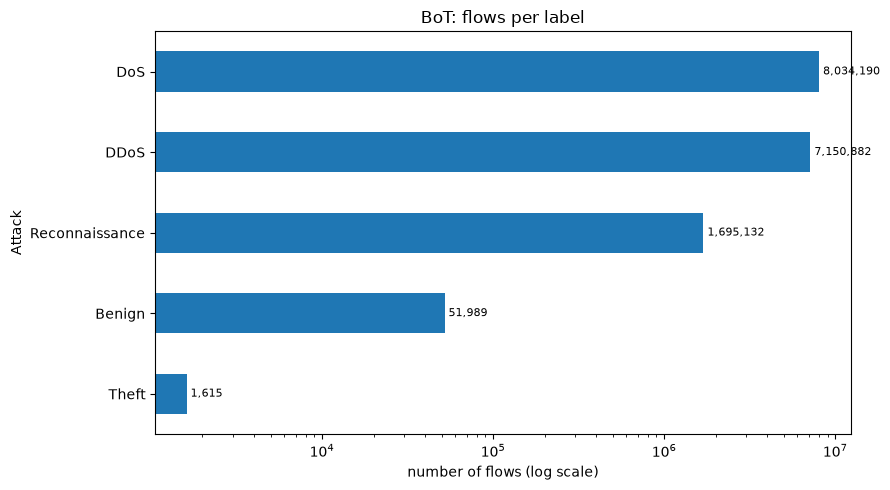

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
distribution["flows"].sort_values().plot.barh(ax=ax)
ax.set_xscale("log")
ax.set_xlabel("number of flows (log scale)")
ax.set_title(f"{SOURCE}: flows per label")
for i, v in enumerate(distribution["flows"].sort_values()):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### 2.1 Columns stored as text *(added from Ahmed Hamouda's analysis)*
Are there text columns that actually contain numbers?

In [14]:
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    as_number = pd.to_numeric(df[col], errors="coerce")
    print(f"{col:15s} distinct: {df[col].nunique():>9,}   values that are numbers: {as_number.notna().sum():,}")

IPV4_SRC_ADDR   distinct:        20   values that are numbers: 0


IPV4_DST_ADDR   distinct:       291   values that are numbers: 0


Attack          distinct:         5   values that are numbers: 0


### 2.2 Timestamps stored as integers *(added from Ahmed Hamouda's analysis)*
`FLOW_START_MILLISECONDS` and `FLOW_END_MILLISECONDS` are milliseconds since 1 January 1970. Converted here only to check that the dates are plausible.

In [15]:
start = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")
end = pd.to_datetime(df["FLOW_END_MILLISECONDS"], unit="ms")
print("first flow starts:", start.min())
print("last flow ends:   ", end.max())

first flow starts: 2018-05-15 00:27:11.665000
last flow ends:    2018-06-19 04:17:14.508000


In [16]:
# Flows per capture day
start.dt.date.value_counts().sort_index()

FLOW_START_MILLISECONDS
2018-05-15      137868
2018-05-21      802172
2018-05-22      803534
2018-06-04    15188218
2018-06-18         288
2018-06-19        1728
Name: count, dtype: int64

### 2.3 Codes stored as numbers *(added from Ahmed Hamouda's analysis)*
These columns hold identifiers of a protocol, port, flag or message type. Their numbers have no order or size: an average port or protocol has no meaning.

In [17]:
code_cols = ["L4_SRC_PORT", "L4_DST_PORT", "PROTOCOL", "L7_PROTO",
             "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
             "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"]

pd.DataFrame({
    "dtype": df[code_cols].dtypes.astype(str),
    "distinct values": df[code_cols].nunique(),
    "most common": [df[c].mode()[0] for c in code_cols],
})

,dtype,distinct values,most common
L4_SRC_PORT,int32,65536,41607.0
L4_DST_PORT,int32,65536,80.0
PROTOCOL,int32,5,6.0
L7_PROTO,float64,164,0.0
TCP_FLAGS,int32,24,0.0
CLIENT_TCP_FLAGS,int32,25,2.0
SERVER_TCP_FLAGS,int32,21,0.0
ICMP_TYPE,int32,544,0.0
ICMP_IPV4_TYPE,int32,254,0.0
DNS_QUERY_TYPE,int32,9,0.0


**TCP flag values above 31.** Besides FIN, SYN, RST, PSH and ACK (1–31), TCP has two congestion flags: ECE = 64 and CWR = 128.

In [18]:
high_flags = df["TCP_FLAGS"] > 31
print(f"flows with ECE/CWR flags: {high_flags.sum():,} ({100 * high_flags.mean():.1f} %)")
(100 * high_flags.groupby(df["Attack"]).mean()).round(1).sort_values(ascending=False).rename("% of class")

flows with ECE/CWR flags: 836 (0.0 %)


Attack
Benign            0.0
DDoS              0.0
DoS               0.0
Reconnaissance    0.0
Theft             0.0
Name: % of class, dtype: float64

**Protocol numbers present**

In [19]:
protocols = pd.crosstab(df["PROTOCOL"], df["Label"]).rename(columns={0: "benign", 1: "attack"})
protocols["name"] = protocols.index.map({1: "ICMP", 2: "IGMP", 6: "TCP", 17: "UDP", 47: "GRE", 58: "ICMPv6"})
protocols

Label,benign,attack,name
PROTOCOL,,,
1,9,943,ICMP
2,6,0,IGMP
6,37605,9659534,TCP
17,14275,7221342,UDP
58,94,0,ICMPv6


### 2.4 `L7_PROTO` stored as a float *(added from Ahmed Hamouda's analysis)*
A value like `7.37` is two codes in one: the outer protocol (7 = HTTP) and the application inside it (37 = BitTorrent).

In [20]:
has_decimals = df["L7_PROTO"] % 1 != 0
print(f"flows with a decimal L7_PROTO: {has_decimals.sum():,} ({100 * has_decimals.mean():.2f} %)")
df.loc[has_decimals, "L7_PROTO"].value_counts()

flows with a decimal L7_PROTO: 1,851 (0.01 %)


L7_PROTO
7.500     796
10.160    337
5.239     213
10.410    132
5.265     125
7.376     119
91.239     45
5.212      27
5.283      26
91.283     13
5.169       6
5.220       4
91.265      3
7.212       3
91.169      2
Name: count, dtype: int64

### 2.5 Invalid codes *(added from Ahmed Hamouda's analysis)*
Codes that do not exist in the official lists:
- **Protocol numbers:** IANA has assigned 0–147; 148–252 are unassigned, 253–254 are for experiments and 255 is reserved.
- **Port 0:** reserved and never used by real TCP/UDP traffic. Other protocols have no ports, so 0 is normal there.
- **DNS query types:** only the types assigned by IANA are valid.
- **ICMP types:** only the types assigned by IANA are valid. Checked on ICMP flows only.

In [21]:
unassigned_proto = df["PROTOCOL"] > 147
print(f"flows with an unassigned protocol number: {unassigned_proto.sum():,}")
print(f"distinct unassigned protocol numbers:     {df.loc[unassigned_proto, 'PROTOCOL'].nunique()}")
df.loc[unassigned_proto, "Attack"].value_counts()

flows with an unassigned protocol number: 0
distinct unassigned protocol numbers:     0


Series([], Name: count, dtype: int64)

In [22]:
tcp_udp = df["PROTOCOL"].isin([6, 17])
port0 = tcp_udp & ((df["L4_SRC_PORT"] == 0) | (df["L4_DST_PORT"] == 0))
print(f"TCP/UDP flows using port 0: {port0.sum():,}")
df.loc[port0, "Attack"].value_counts()

TCP/UDP flows using port 0: 1,171


Attack
Benign    968
DoS       106
DDoS       97
Name: count, dtype: int64

In [23]:
# IANA DNS record types: 1-260 are the standard range, 32768-32769 are DNSSEC-related
dns = df["DNS_QUERY_TYPE"]
invalid_dns = (dns != 0) & ~(dns.between(1, 260) | dns.isin([32768, 32769]))
print(f"flows with an invalid DNS query type: {invalid_dns.sum()}")
df.loc[invalid_dns, ["L4_DST_PORT", "DNS_QUERY_TYPE", "Attack"]]

flows with an invalid DNS query type: 0


,L4_DST_PORT,DNS_QUERY_TYPE,Attack


In [24]:
# IANA ICMP types still in use
valid_icmp = [0, 3, 4, 5, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 30, 40, 41, 42, 43]
icmp = df["PROTOCOL"] == 1
invalid_icmp = icmp & ~df["ICMP_IPV4_TYPE"].isin(valid_icmp)
print(f"ICMP flows: {icmp.sum()}, with an invalid ICMP type: {invalid_icmp.sum()}")
df.loc[invalid_icmp, ["ICMP_TYPE", "ICMP_IPV4_TYPE", "Attack"]].value_counts()

ICMP flows: 952, with an invalid ICMP type: 0


Series([], Name: count, dtype: int64)

### 3.2 Infinite values *(added from Ahmed Hamouda's analysis)*

In [26]:
float_cols = df.select_dtypes("float").columns
print("float columns:", list(float_cols) or "none (integer columns cannot hold inf or NaN)")
inf_count = np.isinf(df[float_cols]).sum() if len(float_cols) else pd.Series(dtype=int)
pd.DataFrame({"infinite": inf_count, "percent": (100 * inf_count / len(df)).round(3)})[inf_count > 0]

float columns: ['L7_PROTO', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES']


,infinite,percent
SRC_TO_DST_SECOND_BYTES,664755,3.926
DST_TO_SRC_SECOND_BYTES,1052105,6.213


### 3.3 Where do the NaN and inf come from? *(added from Ahmed Hamouda's analysis)*
The two `..._SECOND_BYTES` columns are a division by the flow duration, so a duration of 0 is the first suspect.
We also check which byte column each one is actually computed from.

In [27]:
zero_duration = df["FLOW_DURATION_MILLISECONDS"] == 0
s2d, d2s = df["SRC_TO_DST_SECOND_BYTES"], df["DST_TO_SRC_SECOND_BYTES"]

print(f"flows with duration 0: {zero_duration.sum():,}")
pd.DataFrame({
    "duration = 0": [s2d[zero_duration].isna().sum(), np.isinf(s2d[zero_duration]).sum(), np.isinf(d2s[zero_duration]).sum()],
    "duration > 0": [s2d[~zero_duration].isna().sum(), np.isinf(s2d[~zero_duration]).sum(), np.isinf(d2s[~zero_duration]).sum()],
}, index=["SRC_TO_DST_SECOND_BYTES NaN", "SRC_TO_DST_SECOND_BYTES inf", "DST_TO_SRC_SECOND_BYTES inf"])

flows with duration 0: 1,052,105


,duration = 0,duration > 0
SRC_TO_DST_SECOND_BYTES NaN,387350,0
SRC_TO_DST_SECOND_BYTES inf,664755,0
DST_TO_SRC_SECOND_BYTES inf,1052105,0


In [28]:
# Which formula reproduces each column? (share of flows with duration > 0 that match)
ok = ~zero_duration
duration_ms = df.loc[ok, "FLOW_DURATION_MILLISECONDS"]
formulas = pd.DataFrame({
    col: {
        "IN_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "OUT_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "OUT_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "IN_BYTES / duration (s)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / (duration_ms / 1000), rtol=1e-3).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
})
(100 * formulas).round(2)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
IN_BYTES / duration (ms),0.04,100.00
OUT_BYTES / duration (ms),100.00,0.04
IN_BYTES / duration (s),0.00,0.00


In [29]:
# The values are integers here: test the formulas with the decimals cut off (floor)
pd.DataFrame({
    col: {
        "floor(IN_BYTES / duration ms)": (np.floor(df["IN_BYTES"] / df["FLOW_DURATION_MILLISECONDS"]) == df[col]).mean(),
        "floor(OUT_BYTES / duration ms)": (np.floor(df["OUT_BYTES"] / df["FLOW_DURATION_MILLISECONDS"]) == df[col]).mean(),
        "share of zeros": (df[col] == 0).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
}).mul(100).round(1)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
floor(IN_BYTES / duration ms),73.5,7.3
floor(OUT_BYTES / duration ms),74.3,3.9
share of zeros,69.2,0.0


In [30]:
# NaN rows: what do they have in common?
if s2d.isna().any():
    display(df.loc[s2d.isna(), ["IN_PKTS", "OUT_PKTS", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS"]].describe().loc[["min", "max"]])
else:
    print("no NaN to describe")

,IN_PKTS,OUT_PKTS,OUT_BYTES,FLOW_DURATION_MILLISECONDS
min,1.0,0.0,0.0,0.0
max,3.0,0.0,0.0,0.0


### 3.4 Is the missingness linked to the attack class? *(added from Ahmed Hamouda's analysis)*

In [31]:
missing_by_class = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "NaN or inf (%)": (100 * (s2d.isna() | np.isinf(s2d) | np.isinf(d2s)).groupby(df["Attack"]).mean()).round(2),
}).sort_values("NaN or inf (%)", ascending=False)
missing_by_class

,flows,NaN or inf (%)
Attack,,
Theft,1615,70.34
Benign,51989,64.94
Reconnaissance,1695132,41.19
DoS,8034190,2.83
DDoS,7150882,1.28


### 3.5 Visualisation *(added from Ahmed Hamouda's analysis)*

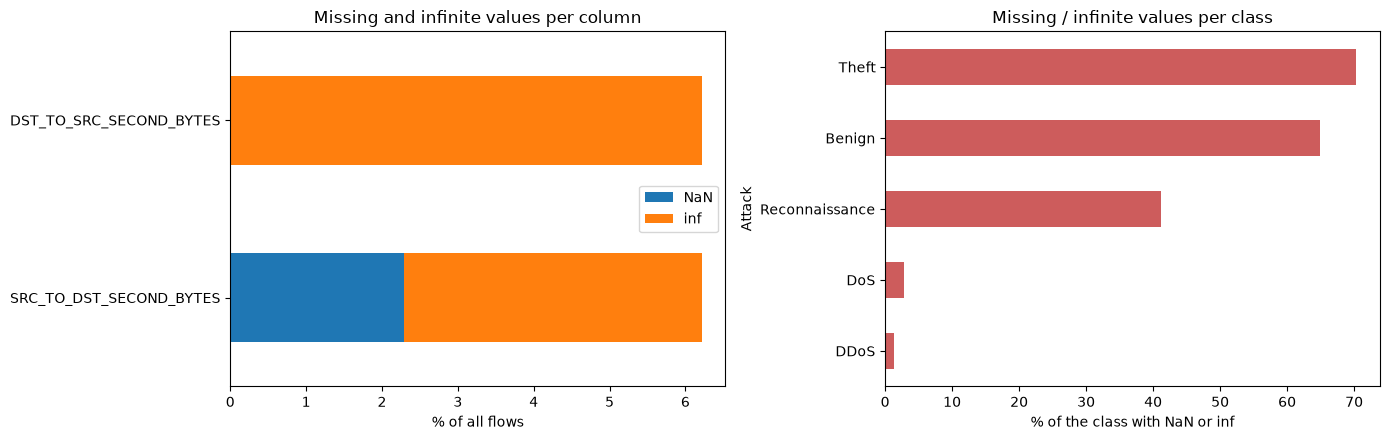

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pd.DataFrame({
    "NaN": 100 * df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]].isna().mean(),
    "inf": 100 * np.isinf(df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]]).mean(),
}).plot.barh(stacked=True, ax=axes[0])
axes[0].set_xlabel("% of all flows")
axes[0].set_title("Missing and infinite values per column")

missing_by_class["NaN or inf (%)"].sort_values().plot.barh(ax=axes[1], color="indianred")
axes[1].set_xlabel("% of the class with NaN or inf")
axes[1].set_title("Missing / infinite values per class")
plt.tight_layout()
plt.show()

### 3.6 Disguised missing values *(added from Ahmed Hamouda's analysis)*
A value of 0 can mean "does not apply" (no DNS query in a web flow) or "not recorded". Each protocol-specific
field should only be filled for its own protocol.

In [33]:
is_dns = (df["L4_DST_PORT"] == 53) | (df["L4_SRC_PORT"] == 53) | (df["L7_PROTO"].astype(int) == 5)
is_ftp = (df["L4_DST_PORT"] == 21) | (df["L4_SRC_PORT"] == 21) | (df["L7_PROTO"].astype(int) == 1)
is_icmp = df["PROTOCOL"] == 1
is_tcp = df["PROTOCOL"] == 6

pd.DataFrame([
    ["DNS_QUERY_TYPE", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_QUERY_TYPE"] == 0)).sum(), (~is_dns & (df["DNS_QUERY_TYPE"] != 0)).sum()],
    ["DNS_TTL_ANSWER", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_TTL_ANSWER"] == 0)).sum(), (~is_dns & (df["DNS_TTL_ANSWER"] != 0)).sum()],
    ["FTP_COMMAND_RET_CODE", "FTP flows", is_ftp.sum(), (is_ftp & (df["FTP_COMMAND_RET_CODE"] == 0)).sum(), (~is_ftp & (df["FTP_COMMAND_RET_CODE"] != 0)).sum()],
    ["ICMP_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_TYPE"] != 0)).sum()],
    ["ICMP_IPV4_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_IPV4_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_IPV4_TYPE"] != 0)).sum()],
    ["TCP_FLAGS", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_FLAGS"] == 0)).sum(), (~is_tcp & (df["TCP_FLAGS"] != 0)).sum()],
    ["TCP_WIN_MAX_IN", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_WIN_MAX_IN"] == 0)).sum(), (~is_tcp & (df["TCP_WIN_MAX_IN"] != 0)).sum()],
], columns=["column", "applies to", "flows it applies to", "0 where it applies", "filled where it does NOT apply"])

,column,applies to,flows it applies to,0 where it applies,filled where it does NOT apply
0,DNS_QUERY_TYPE,DNS flows,7889,974,26
1,DNS_TTL_ANSWER,DNS flows,7889,5474,0
2,FTP_COMMAND_RET_CODE,FTP flows,4386,4003,0
3,ICMP_TYPE,ICMP flows,952,0,9870
4,ICMP_IPV4_TYPE,ICMP flows,952,0,9868
5,TCP_FLAGS,TCP flows,9697139,5061,0
6,TCP_WIN_MAX_IN,TCP flows,9697139,6042,0


In [34]:
# Which protocol carries the ICMP values that should not be there?
df.loc[~is_icmp & (df["ICMP_TYPE"] != 0), "PROTOCOL"].value_counts()

PROTOCOL
6     9776
58      94
Name: count, dtype: int64

**DNS fields outside DNS.** Which ports and application protocols carry them?

In [35]:
outside_dns = ~is_dns & (df["DNS_QUERY_TYPE"] != 0)
print(f"flows with a DNS query type outside DNS: {outside_dns.sum():,}")
print("destination ports:", dict(df.loc[outside_dns, "L4_DST_PORT"].value_counts().head(3)))
print("L7_PROTO:         ", dict(df.loc[outside_dns, "L7_PROTO"].value_counts().head(3)))

flows with a DNS query type outside DNS: 26
destination ports: {5355: np.int64(26)}
L7_PROTO:          {154.0: np.int64(26)}


**ICMP fields on protocol 58.** Protocol 58 is ICMPv6, so ICMP types are legitimate there.

In [36]:
df.loc[df["PROTOCOL"] == 58, "ICMP_IPV4_TYPE"].value_counts().rename("ICMPv6 type (143 = MLDv2 report, 135 = neighbour solicitation)")

ICMP_IPV4_TYPE
133    94
Name: ICMPv6 type (143 = MLDv2 report, 135 = neighbour solicitation), dtype: int64

In [37]:
# TTL = 0: a packet with TTL 0 is discarded by the network, so 0 means "not recorded"
ttl0 = df["MIN_TTL"] == 0
print(f"flows with MIN_TTL = 0: {ttl0.sum():,}   with MAX_TTL = 0: {(df['MAX_TTL'] == 0).sum():,}")
print("by protocol:", dict(df.loc[ttl0, "PROTOCOL"].value_counts().head(3)))
print("by class:   ", dict(df.loc[ttl0, "Attack"].value_counts()))

flows with MIN_TTL = 0: 1,965,382   with MAX_TTL = 0: 1,965,382
by protocol: {6: np.int64(1811685), 17: np.int64(153593), 58: np.int64(94)}
by class:    {'Reconnaissance': np.int64(1565689), 'DoS': np.int64(248012), 'DDoS': np.int64(114992), 'Benign': np.int64(35595), 'Theft': np.int64(1094)}


In [38]:
# Share of each class with TTL = 0
(100 * ttl0.groupby(df["Attack"]).mean()).round(1).sort_values(ascending=False).rename("% with TTL = 0")

Attack
Reconnaissance    92.4
Benign            68.5
Theft             67.7
DoS                3.1
DDoS               1.6
Name: % with TTL = 0, dtype: float64

### 5.4 Same behaviour, different label *(added from Ahmed Hamouda's analysis)*
Identifiers that do not describe behaviour (IP addresses, source port, timestamps, DNS query ID) are left out.
If the remaining behaviour is identical but the labels differ, no model can tell these flows apart.

In [50]:
behaviour_cols = [c for c in df.columns if c not in
                  ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "FLOW_START_MILLISECONDS",
                   "FLOW_END_MILLISECONDS", "DNS_QUERY_ID", "Label", "Attack"]]
behaviour = pd.util.hash_pandas_object(df[behaviour_cols], index=False)
labels_per_behaviour = df.groupby(behaviour)["Attack"].nunique()
conflict = behaviour.isin(labels_per_behaviour.index[labels_per_behaviour > 1])
binary_conflict = df[conflict].groupby(behaviour[conflict])["Label"].nunique().gt(1).sum()

print(f"rows with conflicting labels: {conflict.sum():,} in {behaviour[conflict].nunique():,} behaviour groups")
print(f"groups mixing Benign and attack: {binary_conflict}")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "conflicting": df.loc[conflict, "Attack"].value_counts(),
}).fillna(0).astype(int).assign(percent=lambda t: (100 * t["conflicting"] / t["flows"]).round(2)).sort_values("percent", ascending=False)

rows with conflicting labels: 681,097 in 7,009 behaviour groups
groups mixing Benign and attack: 6757


,flows,conflicting,percent
Attack,,,
Benign,51989,29928,57.57
Reconnaissance,1695132,378192,22.31
DoS,8034190,158927,1.98
DDoS,7150882,114050,1.59
Theft,1615,0,0.00


In [51]:
# The three largest groups of identical behaviour with different labels
for group in behaviour[conflict].value_counts().index[:3]:
    rows = df[behaviour == group]
    first = rows.iloc[0]
    print(f"protocol {first['PROTOCOL']}, dst port {first['L4_DST_PORT']}, {first['IN_PKTS']} packets / {first['IN_BYTES']} bytes, "
          f"reply packets {first['OUT_PKTS']} ->", dict(rows["Attack"].value_counts()))

protocol 6, dst port 80, 1 packets / 140 bytes, reply packets 0 -> {'DoS': np.int64(122631), 'DDoS': np.int64(86005)}


protocol 6, dst port 1, 1 packets / 40 bytes, reply packets 1 -> {'Reconnaissance': np.int64(8716), 'Benign': np.int64(1536)}


protocol 6, dst port 80, 1 packets / 52 bytes, reply packets 0 -> {'DoS': np.int64(3605), 'DDoS': np.int64(3419)}


**Which labels are mixed together?**

In [52]:
conflict_labels = (df.loc[conflict].groupby(behaviour[conflict])["Attack"]
                   .agg(lambda s: " + ".join(sorted(s.unique()))))
group_size = behaviour[conflict].value_counts()
pd.DataFrame({"labels": conflict_labels, "rows": group_size.reindex(conflict_labels.index)}) \
  .groupby("labels")["rows"].agg(groups="count", rows="sum").sort_values("rows", ascending=False).head(12)

,groups,rows
labels,,
Benign + Reconnaissance,6757,408113
DDoS + DoS,251,272961
DDoS + DoS + Reconnaissance,1,23


**Attack flows whose behaviour also appears as Benign**

In [53]:
benign_behaviour = set(behaviour[df["Attack"] == "Benign"])
same_as_benign = behaviour.isin(benign_behaviour) & (df["Attack"] != "Benign")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "identical to a Benign flow": df.loc[same_as_benign, "Attack"].value_counts(),
}).fillna(0).astype(int).query("`identical to a Benign flow` > 0") \
  .assign(percent=lambda t: (100 * t["identical to a Benign flow"] / t["flows"]).round(1),
          left_if_removed=lambda t: t["flows"] - t["identical to a Benign flow"])

,flows,identical to a Benign flow,percent,left_if_removed
Attack,,,,
Reconnaissance,1695132,378185,22.3,1316947


**What do the flows of each attack label look like?** A label with only one or two distinct behaviours, or
whose most common behaviour is a refused or empty connection, may be mislabelled (as SlowHTTPTest in CIC-2018).

In [54]:
profile = []
for label in df.loc[df["Label"] == 1, "Attack"].unique():
    in_label = df["Attack"] == label
    top = behaviour[in_label].value_counts()
    first = df.loc[in_label & (behaviour == top.index[0])].iloc[0]
    profile.append({
        "label": label,
        "flows": int(in_label.sum()),
        "distinct behaviours": len(top),
        "top behaviour %": round(100 * top.iloc[0] / in_label.sum(), 1),
        "top: protocol / dst port": f"{first['PROTOCOL']} / {first['L4_DST_PORT']}",
        "top: packets in / out": f"{first['IN_PKTS']} / {first['OUT_PKTS']}",
        "top: bytes in / out": f"{first['IN_BYTES']} / {first['OUT_BYTES']}",
        "top: client / server flags": f"{first['CLIENT_TCP_FLAGS']} / {first['SERVER_TCP_FLAGS']}",
        "main destination ports": dict(df.loc[in_label, "L4_DST_PORT"].value_counts().head(3)),
    })
pd.DataFrame(profile).set_index("label").sort_values("top behaviour %", ascending=False)

,flows,distinct behaviours,top behaviour %,top: protocol / dst port,top: packets in / out,top: bytes in / out,top: client / server flags,main destination ports
label,,,,,,,,
Theft,1615,448,67.5,6 / 4433,1 / 1,60 / 40,2 / 20,"{4433: 1100, 22: 321, 445: 148}"
DoS,8034190,354734,1.5,6 / 80,1 / 0,140 / 0,2 / 0,"{80: 8030452, 0: 65, 54986: 2}"
Reconnaissance,1695132,898729,1.3,6 / 1883,3 / 3,414 / 164,26 / 22,"{80: 44251, 1883: 24299, 1: 13567}"
DDoS,7150882,287453,1.2,6 / 80,1 / 0,140 / 0,2 / 0,"{80: 7139045, 0: 46, 16918: 3}"


## Step 8 — Decisions

Decisions only: **nothing is changed in the data in this notebook.** "When" says whether the decision is applied to this
dataset **before** the merge (rows, labels, types) or once on the merged table **after** it (shared column rules); see
`report/data_problems/phase2_data_problems.pdf`. The last two columns give the matching decision in `01_unsw` and `02_cic18`.

| # | Check | Problem | Size | Decision | When | Also in UNSW? | Also in CIC-2018? |
|---|---|---|---|---|---|---|---|
| 1 | 1.4 | Inverted imbalance, Benign 0.3% | 51,989 Benign | 200k cap inside BoT-IoT; use as attack data, not to describe normal traffic | before | **Partly** (#1, opposite) | **Partly** (#3, opposite) |
| 2 | 0.1 + 1.4 | Theft rare; official counts wrong | 1,615 | Keep all; report the typo | before | **Yes** (#2) | **Yes** (#4) |
| 3 | 1.3 | 3 of 9 families | DoS, Recon, Data theft | Document | before | **Yes** (#3) | **Yes** (#5) |
| 4 | 3.1–3.4 | NaN / inf in `SECOND_BYTES`, 65% of Benign | 387,350 + 1,716,860 | **Drop both columns before `clean()`** | before | **Yes** (#9–11) | **Partly** (#10) |
| 5 | 2.4 | `L7_PROTO` decimal sub-codes | 1,851 (796 ambiguous) | Split `L7_MAIN` + `L7_SUB` | before | **Yes** (#7) | **Partly** (#9) |
| 6 | 5.4 | DoS and DDoS identical | 272,961 rows | Keep; same family | before | **Yes** (#24) | No |
| 7 | 5.4 | Reconnaissance identical to Benign | 378,185 (22.3%) | **Keep** (as ToN-IoT); do not apply the CIC-2018 rule | before | No | **Partly** (#30: removed there) |
| 8 | 2.3 | Codes stored as numbers | 11 columns | Categorical | after | **Yes** (#6) | **Yes** (#8) |
| 9 | 2.2 + 7.3 | Timestamps; time reveals attacks | 2 columns | Datetime for analysis; not features | after | **Yes** (#5, #26) | **Yes** (#7, #35) |
| 10 | 7.2 | IP addresses | 2 columns | Dropped by `clean()` | after | **Yes** (#26) | **Yes** (#34) |
| 11 | 7.5 + 3.6 | TTL fingerprint; TTL = 0 11.6% | 2 columns | Keep 0 as unknown; not features | after | **Yes** (#13, #27) | **Yes** (#18, #36) |
| 12 | 7.1 | Random identifiers | 2 columns | Not features | after | **Yes** (#28) | **Yes** (#37) |
| 13 | 3.6 | ICMP fields on TCP flows | 9,776 | Set to 0 unless protocol 1 / 58 | after | **Yes** (#12) | **Yes** (#15) |
| 14 | 4.2 | `MIN_IP_PKT_LEN` = 0; copies | 12,102,947 | Drop both `IP_PKT_LEN` columns | after | **Yes** (#15) | **Yes** (#19) |
| 15 | 7.4 | Exact copies | 2 columns | Drop | after | **Yes** (#30) | **Yes** (#39) |
| 16 | 4.2 + 6.3 | DNS TTL above 2^31−1 | 320 | Set to 0 (RFC 2181) | after | **Yes** (#19) | **Partly** (#25) |
| 17 | 4.2 | TCP without flags (7.4% of Benign), port 0, 1-ms rounding | 5,061; 1,171; 7,154 | Keep; re-check Benign in EDA | after | **Yes** (#21) | **Yes** (#23–24) |
| 18 | 4.2 | Oversized packets, size bins, small byte counts, gap > flow | 1,075; 1,356; 80; 111 | Keep; document | after | **Yes** (#16–18) | **Yes** (#20–22) |
| 19 | 3.6 | 0 = not applicable; LLMNR; ICMPv6 | 26; 94 | Keep | after | **Partly** (#14) | **Yes** (#13, #16) |
| 20 | 5.3 | No unique flow key | 612 rows | No action | after | **Yes** (#23) | **Yes** (#31) |
| 21 | 6.1 | Outliers (Benign is the outlier here) | up to 18% | Keep; log transform | after | **Yes** (#25) | **Yes** (#32) |
| 22 | 7.1 | Near-constant columns; IAT_MIN informative | many | Feature selection on merged data | after | **Partly** (#29) | **Yes** (#17, #38) |
| 23 | 7.4 | High correlations | several | Feature selection rule | after | **Yes** (#31) | **Yes** (#40) |
| 24 | 0.3 | Documentation errors | same document + page typo | Report | after | **Yes** (#32) | **Yes** (#41) |
| 25 | 4.4 *new* | IAT average below IAT minimum (minimum skips 0-ms gaps; average correct) | 43,806 flows | Keep; read `IAT_MIN` as smallest non-zero gap | after | **Yes**: 316 | **Yes**: 862,525 |
| 26 | 4.4 *new* | TCP window 0 although packets were sent (almost all on the server side, 100% resets) | 2,936,334 flows | Keep; a reset carries window 0 by design | after | **Yes**: 45,884 (no resets, unexplained) | **Yes**: 1,371,482 |
| 27 | 4.4 *new* | `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0; 1-packet flow longer than `IN_BYTES` | 0 / 0 flows | Keep; the `IP_PKT_LEN` columns are dropped anyway | after | **No**: 0 / 0 | **Yes**: 12 / 11 |


**Update after the ToN-IoT / BoT-IoT cross-check (Cyrine Chabbar).** Rows marked *new* come from section 4.4. The "200k per label" sampling mentioned in older rows is replaced by the plan in section 6 of `report/data_problems/phase2_data_problems.pdf`: one row per different behaviour (with a `count` column), class and network weights, a grouped 80/20 split and realistic 95/5 test sets. Pending team agreement.

### Shared proposals: does the BoT-IoT data agree?
| # | Shared proposal | BoT-IoT | Evidence |
|---|---|---|---|
| 1 | Drop `SECOND_BYTES` before `clean()` | **Agree (essential)** | 387,350 NaN + 1,716,860 inf; `clean()` would delete 64.9% of Benign and 70.3% of Theft |
| 2 | Drop `MIN/MAX_IP_PKT_LEN` | Agree | `MIN_IP_PKT_LEN` = 0 on 12,102,947 one-way flows; `MAX_IP_PKT_LEN` = `LONGEST_FLOW_PKT` everywhere |
| 3 | ICMP fields to 0 outside protocols 1 / 58 | Agree | 9,776 TCP flows carry ICMP values |
| 4 | Drop `TCP_FLAGS`, `ICMP_IPV4_TYPE` | Agree | Both relationships hold on 100% of the flows |
| 5 | Split `L7_PROTO` into main / sub-protocol | **Agree (needed)** | 1,851 decimal values, 796 ambiguous `7.5` |
| 6 | DNS TTL above 2^31−1 → 0 | **Agree (applies)** | 320 Reconnaissance flows, up to 4,294,915,672 s |
| 7 | TTL = 0 unknown; TTL not a feature | Agree | 1,965,382 flows with TTL 0; attacks almost all 64 |
| 8 | IPs dropped; time analysis-only | Agree | 4 machines send 99.9% of the attacks; 18 of 31 hours > 90% attacks |
| 9 | Source port, DNS query ID not features | Agree | random identifiers |
| 10 | IAT_MIN decided in feature selection | Agree | `SRC_TO_DST_IAT_MIN` is informative here (median 3,115 ms) |
| 11 | FTP code decided in feature selection | Agree | 100% zero in BoT-IoT |
| 12 | Remove exact duplicates | Not applicable | 0 exact duplicates |
| 13 | Remove identical rows with two labels | Not applicable | 0 |
| 14 | Remove attack flows identical to Benign | **Disagree** (as ToN-IoT) | would remove 22.3% of Reconnaissance; the flows are too short, the labels are not wrong |
| 15 | Keep attack-vs-attack conflicts | Agree | DoS / DDoS identical floods (272,961 rows), same family |
| 16 | Keep outliers; log transform later | Agree | with 99.7% attacks, Benign is the outlier |
| 17 | Codes categorical; datetime analysis-only | Agree | 11 code columns |
| 18 | Sampling | **Updated** | the 200k cap is replaced by one row per behaviour + weights (PDF section 6); BoT-IoT's 16.9 M attack flows hold 1.54 M different behaviours |


### Saved report evidence

Each `step_N/complete.json` identifies a verified `results-<generation>.pkl`. Its `records` contain original cell ID, exact stdout/stderr, complete displayed `tables`, small existing `summaries`, and rich MIME data including figures. Its `state` contains later-step dependencies. Only open trusted own checkpoint payloads after checking the manifest checksum. Replayed HTML may be truncated as in ToN, but saved table objects retain exact values.

A completed checkpoint means all original blocks and saving succeeded, not that missing checklist checks were performed or conclusions established. Review every Findings section before completing Step8. No within-step recovery or automatic narrative judgement is promised.
